Predicción de cambio de carrera mediante aprendizaje automático — Sumativa 1
**Proyecto:** Predicción de cambio de carrera en estudiantes de Educación Superior de la Región del Biobío (2025)

---

### ¿Qué es un *pipeline* de preprocesamiento?

Un *pipeline* es una secuencia ordenada de pasos por los que pasan los datos crudos hasta
quedar listos para analizar o modelar. En este notebook el flujo es:

**Obtener → Explorar → Validar → Limpiar → Transformar → Analizar → Balancear → Modelar → Evaluar**

Cada paso se implementa como una **función** reutilizable. Trabajar con funciones (en vez
de copiar y pegar código) hace el proceso más ordenado, más fácil de corregir y permite
reutilizar la misma lógica sobre cualquier columna sin reescribirla.

## Introducción

Uno de los principales desafíos que enfrentan las instituciones de educación superior es la retención estudiantil. Los cambios de carrera generan impactos académicos, económicos e institucionales, afectando indicadores como permanencia, titulación oportuna y eficiencia educativa.

Este proyecto utiliza datos abiertos publicados por el Ministerio de Educación de Chile correspondientes a la matrícula de educación superior del año 2025 para la Región del Biobío. El objetivo es identificar patrones asociados al cambio de carrera mediante técnicas de aprendizaje automático, considerando variables académicas, demográficas, económicas e institucionales.

El conjunto de datos contiene información de 136.290 registros de estudiantes pertenecientes a universidades, institutos profesionales y centros de formación técnica, permitiendo analizar factores potencialmente asociados a cambios internos o externos de carrera.

La variable objetivo del proyecto corresponde a cambio_carrera, variable binaria construida a partir de la forma de ingreso de los estudiantes:

**0: Estudiante sin cambio de carrera.**

**1: Estudiante que registra cambio interno o cambio externo de carrera.**

Debido a que la clase positiva representa aproximadamente un 4 % de los registros, el problema presenta un importante desbalance de clases, por lo que será necesario evaluar distintas técnicas de balanceo antes de construir los modelos predictivos.

#Objetivo general

Construir un pipeline reproducible que permita preparar el conjunto de datos para el análisis exploratorio y la construcción de modelos predictivos capaces de identificar estudiantes con probabilidad de realizar un cambio de carrera.

#Objetivos específicos
- Obtener y explorar el conjunto de datos verificando su estructura, calidad y consistencia.
- Analizar la completitud del dataset identificando valores faltantes y posibles problemas de calidad.
- Detectar registros duplicados y evaluar su impacto en el análisis.
- Identificar valores atípicos en variables numéricas relevantes.
- Generar estadísticas descriptivas que permitan comprender el comportamiento de los datos.
- Identificar patrones y relaciones entre variables mediante visualizaciones y análisis exploratorio.
- Transformar y preparar las variables para su utilización en algoritmos de aprendizaje automático.
- Evaluar el desbalance presente en la variable objetivo.
- Aplicar técnicas de balanceo para comparar su impacto en el rendimiento de los modelos.
- Construir conjuntos de entrenamiento, validación y prueba manteniendo la distribución de clases.
- Comparar diferentes técnicas supervisadas, no supervisadas y arquitecturas de Deep Learning para seleccionar las más adecuadas al problema.

#Variables principales del proyecto

El dataset incluye variables relacionadas con:

- Características demográficas del estudiante.
- Edad y rango etario.
- Tipo de institución.
- Institución educativa.
- Carrera cursada.
- Modalidad de estudios.
- Jornada académica.
- Duración de la carrera.
- Costos de matrícula.
- Costos de arancel.
- Área de conocimiento.
- Nivel de formación.
- Forma de ingreso.
- Estado de acreditación institucional.
- Cambio de carrera (variable objetivo).

La preparación de los datos contempla el tratamiento de valores faltantes, la detección de registros duplicados, la identificación de valores atípicos, la transformación de variables categóricas, la normalización de variables numéricas y la evaluación del desbalance de clases presente en la variable objetivo. Posteriormente, se compararán modelos supervisados, no supervisados y arquitecturas de Deep Learning con el fin de seleccionar la alternativa más adecuada para apoyar la identificación temprana de estudiantes con probabilidad de cambio de carrera.


### Librerías utilizadas

| Librería | Para qué la usamos |
|---|---|
| `numpy` | Operaciones numéricas y manejo de arreglos. |
| `pandas` | Carga, limpieza y transformación del dataset. |
| `matplotlib` | Generación de gráficos estadísticos. |
| `seaborn` | Visualizaciones exploratorias y análisis de patrones. |
| `scikit-learn` | Preprocesamiento, partición de datos, métricas y modelos de aprendizaje automático. |
| `imbalanced-learn` | Técnicas de balanceo de clases como SMOTE y Random Over Sampling. |
| `xgboost` | Implementación del modelo XGBoost. |
| `tensorflow / keras` | Construcción y evaluación de arquitecturas Deep Learning. |

`np.random.seed(42)` fija la semilla aleatoria: garantiza que cualquier proceso con azar
dé **siempre el mismo resultado**, lo que asegura la *reproducibilidad* exigida en la fase.

La semilla aleatoria `np.random.seed(42)` se utiliza para asegurar la reproducibilidad de los experimentos, permitiendo obtener resultados consistentes durante la ejecución de los modelos y procesos de validación.

In [89]:
!pip install shap streamlit imbalanced-learn xgboost -q

In [90]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping
)

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import (
    RandomOverSampler,
    SMOTE
)

from imblearn.under_sampling import (
    RandomUnderSampler
)

from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import RocCurveDisplay
import time

from xgboost import XGBClassifier

np.random.seed(42)

## 1. Obtención de los datos

**Qué hace este paso.**

Esta etapa consiste en cargar el dataset utilizado en el proyecto desde un archivo CSV. El conjunto de datos corresponde a la matrícula de educación superior de la Región del Biobío durante el año 2025 y fue obtenido desde los datos abiertos publicados por el Ministerio de Educación de Chile.

La carga correcta del dataset constituye la primera validación del proceso, ya que permite verificar la disponibilidad del archivo, su estructura y sus dimensiones antes de iniciar el análisis exploratorio.

**Por qué con una función.**

El proceso de carga se encapsula en una función denominada cargar_datos(ruta) para mejorar la reutilización del código y facilitar la detección de errores. En caso de que el archivo no se encuentre disponible en la ubicación indicada, la función genera un mensaje descriptivo que permite identificar rápidamente el problema.

Adicionalmente, la función informa la cantidad de filas y columnas cargadas, permitiendo verificar que el dataset fue leído correctamente.

In [91]:
def cargar_datos(ruta):
    """
    Carga el dataset de matrícula de educación superior
    desde un archivo CSV.

    Parámetros
    ----------
    ruta : str
        Ruta donde se encuentra el archivo CSV.

    Retorna
    -------
    pd.DataFrame
        Dataset cargado correctamente.

    Lanza
    -----
    FileNotFoundError
        Si el archivo indicado no existe.
    """

    try:

        df = pd.read_csv(
            ruta,
            sep=";",
            encoding="utf-8",
            low_memory=False
        )

    except FileNotFoundError:

        raise FileNotFoundError(
            f"No se encontró el archivo '{ruta}'. "
            "Verifique que el archivo exista en la ruta indicada."
        )

    print(
        f"Dataset cargado correctamente: "
        f"{df.shape[0]} filas y "
        f"{df.shape[1]} columnas."
    )

    return df


RUTA = "matricula_biobio_dataset.csv"

df = cargar_datos(RUTA)

df.head()

Dataset cargado correctamente: 136290 filas y 53 columnas.


,cat_periodo,id,codigo_unico,mrun,gen_alu,fec_nac_alu,rango_edad,anio_ing_carr_ori,sem_ing_carr_ori,anio_ing_carr_act,...,cine_f_13_area,cine_f_13_subarea,acreditada_carr,acreditada_inst,acre_inst_desde_hasta,acre_inst_anio,costo_proceso_titulacion,costo_obtencion_titulo_diploma,forma_ingreso,cambio_carrera
0,2025,2781840,I45S1C17J1V2,87.0,1,2005-03-01,20 a 24 años,2024,1,2024,...,"Ciencias Sociales, Periodismo e Información",Ciencias Sociales y del Comportamiento,NO ACREDITADA,ACREDITADA,17/12/2021 - 16/12/2027,6.0,0,46890.492,1- Ingreso Directo (regular),0
1,2025,2931434,I113S6C449J1V1,452.0,2,1998-01-01,25 a 29 años,2022,1,2022,...,Servicios,Servicios personales,NO ACREDITADA,ACREDITADA,22/09/2021 - 22/09/2025,4.0,803300,0.000,1- Ingreso Directo (regular),0
2,2025,3431342,I20S4C31J1V1,535.0,2,2006-09-01,15 a 19 años,2025,1,2025,...,Salud y Bienestar,Salud,NO ACREDITADA,ACREDITADA,25/12/2022 - 25/12/2028,6.0,0,0.000,1- Ingreso Directo (regular),0
3,2025,3151020,I87S1C44J1V1,579.0,1,2004-01-01,20 a 24 años,2023,1,2023,...,"Agricultura, Silvicultura, Pesca y Veterinaria",Silvicultura,NO ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.000,1- Ingreso Directo (regular),0
4,2025,3115950,I87S1C188J1V2,889.0,1,2005-12-01,15 a 19 años,2024,1,2024,...,"Ingeniería, Industria y Construcción",Ingeniería y Profesiones Afines,NO ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.000,8- Ingreso a través de programas de inclusión,0


Mostramos las primeras filas para confirmar visualmente que las columnas se cargaron correctamente:

**Interpretación inicial**

El dataset fue cargado correctamente y corresponde a información de matrícula de educación superior de la Región del Biobío durante el año 2025. La revisión preliminar permite verificar que la estructura del conjunto de datos coincide con la descrita en la Formativa 2 y que la variable objetivo cambio_carrera se encuentra disponible para el desarrollo de modelos predictivos.

Las dimensiones del dataset permiten considerar técnicas de aprendizaje supervisado y no supervisado, además de arquitecturas de Deep Learning. Asimismo, el volumen de registros es suficiente para realizar particiones de entrenamiento, validación y prueba sin comprometer la representatividad de las clases.

In [92]:
# Convertir el código de género a texto
# Codificación MINEDUC: 1 = Hombre, 2 = Mujer
df["gen_alu"] = df["gen_alu"].replace({
    1: "Masculino",
    2: "Femenino"
})

print(df["gen_alu"].value_counts(dropna=False))

gen_alu
Femenino     72851
Masculino    63439
Name: count, dtype: int64


In [93]:
df.head()

,cat_periodo,id,codigo_unico,mrun,gen_alu,fec_nac_alu,rango_edad,anio_ing_carr_ori,sem_ing_carr_ori,anio_ing_carr_act,...,cine_f_13_area,cine_f_13_subarea,acreditada_carr,acreditada_inst,acre_inst_desde_hasta,acre_inst_anio,costo_proceso_titulacion,costo_obtencion_titulo_diploma,forma_ingreso,cambio_carrera
0,2025,2781840,I45S1C17J1V2,87.0,Masculino,2005-03-01,20 a 24 años,2024,1,2024,...,"Ciencias Sociales, Periodismo e Información",Ciencias Sociales y del Comportamiento,NO ACREDITADA,ACREDITADA,17/12/2021 - 16/12/2027,6.0,0,46890.492,1- Ingreso Directo (regular),0
1,2025,2931434,I113S6C449J1V1,452.0,Femenino,1998-01-01,25 a 29 años,2022,1,2022,...,Servicios,Servicios personales,NO ACREDITADA,ACREDITADA,22/09/2021 - 22/09/2025,4.0,803300,0.000,1- Ingreso Directo (regular),0
2,2025,3431342,I20S4C31J1V1,535.0,Femenino,2006-09-01,15 a 19 años,2025,1,2025,...,Salud y Bienestar,Salud,NO ACREDITADA,ACREDITADA,25/12/2022 - 25/12/2028,6.0,0,0.000,1- Ingreso Directo (regular),0
3,2025,3151020,I87S1C44J1V1,579.0,Masculino,2004-01-01,20 a 24 años,2023,1,2023,...,"Agricultura, Silvicultura, Pesca y Veterinaria",Silvicultura,NO ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.000,1- Ingreso Directo (regular),0
4,2025,3115950,I87S1C188J1V2,889.0,Masculino,2005-12-01,15 a 19 años,2024,1,2024,...,"Ingeniería, Industria y Construcción",Ingeniería y Profesiones Afines,NO ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.000,8- Ingreso a través de programas de inclusión,0


## 2. Exploración inicial del dataset

Antes de aplicar cualquier transformación, es necesario comprender la estructura general del conjunto de datos. Esta etapa permite identificar la cantidad de registros disponibles, los tipos de datos presentes, los valores faltantes, las variables categóricas y numéricas, así como posibles problemas de calidad que puedan afectar la construcción de los modelos.

El análisis exploratorio constituye la base para las decisiones de limpieza, transformación y selección de variables que serán utilizadas posteriormente en las etapas de modelado.

In [94]:
print("Dimensiones del dataset")
print(df.shape)

print("\nInformación general")
df.info()

print("\nTipos de datos")
display(df.dtypes)

print("\nPrimeras filas")
display(df.head())

print("\nÚltimas filas")
display(df.tail())

Dimensiones del dataset
(136290, 53)

Información general
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136290 entries, 0 to 136289
Data columns (total 53 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   cat_periodo                     136290 non-null  int64  
 1   id                              136290 non-null  int64  
 2   codigo_unico                    136290 non-null  object 
 3   mrun                            136215 non-null  float64
 4   gen_alu                         136290 non-null  object 
 5   fec_nac_alu                     136290 non-null  object 
 6   rango_edad                      136290 non-null  object 
 7   anio_ing_carr_ori               136290 non-null  int64  
 8   sem_ing_carr_ori                136290 non-null  int64  
 9   anio_ing_carr_act               136290 non-null  int64  
 10  sem_ing_carr_act                136290 non-null  int64  
 11  tipo_inst_1         

,0
cat_periodo,int64
id,int64
codigo_unico,object
mrun,float64
gen_alu,object
fec_nac_alu,object
rango_edad,object
anio_ing_carr_ori,int64
sem_ing_carr_ori,int64
anio_ing_carr_act,int64



Primeras filas


,cat_periodo,id,codigo_unico,mrun,gen_alu,fec_nac_alu,rango_edad,anio_ing_carr_ori,sem_ing_carr_ori,anio_ing_carr_act,...,cine_f_13_area,cine_f_13_subarea,acreditada_carr,acreditada_inst,acre_inst_desde_hasta,acre_inst_anio,costo_proceso_titulacion,costo_obtencion_titulo_diploma,forma_ingreso,cambio_carrera
0,2025,2781840,I45S1C17J1V2,87.0,Masculino,2005-03-01,20 a 24 años,2024,1,2024,...,"Ciencias Sociales, Periodismo e Información",Ciencias Sociales y del Comportamiento,NO ACREDITADA,ACREDITADA,17/12/2021 - 16/12/2027,6.0,0,46890.492,1- Ingreso Directo (regular),0
1,2025,2931434,I113S6C449J1V1,452.0,Femenino,1998-01-01,25 a 29 años,2022,1,2022,...,Servicios,Servicios personales,NO ACREDITADA,ACREDITADA,22/09/2021 - 22/09/2025,4.0,803300,0.000,1- Ingreso Directo (regular),0
2,2025,3431342,I20S4C31J1V1,535.0,Femenino,2006-09-01,15 a 19 años,2025,1,2025,...,Salud y Bienestar,Salud,NO ACREDITADA,ACREDITADA,25/12/2022 - 25/12/2028,6.0,0,0.000,1- Ingreso Directo (regular),0
3,2025,3151020,I87S1C44J1V1,579.0,Masculino,2004-01-01,20 a 24 años,2023,1,2023,...,"Agricultura, Silvicultura, Pesca y Veterinaria",Silvicultura,NO ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.000,1- Ingreso Directo (regular),0
4,2025,3115950,I87S1C188J1V2,889.0,Masculino,2005-12-01,15 a 19 años,2024,1,2024,...,"Ingeniería, Industria y Construcción",Ingeniería y Profesiones Afines,NO ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.000,8- Ingreso a través de programas de inclusión,0



Últimas filas


,cat_periodo,id,codigo_unico,mrun,gen_alu,fec_nac_alu,rango_edad,anio_ing_carr_ori,sem_ing_carr_ori,anio_ing_carr_act,...,cine_f_13_area,cine_f_13_subarea,acreditada_carr,acreditada_inst,acre_inst_desde_hasta,acre_inst_anio,costo_proceso_titulacion,costo_obtencion_titulo_diploma,forma_ingreso,cambio_carrera
136285,2025,3895972,I16S13C53J2V1,21946853.0,Femenino,1981-10-01,40 y más años,2021,1,2021,...,Salud y Bienestar,Salud,NO ACREDITADA,NO ACREDITADA,NaN,NaN,505000,50000.0,1- Ingreso Directo (regular),0
136286,2025,3461218,I430S29C326J1V1,21946863.0,Masculino,2003-02-01,20 a 24 años,2024,1,2024,...,"Ingeniería, Industria y Construcción",Ingeniería y Profesiones Afines,NO ACREDITADA,ACREDITADA,05/01/2018 - 05/01/2025,7.0,36000,0.0,1- Ingreso Directo (regular),0
136287,2025,2682272,I139S1C151J2V1,21947307.0,Masculino,2004-07-01,20 a 24 años,2025,1,2025,...,"Ingeniería, Industria y Construcción",Ingeniería y Profesiones Afines,NO ACREDITADA,ACREDITADA,17/03/2021 - 17/03/2025,4.0,63000,0.0,1- Ingreso Directo (regular),0
136288,2025,3556826,I20S4C64J1V1,21947501.0,Masculino,2001-08-01,20 a 24 años,2020,1,2020,...,"Agricultura, Silvicultura, Pesca y Veterinaria",Veterinaria,NO ACREDITADA,ACREDITADA,25/12/2022 - 25/12/2028,6.0,268268,0.0,1- Ingreso Directo (regular),0
136289,2025,3638188,I87S1C236J1V1,21947551.0,Masculino,2002-10-01,20 a 24 años,2023,1,2023,...,Educación,Educación,ACREDITADA,ACREDITADA,22/11/2023 - 22/11/2030,7.0,31500,12500.0,1- Ingreso Directo (regular),0


### Interpretación de la estructura general

El dataset contiene información académica, demográfica, económica e institucional de estudiantes matriculados en instituciones de educación superior de la Región del Biobío durante el año 2025.

La estructura observada permite identificar una combinación de variables numéricas, categóricas y de alta cardinalidad, las cuales requerirán distintos tratamientos durante el proceso de preparación de datos. Asimismo, se verifica la existencia de la variable objetivo denominada cambio_carrera, utilizada para modelar el problema como una tarea de clasificación supervisada.

## 2.1 Estadísticas descriptivas

In [95]:
display(
    df.describe().T
)

,count,mean,std,min,25%,50%,75%,max
cat_periodo,136290.0,2.025000e+03,0.000000e+00,2025.0,2025.00,2025.0,2025.0,2.025000e+03
id,136290.0,3.347922e+06,5.538206e+05,2667531.0,2937140.25,3234746.5,3605845.5,5.411833e+06
mrun,136215.0,1.287293e+07,7.342193e+06,87.0,6510149.50,12968985.0,19399865.5,2.834804e+07
anio_ing_carr_ori,136290.0,2.019567e+03,2.045175e+01,1900.0,2022.00,2023.0,2025.0,2.025000e+03
sem_ing_carr_ori,136290.0,9.903294e-01,2.157035e-01,0.0,1.00,1.0,1.0,2.000000e+00
anio_ing_carr_act,136290.0,2.023193e+03,1.947882e+00,1992.0,2022.00,2024.0,2025.0,2.025000e+03
sem_ing_carr_act,136290.0,1.027493e+00,1.635151e-01,1.0,1.00,1.0,1.0,2.000000e+00
cod_inst,136290.0,1.091058e+02,1.104162e+02,7.0,39.00,87.0,111.0,9.150000e+02
cod_sede,136290.0,7.071517e+00,1.146793e+01,0.0,1.00,2.0,4.0,4.500000e+01
cod_carrera,136290.0,1.331724e+02,1.684870e+02,1.0,18.00,53.0,206.0,1.253000e+03


### Interpretación de estadísticas descriptivas

Las estadísticas descriptivas permiten comprender el comportamiento general de las variables numéricas presentes en el conjunto de datos. Se observan diferencias importantes entre los valores mínimos, máximos y medidas de tendencia central de variables relacionadas con costos de matrícula, aranceles y procesos de titulación.

Asimismo, la dispersión observada en algunas variables sugiere la existencia de heterogeneidad entre instituciones, programas académicos y modalidades de estudio. Estos resultados justifican posteriormente la aplicación de técnicas de escalamiento y preprocesamiento antes del entrenamiento de los modelos de aprendizaje automático.

###Estadísticas de las variables categóricas

In [96]:
display(
    df.describe(include="object").T
)

,count,unique,top,freq
codigo_unico,136290,1640,I39S2C2J1V1,1382
gen_alu,136290,2,Femenino,72851
fec_nac_alu,136290,602,2004-09-01,1579
rango_edad,136290,6,20 a 24 años,69498
tipo_inst_1,136290,3,Universidades,90746
tipo_inst_2,136290,4,Universidades CRUCH,51252
tipo_inst_3,136290,6,Universidades Privadas CRUCH,44329
nomb_inst,136290,26,UNIVERSIDAD DE CONCEPCION,26176
nomb_sede,136290,20,SEDE CONCEPCION,46552
nomb_carrera,136290,809,PSICOLOGIA,5855


### Interpretación de las estadísticas categóricas

Las estadísticas de las variables categóricas permiten identificar la cantidad de categorías de cada variable y su valor más frecuente. Se observa que la mayoría de los estudiantes asiste a jornada Diurna (110.119 registros), cursa programas de modalidad Presencial (130.717 registros), pertenece al nivel de Pregrado (130.205 registros) y está matriculada en Universidades (90.746 registros). En cuanto a las variables demográficas, el tramo etario más frecuente corresponde a 20 a 24 años (69.498 registros) y predomina el género Femenino (72.851 registros).

Desde el punto de vista institucional, la Universidad de Concepción es la institución con mayor matrícula (26.176 registros) y la comuna de Concepción concentra la mayor parte de los estudiantes (102.610 registros). La carrera más frecuente es Psicología (5.855 registros), y el área del conocimiento con más estudiantes es Tecnología (36.960 registros). Respecto de la acreditación, el 97,8 % de los registros corresponde a instituciones acreditadas (133.257), mientras que el 87,8 % corresponde a carreras no acreditadas (119.654).

Asimismo, se identifican variables de alta cardinalidad, como nomb_carrera con 809 categorías, codigo_unico con 1.640, fec_nac_alu con 602 y area_carrera_generica con 207, mientras que nomb_inst presenta 26 categorías. Estas variables incrementan considerablemente la dimensionalidad al aplicar codificación One-Hot, aspecto que se considera en la etapa de preprocesamiento y en la selección de las arquitecturas de Deep Learning.

Por otra parte, las variables region_sede y formato_valores presentan una única categoría (Biobío y Monto en Pesos, respectivamente), por lo que no aportan información para diferenciar a los estudiantes. La variable acre_inst_desde_hasta registra 133.257 valores, lo que indica 3.033 registros sin información, correspondientes a instituciones no acreditadas. Finalmente, forma_ingreso presenta 11 categorías, siendo la más frecuente "Ingreso Directo (regular)" con 118.579 registros; esta variable se excluye del modelado porque fue utilizada para construir la variable objetivo.

## 2.1.1 Descripción de variables

In [97]:
# Diccionario con el significado de cada variable (según MINEDUC)
significado = {
    "cat_periodo": "Año del registro de matrícula",
    "id": "Identificador del registro",
    "codigo_unico": "Código único de la carrera",
    "mrun": "Identificador anonimizado del estudiante",
    "gen_alu": "Género del estudiante",
    "fec_nac_alu": "Fecha de nacimiento (año y mes)",
    "rango_edad": "Rango etario del estudiante",
    "anio_ing_carr_ori": "Año de ingreso a la carrera de origen",
    "sem_ing_carr_ori": "Semestre de ingreso a la carrera de origen",
    "anio_ing_carr_act": "Año de ingreso a la carrera actual",
    "sem_ing_carr_act": "Semestre de ingreso a la carrera actual",
    "tipo_inst_1": "Tipo de institución (Universidad, IP, CFT)",
    "tipo_inst_2": "Subtipo de institución",
    "tipo_inst_3": "Clasificación detallada de la institución",
    "cod_inst": "Código de la institución",
    "nomb_inst": "Nombre de la institución",
    "cod_sede": "Código de la sede",
    "nomb_sede": "Nombre de la sede",
    "cod_carrera": "Código de la carrera",
    "nomb_carrera": "Nombre de la carrera",
    "modalidad": "Modalidad (presencial, semipresencial, a distancia)",
    "jornada": "Jornada (diurna, vespertina, otra)",
    "version": "Versión del plan de estudios",
    "tipo_plan_carr": "Tipo de plan de la carrera",
    "dur_estudio_carr": "Duración de los estudios (semestres)",
    "dur_proceso_tit": "Duración del proceso de titulación (semestres)",
    "dur_total_carr": "Duración total de la carrera (semestres)",
    "region_sede": "Región de la sede",
    "provincia_sede": "Provincia de la sede",
    "comuna_sede": "Comuna de la sede",
    "nivel_global": "Nivel de formación (pregrado, posgrado, postítulo)",
    "nivel_carrera_1": "Nivel de la carrera (detalle 1)",
    "nivel_carrera_2": "Nivel de la carrera (detalle 2)",
    "requisito_ingreso": "Requisito de ingreso a la carrera",
    "vigencia_carrera": "Vigencia de la carrera",
    "formato_valores": "Tipo de moneda en la que se encuentran los valores de Matrícula, Arancel, Titulación y Obtención de Diploma.",
    "valor_matricula": "Valor de la matrícula anual ($)",
    "valor_arancel": "Valor del arancel anual ($)",
    "codigo_demre": "Código DEMRE de la carrera",
    "area_conocimiento": "Área del conocimiento",
    "cine_f_97_area": "Área CINE 1997",
    "cine_f_97_subarea": "Subárea CINE 1997",
    "area_carrera_generica": "Carrera genérica",
    "cine_f_13_area": "Área CINE 2013",
    "cine_f_13_subarea": "Subárea CINE 2013",
    "acreditada_carr": "¿La carrera está acreditada?",
    "acreditada_inst": "¿La institución está acreditada?",
    "acre_inst_desde_hasta": "Período de acreditación institucional",
    "acre_inst_anio": "Años de acreditación institucional",
    "costo_proceso_titulacion": "Costo del proceso de titulación ($)",
    "costo_obtencion_titulo_diploma": "Costo de obtención del título ($)",
    "forma_ingreso": "Forma de ingreso a la carrera",
    "cambio_carrera": "VARIABLE OBJETIVO: 1 = cambio de carrera, 0 = no",
}

descripcion_variables = pd.DataFrame({
    "Variable": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Descripción": [significado.get(c, "COMPLETAR") for c in df.columns],
    "% faltantes": (df.isnull().mean() * 100).round(2).values,
    "Valores únicos": df.nunique().values,
    "Ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})

pd.set_option("display.max_rows", 100)
display(descripcion_variables)

,Variable,Tipo,Descripción,% faltantes,Valores únicos,Ejemplo
0,cat_periodo,int64,Año del registro de matrícula,0.00,1,2025
1,id,int64,Identificador del registro,0.00,133027,2781840
2,codigo_unico,object,Código único de la carrera,0.00,1640,I45S1C17J1V2
3,mrun,float64,Identificador anonimizado del estudiante,0.06,132273,87.0
4,gen_alu,object,Género del estudiante,0.00,2,Masculino
5,fec_nac_alu,object,Fecha de nacimiento (año y mes),0.00,602,2005-03-01
6,rango_edad,object,Rango etario del estudiante,0.00,6,20 a 24 años
7,anio_ing_carr_ori,int64,Año de ingreso a la carrera de origen,0.00,34,2024
8,sem_ing_carr_ori,int64,Semestre de ingreso a la carrera de origen,0.00,3,1
9,anio_ing_carr_act,int64,Año de ingreso a la carrera actual,0.00,29,2024


### Interpretación de variables

El conjunto de datos está compuesto por variables numéricas y categóricas asociadas a características demográficas, académicas, institucionales y económicas de los estudiantes. La presencia de distintos tipos de datos requiere la aplicación de estrategias diferenciadas de preprocesamiento, incluyendo imputación, escalamiento y codificación de variables categóricas.

La revisión de las variables permite verificar la disponibilidad de atributos potencialmente relevantes para la construcción de modelos predictivos orientados a identificar estudiantes con probabilidad de cambio de carrera.

## 2.2 Completitud de los datos

In [98]:
nulos = pd.DataFrame({
    "Variable": df.columns,
    "Valores_nulos": df.isnull().sum(),
    "Porcentaje_nulos":
        (df.isnull().mean()*100).round(2)
})

nulos = nulos.sort_values(
    "Porcentaje_nulos",
    ascending=False
)

display(nulos.head(15))

,Variable,Valores_nulos,Porcentaje_nulos
codigo_demre,codigo_demre,45544,33.42
acre_inst_anio,acre_inst_anio,3033,2.23
acre_inst_desde_hasta,acre_inst_desde_hasta,3033,2.23
mrun,mrun,75,0.06
cat_periodo,cat_periodo,0,0.00
fec_nac_alu,fec_nac_alu,0,0.00
rango_edad,rango_edad,0,0.00
anio_ing_carr_ori,anio_ing_carr_ori,0,0.00
sem_ing_carr_ori,sem_ing_carr_ori,0,0.00
anio_ing_carr_act,anio_ing_carr_act,0,0.00


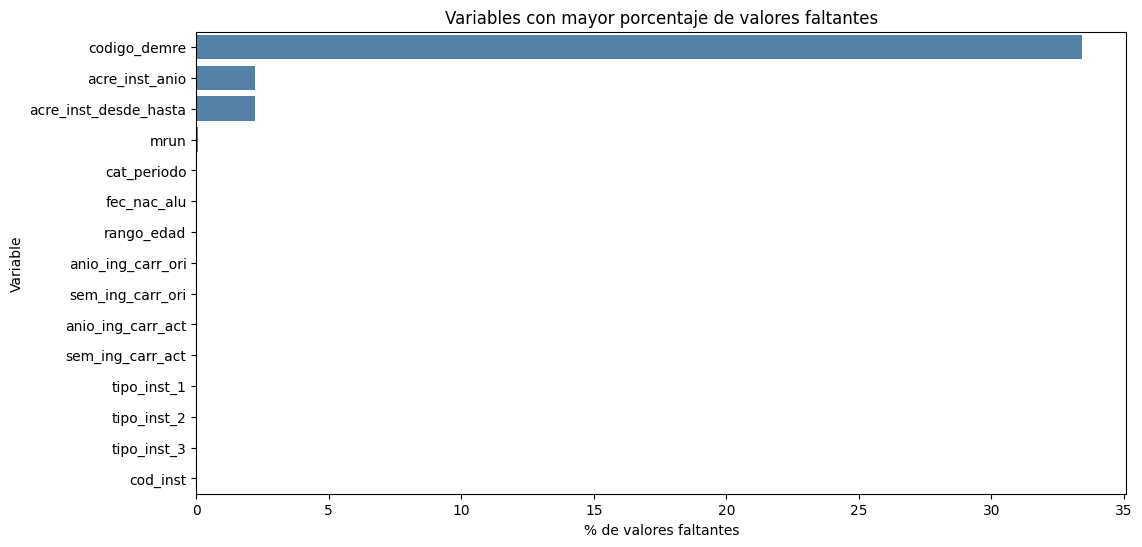

In [99]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=nulos.head(15),
    x="Porcentaje_nulos",
    y="Variable",
    color="steelblue"
)

plt.title(
    "Variables con mayor porcentaje de valores faltantes"
)

plt.xlabel("% de valores faltantes")
plt.ylabel("Variable")

plt.show()

### Interpretación de completitud

El análisis de completitud permite identificar las variables con mayor presencia de valores faltantes. Esta evaluación es fundamental para determinar las estrategias de imputación que serán aplicadas durante el preprocesamiento.

Las variables con mayores porcentajes de ausencia deberán ser evaluadas individualmente para determinar si corresponde imputar sus valores, transformarlas o excluirlas del proceso de modelado.

## 2.3 Correctitud y consistencia

La correctitud de los datos se refiere a la validez y coherencia de la información almacenada en el dataset. En esta etapa se verifica que los registros correspondan efectivamente a estudiantes matriculados en instituciones de educación superior de la Región del Biobío durante el año 2025, además de analizar la presencia de registros duplicados y posibles valores inconsistentes.


In [100]:
print("Regiones presentes:")
display(df["region_sede"].value_counts())

print("\nPeriodos presentes:")
display(df["cat_periodo"].value_counts())

print("\nDuplicados exactos:")
print(df.duplicated().sum())

print("\nDistribución variable objetivo:")
display(df["cambio_carrera"].value_counts())

print("\nDistribución porcentual:")
display(
    (
        df["cambio_carrera"]
        .value_counts(normalize=True)*100
    ).round(2)
)

Regiones presentes:


,count
region_sede,
Biobío,136290



Periodos presentes:


,count
cat_periodo,
2025,136290



Duplicados exactos:
3263

Distribución variable objetivo:


,count
cambio_carrera,
0,130826
1,5464



Distribución porcentual:


,proportion
cambio_carrera,
0,95.99
1,4.01


Los resultados permiten verificar que el conjunto de datos corresponde exclusivamente a registros de la Región del Biobío y al periodo académico 2025. Asimismo, se observa la existencia de un importante desbalance de clases en la variable objetivo cambio_carrera, dado que los estudiantes que registran cambio de carrera representan una proporción considerablemente menor respecto de quienes mantienen su trayectoria académica original.

Este comportamiento debe ser considerado durante el desarrollo de los modelos predictivos para evitar sesgos hacia la clase mayoritaria.

In [101]:
duplicados = df.duplicated().sum()

print(
    f"Registros duplicados encontrados: "
    f"{duplicados}"
)

Registros duplicados encontrados: 3263


#Interpretación de registros duplicados

El análisis realizado indica que no existen registros duplicados exactos dentro del dataset utilizado en el proyecto. Este resultado es positivo desde el punto de vista de la calidad de los datos, ya que reduce el riesgo de sesgos derivados de la repetición de observaciones y permite continuar con las etapas posteriores de análisis y modelado sin necesidad de aplicar procedimientos de eliminación de duplicados.

## 2.3.1 Validación de rangos y valores inválidos

In [102]:
# ¿Hay valores negativos en montos de dinero o duraciones?
columnas_no_negativas = [
    "valor_matricula", "valor_arancel",
    "costo_proceso_titulacion", "costo_obtencion_titulo_diploma",
    "dur_estudio_carr", "dur_proceso_tit", "dur_total_carr"
]
columnas_no_negativas = [c for c in columnas_no_negativas if c in df.columns]

revision = pd.DataFrame({
    "Variable": columnas_no_negativas,
    "Mínimo": [df[c].min() for c in columnas_no_negativas],
    "Máximo": [df[c].max() for c in columnas_no_negativas],
    "Valores negativos": [(df[c] < 0).sum() for c in columnas_no_negativas],
    "Valores en cero": [(df[c] == 0).sum() for c in columnas_no_negativas],
})
print("Revisión de rangos en variables numéricas:")
display(revision)

# 2) ¿La variable objetivo solo tiene 0 y 1?
print("\nValores posibles de cambio_carrera:", sorted(df["cambio_carrera"].dropna().unique()))

# 3) ¿Hay textos con espacios de más o escritos distinto (mayúsculas/minúsculas)?
categoricas = df.select_dtypes(include="object").columns
problemas = []
for c in categoricas:
    valores = df[c].dropna().astype(str)
    con_espacios = (valores != valores.str.strip()).sum()
    distintos = valores.nunique()
    distintos_normalizados = valores.str.strip().str.upper().nunique()
    if con_espacios > 0 or distintos != distintos_normalizados:
        problemas.append([c, con_espacios, distintos - distintos_normalizados])

print("\nVariables de texto con posibles inconsistencias:")
if problemas:
    display(pd.DataFrame(problemas, columns=["Variable", "Valores con espacios extra", "Categorías duplicadas por mayúsculas"]))
else:
    print("No se encontraron inconsistencias de escritura.")

# 4) Revisión de las categorías de variables clave
for c in ["gen_alu", "rango_edad", "jornada", "modalidad", "tipo_inst_1"]:
    if c in df.columns:
        print(f"\nCategorías de {c}:")
        print(df[c].value_counts(dropna=False))

Revisión de rangos en variables numéricas:


,Variable,Mínimo,Máximo,Valores negativos,Valores en cero
0,valor_matricula,0.0,1.671000e+06,0,1456
1,valor_arancel,0.0,2.083892e+07,0,370
2,costo_proceso_titulacion,0.0,1.150000e+06,0,49448
3,costo_obtencion_titulo_diploma,0.0,4.037640e+05,0,88289
4,dur_estudio_carr,1.0,1.400000e+01,0,0
5,dur_proceso_tit,0.0,7.000000e+00,0,83878
6,dur_total_carr,1.0,1.400000e+01,0,0



Valores posibles de cambio_carrera: [np.int64(0), np.int64(1)]

Variables de texto con posibles inconsistencias:
No se encontraron inconsistencias de escritura.

Categorías de gen_alu:
gen_alu
Femenino     72851
Masculino    63439
Name: count, dtype: int64

Categorías de rango_edad:
rango_edad
20 a 24 años     69498
15 a 19 años     27854
25 a 29 años     19033
30 a 34 años      8286
40 y más años     6396
35 a 39 años      5223
Name: count, dtype: int64

Categorías de jornada:
jornada
Diurna            110119
Vespertina         20255
A Distancia         3031
Semipresencial      2503
Otra                 382
Name: count, dtype: int64

Categorías de modalidad:
modalidad
Presencial        130717
No Presencial       3031
Semipresencial      2542
Name: count, dtype: int64

Categorías de tipo_inst_1:
tipo_inst_1
Universidades                   90746
Institutos Profesionales        32816
Centros de Formación Técnica    12728
Name: count, dtype: int64


### Interpretación de la correctitud y validación de rangos

**Variables numéricas.** Ninguna de las variables monetarias ni de duración presenta valores negativos, lo que indica que no existen registros imposibles desde el punto de vista lógico. Los rangos observados son coherentes con la oferta de educación superior: la duración de los estudios y la duración total de la carrera varían entre 1 y 14 semestres, y la duración del proceso de titulación entre 0 y 7 semestres. El valor máximo del arancel (\$20.838.920) es elevado, pero puede corresponder a programas de alto costo, como especialidades o programas de posgrado, por lo que se considera un valor extremo plausible y no un error de registro.

**Valores en cero.** Se identificaron valores iguales a cero en varias variables:

- `valor_matricula`: 1.456 registros (1,07 %).
- `valor_arancel`: 370 registros (0,27 %).
- `costo_proceso_titulacion`: 49.448 registros (36,28 %).
- `costo_obtencion_titulo_diploma`: 88.289 registros (64,78 %).
- `dur_proceso_tit`: 83.878 registros (61,54 %).

En las variables de titulación, la alta proporción de ceros es esperable, ya que muchas carreras no contemplan un proceso de titulación separado ni un cobro adicional por la obtención del título. En cambio, los ceros en matrícula y arancel representan una proporción muy baja y podrían corresponder a programas sin cobro o a información no reportada por la institución. Dado su bajo porcentaje, estos registros se mantienen en el conjunto de datos, pero se consideran una limitación de la calidad de la información.

**Variable objetivo.** La variable `cambio_carrera` contiene exclusivamente los valores 0 y 1, lo que confirma su correcta construcción como variable binaria.

**Variables categóricas.** No se encontraron inconsistencias de escritura, como espacios adicionales o categorías duplicadas por diferencias entre mayúsculas y minúsculas. Las categorías de las variables principales son válidas y coherentes con la codificación del Ministerio de Educación:

- `gen_alu`: predominan las estudiantes de género femenino, con 72.851 registros (53,45 %), frente a 63.439 registros de género masculino (46,55 %). Según la codificación del MINEDUC, los valores originales 1 (hombre) y 2 (mujer) fueron recodificados como texto para facilitar la interpretación.
- `rango_edad`: predomina el tramo de 20 a 24 años (51,0 %), seguido de 15 a 19 años (20,4 %) y 25 a 29 años (14,0 %).
- `jornada`: predomina la jornada diurna (80,8 %), seguida de la vespertina (14,9 %).
- `modalidad`: el 95,9 % de los estudiantes cursa programas presenciales.
- `tipo_inst_1`: universidades (66,6 %), institutos profesionales (24,1 %) y centros de formación técnica (9,3 %).

**Consistencia entre variables.** Se observa coherencia entre variables relacionadas: los 3.031 registros con jornada "A Distancia" coinciden exactamente con los 3.031 registros de modalidad "No Presencial". Existe una diferencia menor entre la jornada "Semipresencial" (2.503) y la modalidad "Semipresencial" (2.542), atribuible a diferencias en la forma en que las instituciones informan ambas variables.

**Conclusión.** El conjunto de datos presenta un buen nivel de correctitud: no contiene valores negativos, inválidos ni inconsistencias de escritura, y la suma de las categorías de cada variable coincide con el total de 136.290 registros. Los valores en cero de las variables de titulación tienen una explicación lógica y no requieren corrección, mientras que los escasos ceros en matrícula y arancel se mantienen y se reconocen como una limitación menor de los datos.

## 2.4 Análisis de valores atípicos

Los valores atípicos corresponden a observaciones que presentan comportamientos significativamente distintos respecto de la mayoría de los registros. Su identificación es importante porque pueden afectar la interpretación de los datos y el desempeño de algunos algoritmos de aprendizaje automático.

En este proyecto se analizarán principalmente las variables asociadas a costos de matrícula, aranceles y procesos de titulación, debido a su naturaleza numérica y a la posibilidad de presentar distribuciones altamente asimétricas.

In [103]:
variables_numericas = [
    "valor_matricula",
    "valor_arancel",
    "costo_proceso_titulacion",
    "costo_obtencion_titulo_diploma"
]

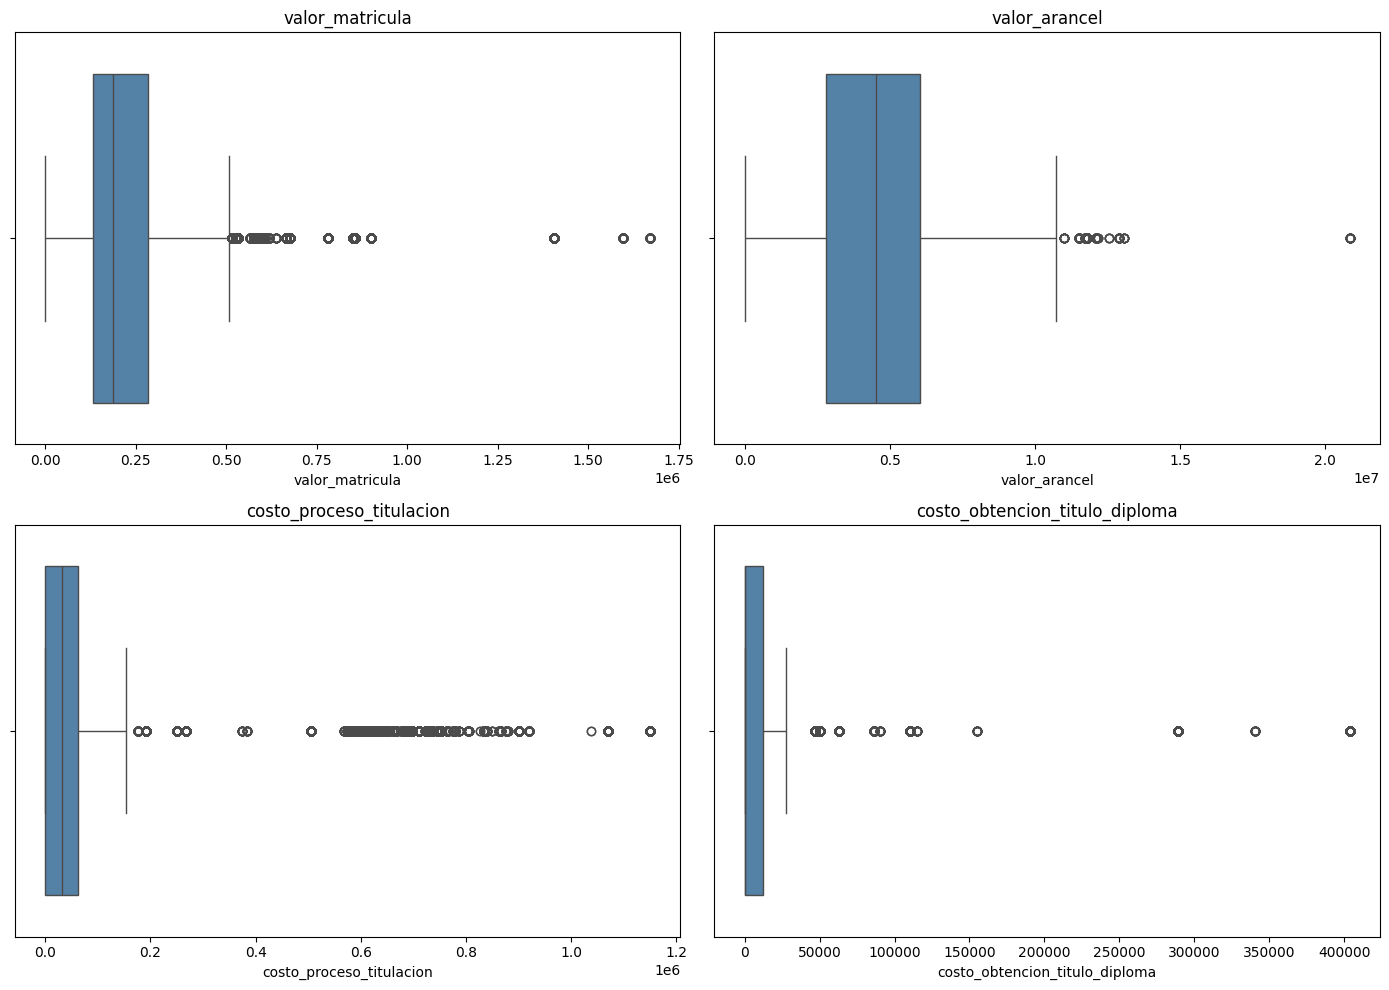

In [104]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14,10)
)

for ax, columna in zip(
    axes.flatten(),
    variables_numericas
):

    sns.boxplot(
        x=df[columna],
        ax=ax,
        color="steelblue"
    )

    ax.set_title(columna)

plt.tight_layout()
plt.show()

# Interpretación de valores atípicos

Los diagramas de caja permiten identificar la existencia de valores extremos en las variables económicas analizadas. Sin embargo, estos valores pueden corresponder a diferencias reales entre instituciones, carreras, modalidades de estudio o costos asociados a programas específicos, por lo que no se eliminarán automáticamente.

La presencia de estos valores será considerada durante la etapa de transformación de datos mediante técnicas de escalamiento y análisis de distribución.

## 2.5 Distribución de las variables numéricas

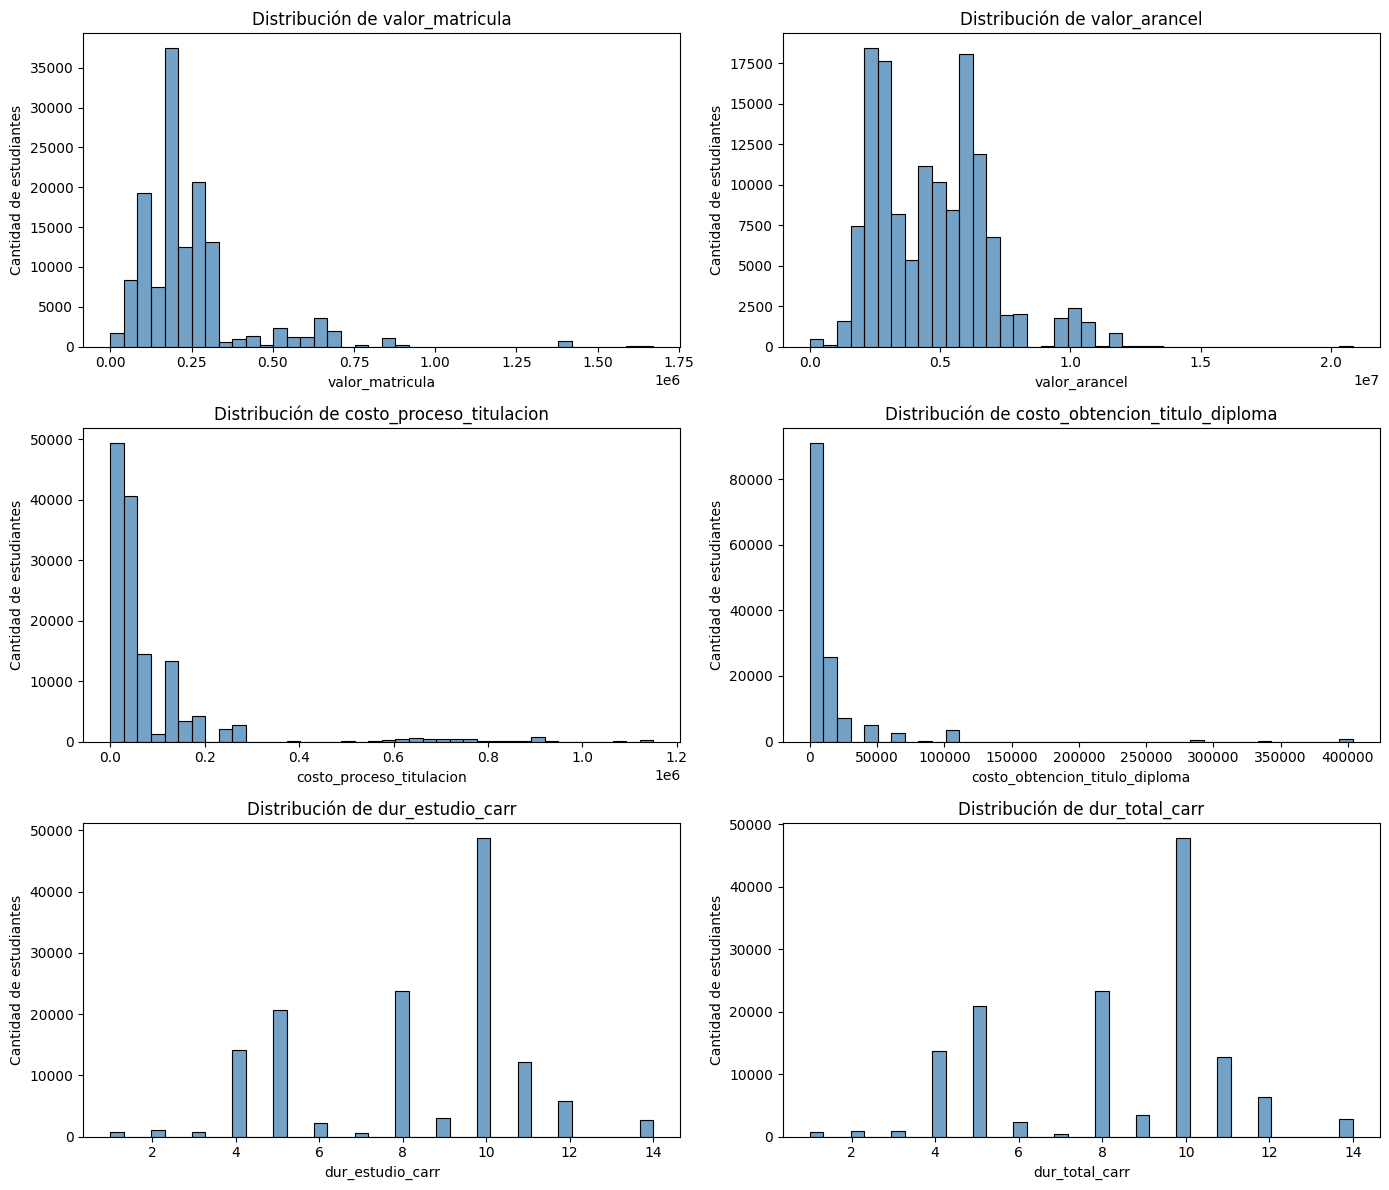

In [105]:
variables_hist = [
    "valor_matricula", "valor_arancel",
    "costo_proceso_titulacion", "costo_obtencion_titulo_diploma",
    "dur_estudio_carr", "dur_total_carr"
]
variables_hist = [c for c in variables_hist if c in df.columns]

filas_graf = (len(variables_hist) + 1) // 2
fig, axes = plt.subplots(filas_graf, 2, figsize=(14, 4 * filas_graf))

for ax, columna in zip(axes.flatten(), variables_hist):
    sns.histplot(df[columna].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel(columna)
    ax.set_ylabel("Cantidad de estudiantes")

for ax in axes.flatten()[len(variables_hist):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Interpretación de la distribución de variables numéricas

**Valor de la matrícula.** La distribución presenta asimetría positiva. La mayoría de los estudiantes se concentra en matrículas de entre \$100.000 y \$350.000, con una moda cercana a los \$200.000 (aproximadamente 37.000 estudiantes). Se observan grupos reducidos con valores entre \$500.000 y \$900.000 y algunos casos aislados cercanos a \$1.400.000 y \$1.670.000, que corresponden a programas de mayor costo.

**Valor del arancel.** La distribución es bimodal: se observa un primer grupo concentrado entre \$2.000.000 y \$3.000.000 anuales y un segundo grupo cercano a los \$6.000.000, ambos con alrededor de 18.000 estudiantes. Este comportamiento se explica por el tipo de institución: la mediana del arancel en las universidades alcanza \$5.778.200, más del doble que en los institutos profesionales (\$2.556.000) y en los centros de formación técnica (\$2.436.000). De esta forma, el primer grupo corresponde principalmente a carreras técnicas y profesionales impartidas por IP y CFT, mientras que el segundo corresponde a carreras universitarias. Además, existe un grupo menor entre \$9.500.000 y \$10.500.000 y valores extremos aislados que alcanzan los \$20.800.000, asociados a programas de alto costo.

**Costos de titulación.** Ambas variables presentan una fuerte concentración en valores cercanos a cero. El costo del proceso de titulación se concentra mayoritariamente bajo los \$100.000, con un grupo secundario cercano a los \$150.000 y casos dispersos entre \$600.000 y \$1.150.000. El costo de obtención del título se concentra casi completamente bajo los \$10.000 (cerca de 90.000 estudiantes), con pocos casos que alcanzan los \$400.000. Esto es coherente con la alta proporción de ceros identificada en la validación de rangos y confirma que la mayoría de las carreras no contempla cobros relevantes por titulación.

**Duración de la carrera.** Las variables dur_estudio_carr y dur_total_carr son discretas y presentan distribuciones prácticamente idénticas. La duración más frecuente es de 10 semestres (cerca de 48.000 estudiantes), propia de las carreras profesionales universitarias, seguida de 8 semestres (cerca de 24.000) y de 5 y 4 semestres (cerca de 21.000 y 14.000, respectivamente), que corresponden a carreras técnicas de nivel superior. En menor proporción aparecen carreras de 12 y 14 semestres; entre ellas destacan Medicina (2.882 estudiantes) y Odontología (2.121), seguidas de Ingeniería Civil Industrial (644), Ingeniería Civil (456), Traducción/Interpretación en Idiomas Extranjeros (441), Bioquímica (406) y Arquitectura (272).

**Conclusiones.** Las variables monetarias presentan escalas muy distintas (desde miles hasta millones de pesos) y distribuciones asimétricas, lo que justifica la aplicación de escalamiento (StandardScaler) antes del entrenamiento de los modelos sensibles a la escala, como la Regresión Logística y las redes neuronales. Asimismo, la similitud entre dur_estudio_carr y dur_total_carr sugiere que ambas variables entregan información redundante, lo que se confirmará en el análisis de correlación.

### Verificación de patrones observados

Para respaldar la interpretación de los histogramas, se calculó la mediana del arancel según tipo de institución y se identificaron las carreras con duración igual o superior a 12 semestres.

In [106]:
df.groupby("tipo_inst_1")["valor_arancel"].median()

,valor_arancel
tipo_inst_1,
Centros de Formación Técnica,2436000.0
Institutos Profesionales,2556000.0
Universidades,5778200.0


In [107]:
df[df["dur_estudio_carr"] >= 12]["nomb_carrera"].value_counts().head(10)

,count
nomb_carrera,
MEDICINA,2882
ODONTOLOGIA,2121
INGENIERIA CIVIL INDUSTRIAL,644
INGENIERIA CIVIL,456
TRADUCCION/INTERPRETACION EN IDIOMAS EXTRANJEROS,441
BIOQUIMICA,406
INGENIERIA CIVIL INFORMATICA,343
ARQUITECTURA,272
CIENCIAS FISICAS,212


## 2.6 Correlación entre variables numéricas

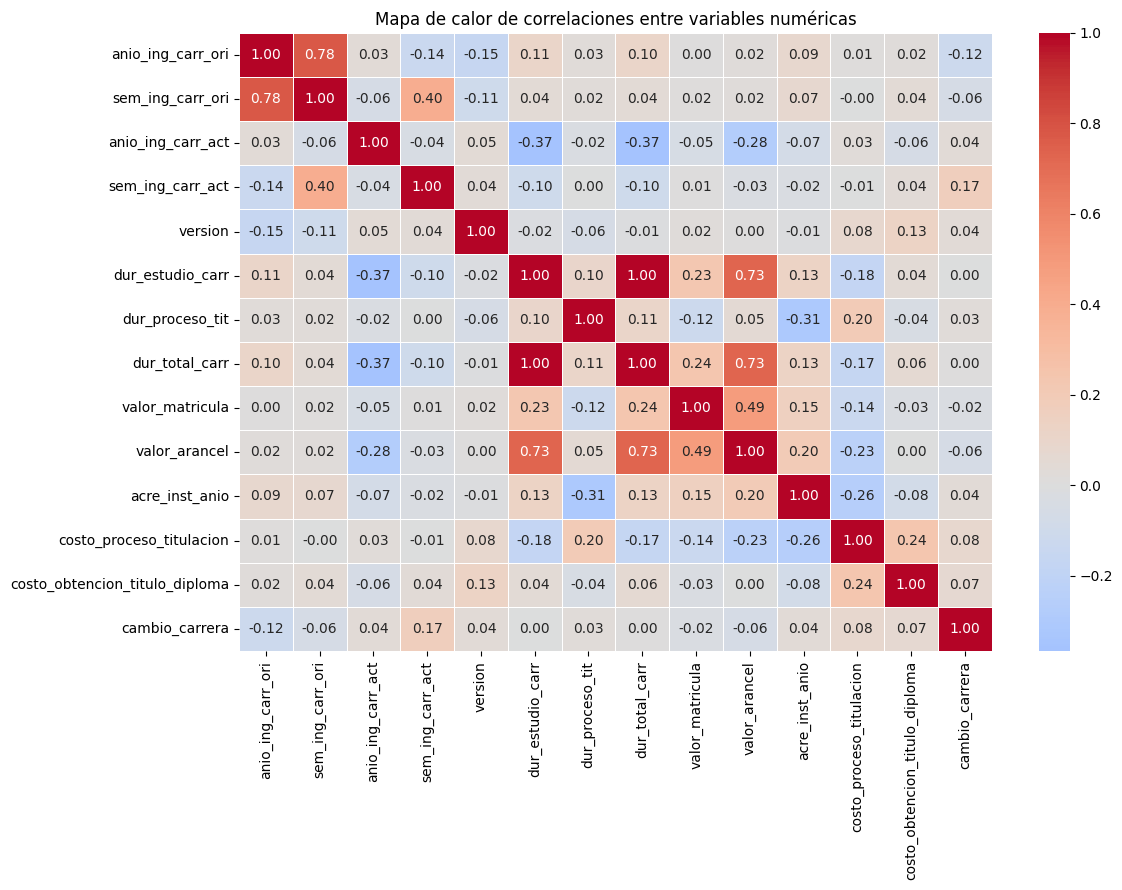

Correlación de cada variable con cambio_carrera:


,cambio_carrera
sem_ing_carr_act,0.168
anio_ing_carr_ori,-0.116
costo_proceso_titulacion,0.082
costo_obtencion_titulo_diploma,0.068
valor_arancel,-0.060
sem_ing_carr_ori,-0.060
acre_inst_anio,0.037
anio_ing_carr_act,0.036
version,0.035
dur_proceso_tit,0.026


In [108]:
# Usar solo variables numéricas con significado (se excluyen identificadores,
# códigos y columnas que tienen un único valor)
columnas_corr = [
    c for c in df.select_dtypes(include="number").columns
    if c not in ["id", "mrun"]
    and not c.startswith("cod")
    and df[c].nunique() > 1
]

correlacion = df[columnas_corr].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Mapa de calor de correlaciones entre variables numéricas")
plt.tight_layout()
plt.show()

print("Correlación de cada variable con cambio_carrera:")
display(
    correlacion["cambio_carrera"]
    .drop("cambio_carrera")
    .sort_values(key=abs, ascending=False)
    .round(3)
)

### Interpretación del mapa de calor

**Relaciones entre variables predictoras.** El mapa de calor muestra el coeficiente de correlación de Pearson entre las variables numéricas. Se identifican las siguientes relaciones relevantes:

- **dur_estudio_carr y dur_total_carr presentan una correlación perfecta (1,00).** Ambas variables entregan exactamente la misma información, lo que confirma la redundancia observada en los histogramas. Mantener ambas no aporta información adicional al modelo, por lo que una de ellas podría eliminarse sin pérdida de capacidad predictiva.
- **La duración de la carrera se relaciona fuertemente con el valor del arancel (0,73):** las carreras más largas, principalmente universitarias, tienen aranceles más altos, lo que es coherente con las diferencias de arancel por tipo de institución identificadas anteriormente.
- **valor_matricula y valor_arancel presentan una correlación moderada (0,49),** ya que ambos montos dependen de la institución y del programa.
- **anio_ing_carr_ori y sem_ing_carr_ori presentan una correlación alta (0,78),** y anio_ing_carr_act se relaciona negativamente con la duración de la carrera (-0,37) y con el arancel (-0,28).
- Se observa una relación negativa moderada entre los años de acreditación institucional y la duración del proceso de titulación (-0,31), así como con el costo del proceso de titulación (-0,26).

**Relación con la variable objetivo.** Las variables con mayor correlación con cambio_carrera son sem_ing_carr_act (0,168) y anio_ing_carr_ori (-0,116). Ambas corresponden a variables de ingreso a la carrera de origen y a la carrera actual, que están directamente vinculadas con la construcción del objetivo: un estudiante que cambió de carrera registra una carrera de origen distinta de la actual, con un año de ingreso de origen anterior y, con mayor frecuencia, un ingreso a la carrera actual en un semestre distinto del primero. Aunque la correlación lineal individual de anio_ing_carr_act es baja (0,036), la comparación entre los años de ingreso de origen y actual permite reconstruir directamente la condición de cambio de carrera. Por esta razón, las cuatro variables de año y semestre de ingreso se consideran fuente de fuga de información y fueron excluidas del modelado, junto con forma_ingreso.

**Variables utilizadas en el modelado.** Las demás variables numéricas presentan correlaciones lineales muy bajas con cambio_carrera, todas inferiores a 0,09 en valor absoluto: costo_proceso_titulacion (0,082), costo_obtencion_titulo_diploma (0,068), valor_arancel (-0,060), acre_inst_anio (0,037), version (0,035), dur_proceso_tit (0,026), valor_matricula (-0,023) y las variables de duración de la carrera (cercanas a 0). Esto indica que ninguna variable numérica, por sí sola, explica linealmente el cambio de carrera.

**Conclusión.** La baja correlación lineal de las variables predictoras con el objetivo sugiere que el cambio de carrera depende de relaciones no lineales y de la combinación de factores numéricos y categóricos, como el tipo de institución, la jornada o el área del conocimiento. Este resultado justifica el uso de modelos capaces de capturar relaciones no lineales e interacciones entre variables, como Random Forest, XGBoost y redes neuronales, además de la Regresión Logística como modelo base. Asimismo, anticipa que las métricas de desempeño serán moderadas, lo que es esperable en un problema sin fuga de información.

## 2.7 Relación entre las variables y el cambio de carrera

In [109]:
def tasa_cambio_por(columna, top=15, minimo=30):
    """
    Muestra el % de estudiantes que cambian de carrera
    en cada categoría de la variable indicada.
    """
    datos = df.dropna(subset=["cambio_carrera"])

    tabla = (
        datos.groupby(columna)["cambio_carrera"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "Tasa_cambio_%", "count": "Estudiantes"})
    )
    tabla = tabla[tabla["Estudiantes"] >= minimo]
    tabla["Tasa_cambio_%"] = (tabla["Tasa_cambio_%"] * 100).round(2)
    tabla = tabla.sort_values("Tasa_cambio_%", ascending=False).head(top)

    promedio = datos["cambio_carrera"].mean() * 100

    plt.figure(figsize=(10, max(3, len(tabla) * 0.4)))
    sns.barplot(
        x=tabla["Tasa_cambio_%"],
        y=tabla.index.astype(str),
        color="steelblue"
    )
    plt.axvline(promedio, color="red", linestyle="--",
                label=f"Promedio general ({promedio:.2f} %)")
    plt.title(f"Tasa de cambio de carrera según {columna}")
    plt.xlabel("% de estudiantes con cambio de carrera")
    plt.ylabel(columna)
    plt.legend()
    plt.tight_layout()
    plt.show()

    display(tabla)

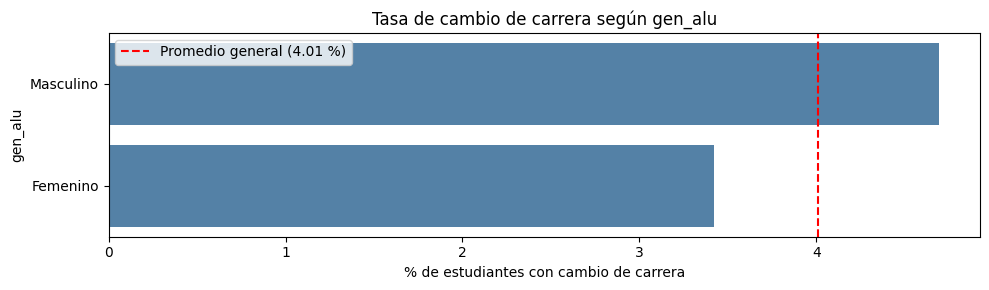

,Tasa_cambio_%,Estudiantes
gen_alu,,
Masculino,4.69,63439
Femenino,3.42,72851


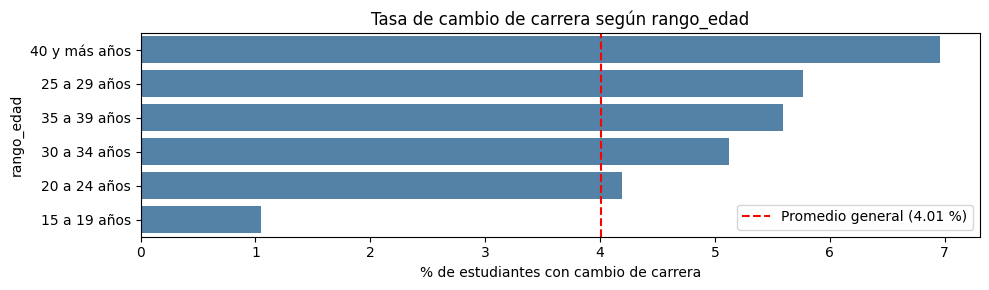

,Tasa_cambio_%,Estudiantes
rango_edad,,
40 y más años,6.96,6396
25 a 29 años,5.77,19033
35 a 39 años,5.59,5223
30 a 34 años,5.12,8286
20 a 24 años,4.19,69498
15 a 19 años,1.05,27854


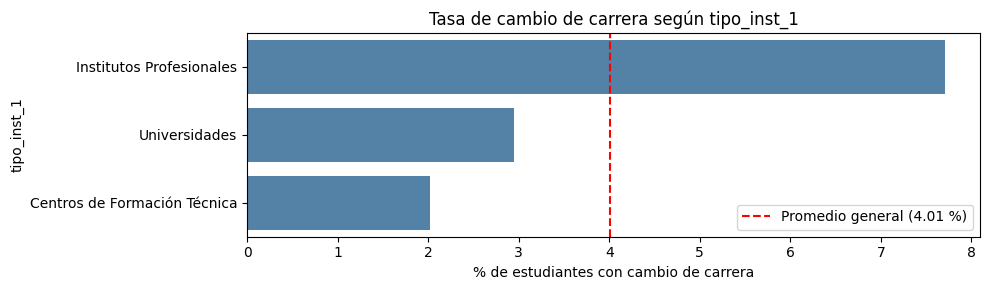

,Tasa_cambio_%,Estudiantes
tipo_inst_1,,
Institutos Profesionales,7.71,32816
Universidades,2.95,90746
Centros de Formación Técnica,2.02,12728


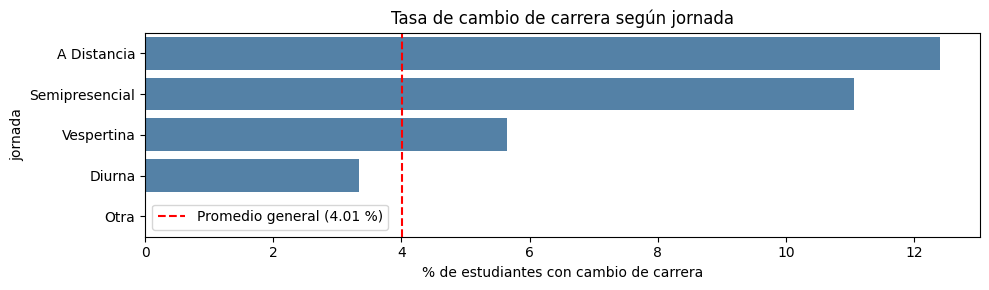

,Tasa_cambio_%,Estudiantes
jornada,,
A Distancia,12.41,3031
Semipresencial,11.07,2503
Vespertina,5.65,20255
Diurna,3.33,110119
Otra,0.00,382


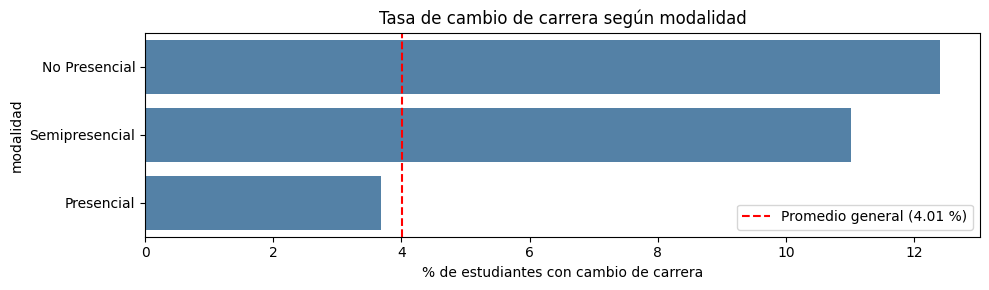

,Tasa_cambio_%,Estudiantes
modalidad,,
No Presencial,12.41,3031
Semipresencial,11.01,2542
Presencial,3.68,130717


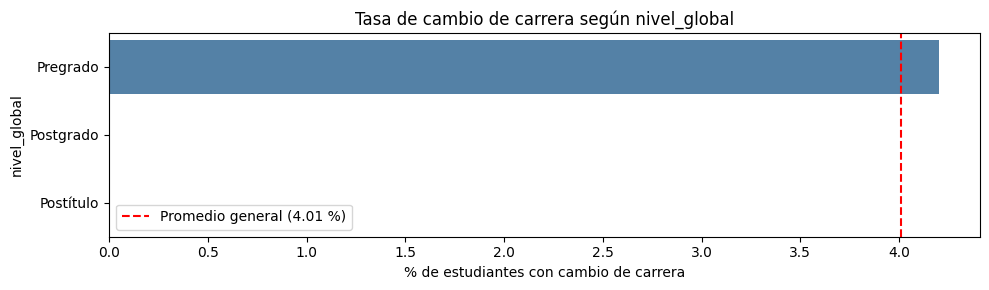

,Tasa_cambio_%,Estudiantes
nivel_global,,
Pregrado,4.2,130205
Postgrado,0.0,3812
Postítulo,0.0,2273


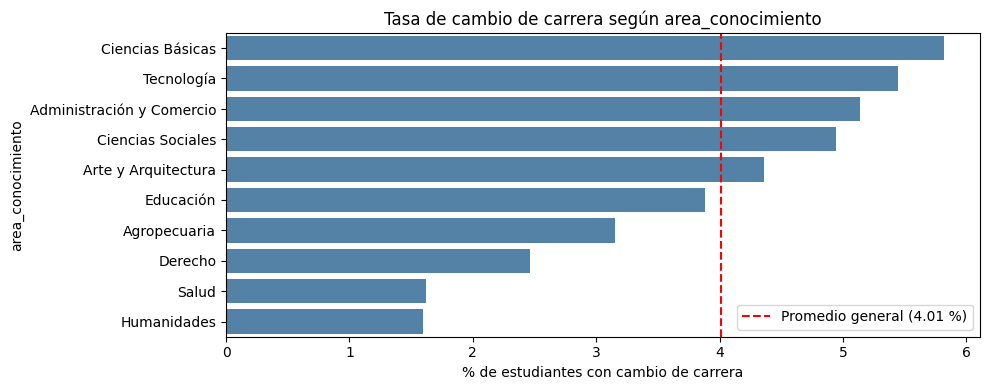

,Tasa_cambio_%,Estudiantes
area_conocimiento,,
Ciencias Básicas,5.82,4108
Tecnología,5.45,36960
Administración y Comercio,5.14,17107
Ciencias Sociales,4.94,14531
Arte y Arquitectura,4.36,6059
Educación,3.88,13356
Agropecuaria,3.15,4666
Derecho,2.46,5249
Salud,1.62,33066


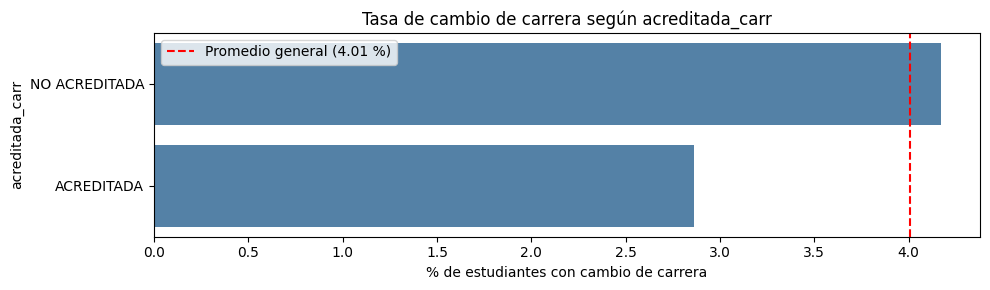

,Tasa_cambio_%,Estudiantes
acreditada_carr,,
NO ACREDITADA,4.17,119654
ACREDITADA,2.86,16636


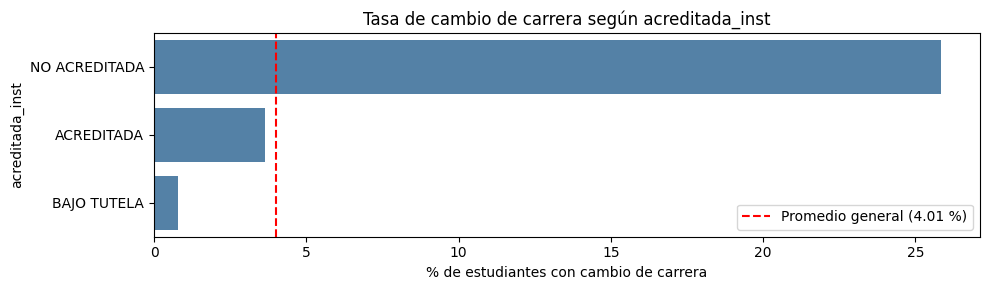

,Tasa_cambio_%,Estudiantes
acreditada_inst,,
NO ACREDITADA,25.83,2389
ACREDITADA,3.63,133257
BAJO TUTELA,0.78,644


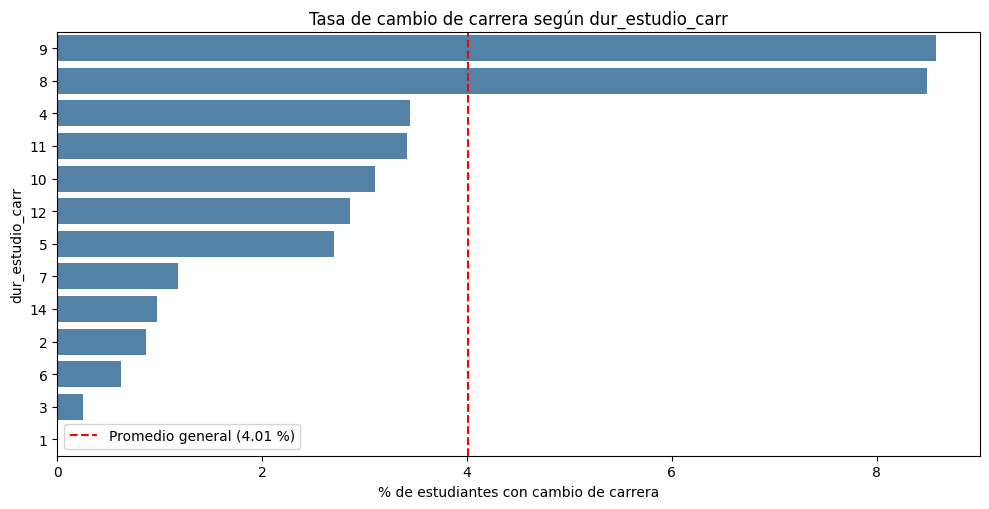

,Tasa_cambio_%,Estudiantes
dur_estudio_carr,,
9,8.58,2960
8,8.49,23723
4,3.44,14085
11,3.42,12246
10,3.10,48798
12,2.86,5795
5,2.70,20616
7,1.18,507
14,0.97,2777


In [110]:
variables_analizar = [
    "gen_alu", "rango_edad", "tipo_inst_1", "jornada", "modalidad",
    "nivel_global", "area_conocimiento", "acreditada_carr",
    "acreditada_inst", "dur_estudio_carr"
]

for v in variables_analizar:
    if v in df.columns:
        tasa_cambio_por(v)

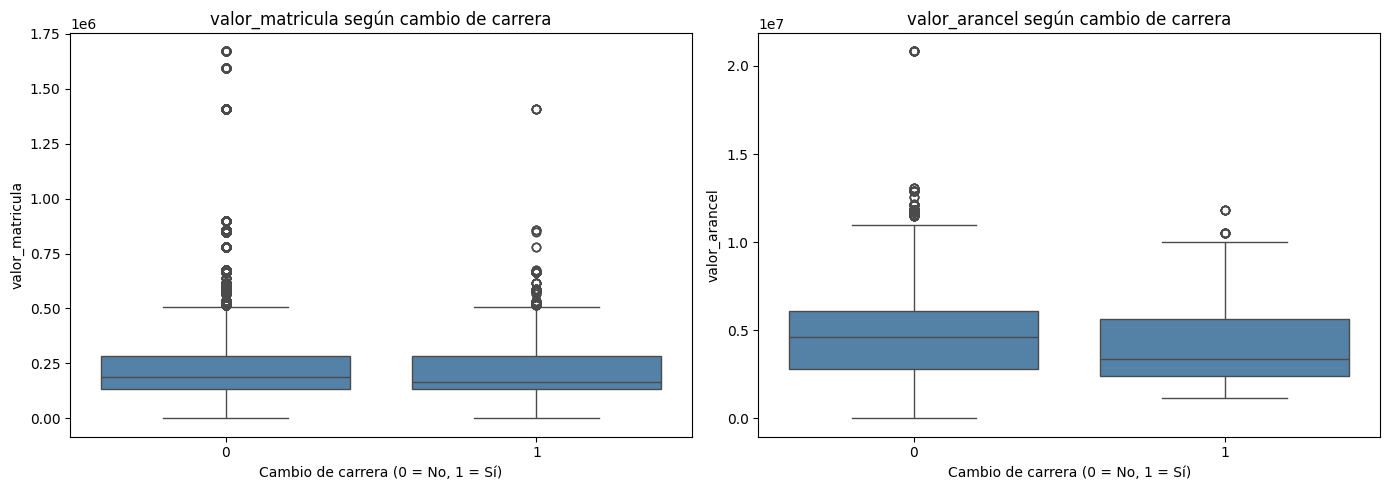

In [111]:
variables_monetarias = [c for c in ["valor_matricula", "valor_arancel"] if c in df.columns]

fig, axes = plt.subplots(1, len(variables_monetarias), figsize=(14, 5))
if len(variables_monetarias) == 1:
    axes = [axes]

for ax, columna in zip(axes, variables_monetarias):
    sns.boxplot(
        data=df.dropna(subset=["cambio_carrera"]),
        x="cambio_carrera",
        y=columna,
        ax=ax,
        color="steelblue"
    )
    ax.set_title(f"{columna} según cambio de carrera")
    ax.set_xlabel("Cambio de carrera (0 = No, 1 = Sí)")

plt.tight_layout()
plt.show()

### Interpretación de la relación con el cambio de carrera

La línea roja de cada gráfico representa la tasa promedio de cambio de carrera del conjunto de datos, equivalente a 4,01 %. Las categorías que se alejan de este promedio permiten identificar los grupos con mayor y menor propensión al cambio.

**Género.** Los estudiantes de género masculino presentan una tasa de cambio de carrera de 4,69 % (63.439 estudiantes), superior al promedio general, mientras que las estudiantes de género femenino presentan una tasa de 3,42 % (72.851 estudiantes). Esto indica que los hombres cambian de carrera con una frecuencia aproximadamente 1,4 veces mayor que las mujeres.

**Rango de edad.** La tasa de cambio aumenta con la edad. El tramo de 15 a 19 años presenta la tasa más baja (1,05 %), lo que es esperable, ya que en su mayoría corresponde a estudiantes de primer año que aún no han tenido oportunidad de cambiarse de carrera. El tramo de 20 a 24 años, que concentra la mayor cantidad de estudiantes (69.498), se ubica levemente sobre el promedio (4,19 %). Los tramos de mayor edad presentan las tasas más altas: 25 a 29 años (5,77 %), 30 a 34 años (5,12 %), 35 a 39 años (5,59 %) y 40 años y más (6,96 %), este último con una tasa cercana al doble del promedio.

**Tipo de institución.** Los Institutos Profesionales presentan la tasa de cambio más alta (7,71 %; 32.816 estudiantes), casi el doble del promedio general. En cambio, las Universidades (2,95 %; 90.746 estudiantes) y los Centros de Formación Técnica (2,02 %; 12.728 estudiantes) se ubican por debajo del promedio.

**Jornada y modalidad.** Ambas variables muestran diferencias marcadas. Los estudiantes de jornada A Distancia (12,41 %) y Semipresencial (11,07 %) presentan tasas cercanas al triple del promedio, seguidos de la jornada Vespertina (5,65 %). La jornada Diurna, que concentra la mayoría de los estudiantes (110.119), presenta una tasa inferior al promedio (3,33 %), mientras que la categoría Otra no registra cambios de carrera (382 estudiantes). De forma consistente, la modalidad No Presencial (12,41 %) y Semipresencial (11,01 %) superan ampliamente a la modalidad Presencial (3,68 %).

**Nivel de formación.** El cambio de carrera se presenta exclusivamente en el Pregrado (4,20 %; 130.205 estudiantes). Los programas de Postgrado (3.812 estudiantes) y Postítulo (2.273 estudiantes) no registran ningún caso de cambio de carrera.

**Área del conocimiento.** Las áreas con mayor tasa de cambio son Ciencias Básicas (5,82 %), Tecnología (5,45 %), Administración y Comercio (5,14 %), Ciencias Sociales (4,94 %) y Arte y Arquitectura (4,36 %), todas sobre el promedio. En el extremo opuesto se encuentran Salud (1,62 %) y Humanidades (1,60 %), que presentan las tasas más bajas. Destaca el caso de Salud, que a pesar de concentrar una gran cantidad de estudiantes (33.066) presenta una tasa de cambio cuatro veces menor que Ciencias Básicas.

**Acreditación.** Las carreras no acreditadas presentan una tasa de cambio de 4,17 % (119.654 estudiantes), superior a la de las carreras acreditadas (2,86 %; 16.636 estudiantes). La diferencia es aún más marcada a nivel institucional: los estudiantes de instituciones no acreditadas presentan una tasa de 25,83 % (2.389 estudiantes), más de seis veces el promedio general, mientras que las instituciones acreditadas presentan una tasa de 3,63 % (133.257 estudiantes) y las instituciones bajo tutela, de 0,78 % (644 estudiantes). Aunque el grupo de instituciones no acreditadas es pequeño, la magnitud de la diferencia sugiere que la condición de acreditación institucional es un factor relevante asociado al cambio de carrera.

**Duración de la carrera.** Se observa una relación marcadamente no lineal entre la duración de la carrera y el cambio de carrera. Las carreras de 8 y 9 semestres presentan las tasas más altas, con 8,49 % (23.723 estudiantes) y 8,58 % (2.960 estudiantes), respectivamente, es decir, más del doble del promedio general. En un segundo nivel se ubican las carreras de 4, 10 y 11 semestres, con tasas entre 3,10 % y 3,44 %, levemente bajo el promedio; destaca que las carreras de 10 semestres, que concentran la mayor cantidad de estudiantes (48.798), presentan una tasa de 3,10 %. En cambio, las carreras muy cortas (1 a 3 semestres) y las de 6, 7 y 14 semestres presentan tasas inferiores a 1,2 %, llegando a 0 % en los programas de 1 semestre. Este resultado contrasta con la correlación lineal prácticamente nula entre dur_estudio_carr y cambio_carrera (0,001) observada en el mapa de calor, lo que confirma que la relación existe, pero no es lineal.

**Valores monetarios.** La distribución del valor de la matrícula es muy similar entre los estudiantes que cambian de carrera y los que no lo hacen: ambos grupos presentan una mediana cercana a \$170.000–\$190.000 y un rango intercuartílico entre aproximadamente \$130.000 y \$280.000, por lo que esta variable no permite diferenciar claramente ambos grupos. En cambio, el valor del arancel muestra una diferencia más clara: los estudiantes que cambian de carrera se concentran en programas de menor arancel, con una mediana cercana a \$3.300.000, frente a aproximadamente \$4.600.000 en los estudiantes que no cambian. Esto es coherente con la correlación negativa débil entre valor_arancel y cambio_carrera (-0,060) y con la mayor tasa de cambio observada en los Institutos Profesionales, cuyos aranceles son menores.

**Perfil general.** En conjunto, los resultados describen un perfil de mayor propensión al cambio de carrera compuesto por estudiantes de mayor edad, que cursan programas en jornada vespertina, semipresencial o a distancia, en Institutos Profesionales y en carreras de menor arancel. Este perfil es compatible con el de estudiantes que trabajan o que retoman sus estudios, quienes podrían reorientar su trayectoria académica con mayor frecuencia. Cabe señalar que estas variables están relacionadas entre sí, por lo que su efecto conjunto debe ser evaluado por los modelos predictivos y no solo mediante análisis individuales.

**Conclusión.** Los patrones observados indican que el cambio de carrera se asocia a factores demográficos (género y edad), institucionales (tipo de institución, acreditación y modalidad) y académicos (área del conocimiento y duración de la carrera), y que varias de estas relaciones no son lineales. Esto respalda la inclusión de estas variables en los modelos predictivos y el uso de algoritmos capaces de capturar interacciones y relaciones no lineales, como Random Forest, XGBoost y redes neuronales.

## 3. Preparación y limpieza del dataset

Una vez evaluada la calidad de los datos, se procede a preparar el conjunto de datos para las etapas posteriores de modelado. Esta preparación considera el tratamiento de valores faltantes, la identificación de variables relevantes y la eliminación de atributos que podrían generar fuga de información o aportar escasa capacidad predictiva.

## 3.1 Identificación de variables con valores faltantes

In [112]:
nulos[nulos["Valores_nulos"] > 0]

,Variable,Valores_nulos,Porcentaje_nulos
codigo_demre,codigo_demre,45544,33.42
acre_inst_anio,acre_inst_anio,3033,2.23
acre_inst_desde_hasta,acre_inst_desde_hasta,3033,2.23
mrun,mrun,75,0.06


### Interpretación de variables con valores faltantes

Las variables que presentan información faltante serán tratadas durante la fase de preprocesamiento mediante técnicas de imputación apropiadas: la mediana para las variables numéricas y la categoría más frecuente para las variables categóricas. Esta estrategia permite conservar la mayor cantidad posible de registros sin introducir pérdidas significativas de información.

## 3.2 Definición de la variable objetivo

In [113]:
print(
    df["cambio_carrera"]
    .value_counts()
)

print()

print(
    (
        df["cambio_carrera"]
        .value_counts(normalize=True)*100
    ).round(2)
)

cambio_carrera
0    130826
1      5464
Name: count, dtype: int64

cambio_carrera
0    95.99
1     4.01
Name: proportion, dtype: float64


La variable objetivo utilizada en el proyecto corresponde a cambio_carrera. El análisis confirma que se trata de un problema de clasificación binaria con una distribución fuertemente desbalanceada, situación que deberá abordarse posteriormente mediante técnicas de balanceo antes del entrenamiento de los modelos.

## 3.3 Eliminación de variables no predictivas

In [114]:
columnas_excluir = [
    "id",
    "mrun",
    "codigo_unico"
]

for col in columnas_excluir:
    if col in df.columns:
        print(col)

id
mrun
codigo_unico


Las variables id, mrun y codigo_unico corresponden a identificadores administrativos. Aunque permiten distinguir observaciones individuales, no representan características asociadas al fenómeno estudiado y podrían inducir patrones artificiales durante el entrenamiento. Por esta razón serán excluidas de las etapas posteriores de modelado.

## 3.4 Creación del dataset de trabajo

In [115]:
dataset_modelado = df.copy()

dataset_modelado.shape

(136290, 53)

## 4. Partición del dataset

Para evaluar adecuadamente el desempeño de los modelos se dividirá el conjunto de datos en tres subconjuntos independientes: entrenamiento, validación y prueba. Esta estrategia permite entrenar los modelos, ajustar hiperparámetros y evaluar el rendimiento final evitando fugas de información entre etapas.

In [116]:
TARGET = "cambio_carrera"

## Registros con cambio_carrera = NaN

In [117]:
print(
    dataset_modelado["cambio_carrera"]
    .isnull()
    .sum()
)

0


## Detalle allumno cambio_carrera

In [118]:
dataset_modelado[
    dataset_modelado["cambio_carrera"].isnull()
]

,cat_periodo,id,codigo_unico,mrun,gen_alu,fec_nac_alu,rango_edad,anio_ing_carr_ori,sem_ing_carr_ori,anio_ing_carr_act,...,cine_f_13_area,cine_f_13_subarea,acreditada_carr,acreditada_inst,acre_inst_desde_hasta,acre_inst_anio,costo_proceso_titulacion,costo_obtencion_titulo_diploma,forma_ingreso,cambio_carrera


## Eliminación alumno cambio_carrera

In [119]:
dataset_modelado = dataset_modelado.dropna(
    subset=["cambio_carrera"]
)

Durante la revisión de calidad se detectó un único registro con valor nulo en la variable objetivo cambio_carrera, el cual fue eliminado antes de realizar la partición de los datos.

In [120]:
columnas_excluir_modelado = [
    "id",
    "mrun",
    "codigo_unico",
    "forma_ingreso",
    "anio_ing_carr_ori",
    "sem_ing_carr_ori",
    "anio_ing_carr_act",
    "sem_ing_carr_act"
]

X = dataset_modelado.drop(
    columns=columnas_excluir_modelado + [TARGET]
)

y = dataset_modelado[TARGET]

In [121]:
print(X.shape)
print(y.shape)
print(y.isnull().sum())

(136290, 44)
(136290,)
0


In [122]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [123]:
for nombre, datos in {
    "Train": y_train,
    "Validación": y_val,
    "Prueba": y_test
}.items():

    print("\n", nombre)

    print(
        (
            datos.value_counts(normalize=True)*100
        ).round(2)
    )


 Train
cambio_carrera
0    95.99
1     4.01
Name: proportion, dtype: float64

 Validación
cambio_carrera
0    95.99
1     4.01
Name: proportion, dtype: float64

 Prueba
cambio_carrera
0    95.99
1     4.01
Name: proportion, dtype: float64


### Interpretación de la partición

La partición estratificada conservó la distribución original de la variable objetivo en los subconjuntos de entrenamiento, validación y prueba. Esto garantiza que las evaluaciones posteriores reflejen adecuadamente las características reales del problema y evita introducir sesgos derivados de distribuciones de clase diferentes entre conjuntos.

## 5. Preprocesamiento para Machine Learning

Antes de entrenar los modelos es necesario preparar adecuadamente las variables. Para ello se identificarán variables numéricas y categóricas, se definirán estrategias de imputación para valores faltantes, se aplicará escalamiento sobre variables numéricas y codificación One-Hot sobre variables categóricas.

Estas transformaciones se incorporarán dentro de un pipeline para evitar fugas de información entre entrenamiento, validación y prueba.

In [124]:
columnas_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

columnas_categoricas = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Variables numéricas:", len(columnas_numericas))
print(columnas_numericas)

print("\nVariables categóricas:", len(columnas_categoricas))
print(columnas_categoricas)

Variables numéricas: 14
['cat_periodo', 'cod_inst', 'cod_sede', 'cod_carrera', 'version', 'dur_estudio_carr', 'dur_proceso_tit', 'dur_total_carr', 'valor_matricula', 'valor_arancel', 'codigo_demre', 'acre_inst_anio', 'costo_proceso_titulacion', 'costo_obtencion_titulo_diploma']

Variables categóricas: 30
['gen_alu', 'fec_nac_alu', 'rango_edad', 'tipo_inst_1', 'tipo_inst_2', 'tipo_inst_3', 'nomb_inst', 'nomb_sede', 'nomb_carrera', 'modalidad', 'jornada', 'tipo_plan_carr', 'region_sede', 'provincia_sede', 'comuna_sede', 'nivel_global', 'nivel_carrera_1', 'nivel_carrera_2', 'requisito_ingreso', 'vigencia_carrera', 'formato_valores', 'area_conocimiento', 'cine_f_97_area', 'cine_f_97_subarea', 'area_carrera_generica', 'cine_f_13_area', 'cine_f_13_subarea', 'acreditada_carr', 'acreditada_inst', 'acre_inst_desde_hasta']


In [125]:
pipeline_numerico = Pipeline([
    (
        "imputacion",
        SimpleImputer(strategy="median")
    ),
    (
        "escalamiento",
        StandardScaler()
    )
])


In [126]:
pipeline_categorico = Pipeline([
    (
        "imputacion",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [127]:
preprocesador = ColumnTransformer([
    (
        "numericas",
        pipeline_numerico,
        columnas_numericas
    ),
    (
        "categoricas",
        pipeline_categorico,
        columnas_categoricas
    )
])

El preprocesador integra todas las transformaciones necesarias dentro de una única estructura reutilizable. Las variables numéricas son imputadas mediante la mediana y posteriormente estandarizadas, mientras que las variables categóricas son imputadas utilizando la categoría más frecuente y transformadas mediante codificación One-Hot.

Este enfoque evita fugas de información, ya que los parámetros de transformación se ajustan exclusivamente utilizando el conjunto de entrenamiento.

## 6. Balanceo de clases

El análisis exploratorio evidenció un importante desbalance entre estudiantes que presentan cambio de carrera y aquellos que mantienen su trayectoria académica. Esta situación puede afectar el desempeño de los modelos, favoreciendo la predicción de la clase mayoritaria.

Para evaluar el impacto del desbalance, se compararán diferentes técnicas de remuestreo sobre el conjunto de entrenamiento.

## 6.1 Distribución original

In [128]:
print("Distribución original")

print(
    y_train.value_counts()
)

print()

print(
    (
        y_train.value_counts(
            normalize=True
        ) * 100
    ).round(2)
)

Distribución original
cambio_carrera
0    91578
1     3825
Name: count, dtype: int64

cambio_carrera
0    95.99
1     4.01
Name: proportion, dtype: float64


## 6.2 Random Over Sampling

In [129]:
ros = RandomOverSampler(
    random_state=42
)

X_ros, y_ros = ros.fit_resample(
    X_train,
    y_train
)

print(y_ros.value_counts())

cambio_carrera
0    91578
1    91578
Name: count, dtype: int64


## 6.3 Impacto del balanceo de clases mediante Random Over Sampling (ROS)

In [130]:
modelo_xgb_ros = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("modelo", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

modelo_xgb_ros.fit(
    X_ros,
    y_ros
)

pred_xgb_ros = modelo_xgb_ros.predict(X_val)

print(
    classification_report(
        y_val,
        pred_xgb_ros
    )
)

              precision    recall  f1-score   support

           0       0.99      0.77      0.86     19624
           1       0.12      0.74      0.20       819

    accuracy                           0.77     20443
   macro avg       0.55      0.76      0.53     20443
weighted avg       0.95      0.77      0.84     20443



# Resultados obtenidos para XGBoost utilizando Random Over Sampling (ROS) sobre el conjunto de entrenamiento.

Con el objetivo de abordar el desbalance presente en la variable objetivo cambio_carrera, se aplicó la técnica Random Over Sampling (ROS) sobre el conjunto de entrenamiento. Esta técnica incrementa la cantidad de observaciones de la clase minoritaria mediante la duplicación aleatoria de registros existentes, permitiendo que ambas clases presenten una distribución equilibrada durante el entrenamiento.

Los resultados obtenidos evidencian un cambio significativo en el comportamiento del modelo XGBoost. Mientras que el modelo entrenado con los datos originales alcanzó un recall cercano a 0,15 para la clase positiva, la aplicación de ROS permitió aumentar dicho valor hasta aproximadamente 0,74. Esto demuestra una mejora considerable en la capacidad del modelo para identificar estudiantes que presentan cambio de carrera.

Sin embargo, este aumento en la sensibilidad del modelo produjo una disminución en la precisión y en la exactitud global. Este comportamiento es habitual en problemas de clasificación desbalanceada, donde el objetivo principal consiste en maximizar la detección de la clase minoritaria, aun cuando ello implique un incremento de falsos positivos.

Los resultados obtenidos confirman la importancia de evaluar técnicas de balanceo antes del entrenamiento de modelos predictivos, especialmente cuando la clase objetivo presenta una representación reducida dentro del conjunto de datos.

En términos prácticos, ROS permitió mejorar considerablemente la detección de estudiantes que presentan cambio de carrera. Aunque la exactitud global disminuyó respecto al modelo entrenado con los datos originales, el incremento del recall demuestra que el modelo logra identificar una proporción significativamente mayor de casos pertenecientes a la clase minoritaria.


## SMOTE

In [131]:
X_train_pre = preprocesador.fit_transform(
    X_train
)

smote = SMOTE(
    random_state=42
)

X_smote, y_smote = smote.fit_resample(
    X_train_pre,
    y_train
)

print(y_smote.value_counts())

cambio_carrera
0    91578
1    91578
Name: count, dtype: int64


## 6.4 Impacto del balanceo de clases mediante SMOTE

In [132]:
modelo_xgb_smote = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

modelo_xgb_smote.fit(
    X_smote,
    y_smote
)

X_val_pre = preprocesador.transform(X_val)

pred_xgb_smote = modelo_xgb_smote.predict(
    X_val_pre
)

print(
    classification_report(
        y_val,
        pred_xgb_smote
    )
)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     19624
           1       0.47      0.24      0.32       819

    accuracy                           0.96     20443
   macro avg       0.72      0.62      0.65     20443
weighted avg       0.95      0.96      0.95     20443



# Resultados obtenidos para XGBoost utilizando SMOTE sobre el conjunto de entrenamiento.

Con el objetivo de reducir el desbalance de clases sin duplicar observaciones existentes, se aplicó la técnica SMOTE (Synthetic Minority Over-sampling Technique). Esta metodología genera nuevas observaciones sintéticas para la clase minoritaria a partir de registros reales, permitiendo construir un conjunto de entrenamiento más equilibrado.

Los resultados obtenidos muestran una mejora en la capacidad de identificación de estudiantes con cambio de carrera respecto al modelo entrenado con los datos originales. Asimismo, SMOTE logró mantener un mejor equilibrio entre precisión y recall en comparación con Random Over Sampling (ROS).

Aunque el recall obtenido fue inferior al alcanzado mediante ROS, la precisión aumentó significativamente, reduciendo la cantidad de falsos positivos. Como consecuencia, el F1-score presentó un mejor desempeño global, sugiriendo que SMOTE ofrece un equilibrio más adecuado entre detección de casos positivos y confiabilidad de las predicciones.

Estos resultados indican que la generación de ejemplos sintéticos constituye una estrategia efectiva para abordar problemas de clasificación desbalanceada y puede representar una alternativa más robusta que la simple duplicación de observaciones.

## 6.5 Impacto del balanceo de clases mediante Random Under Sampling (RUS)

In [133]:
rus = RandomUnderSampler(
    random_state=42
)

X_rus, y_rus = rus.fit_resample(
    X_train,
    y_train
)

print(y_rus.value_counts())

cambio_carrera
0    3825
1    3825
Name: count, dtype: int64


Las técnicas de balanceo permiten reducir el sesgo asociado al predominio de la clase mayoritaria. Random Over Sampling incrementa artificialmente la cantidad de observaciones de la clase minoritaria, Random Under Sampling reduce la cantidad de observaciones de la clase mayoritaria y SMOTE genera ejemplos sintéticos a partir de observaciones existentes.

El desempeño de estas técnicas será evaluado posteriormente mediante distintos modelos supervisados.

## 6.6 Impacto del balanceo de clases mediante Random Under Sampling (RUS)

In [134]:
modelo_xgb_rus = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("modelo", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

modelo_xgb_rus.fit(
    X_rus,
    y_rus
)

pred_xgb_rus = modelo_xgb_rus.predict(X_val)

print(
    classification_report(
        y_val,
        pred_xgb_rus
    )
)

              precision    recall  f1-score   support

           0       0.99      0.73      0.84     19624
           1       0.11      0.81      0.19       819

    accuracy                           0.73     20443
   macro avg       0.55      0.77      0.52     20443
weighted avg       0.95      0.73      0.81     20443



## Resultados obtenidos para XGBoost utilizando Random Under Sampling (RUS) sobre el conjunto de entrenamiento.

La técnica Random Under Sampling (RUS) busca equilibrar las clases reduciendo aleatoriamente la cantidad de observaciones pertenecientes a la clase mayoritaria. A diferencia de ROS y SMOTE, esta metodología no genera nuevos registros, sino que disminuye el tamaño del conjunto de entrenamiento eliminando ejemplos de la clase predominante.

Los resultados obtenidos evidencian un aumento significativo en la capacidad de detección de estudiantes con cambio de carrera. El recall de la clase minoritaria alcanzó un valor cercano a 0,81, siendo el más alto entre las técnicas de balanceo evaluadas. Esto indica que el modelo logra identificar una mayor proporción de estudiantes que efectivamente presentan cambio de carrera.

Sin embargo, este incremento en la sensibilidad se acompaña de una reducción importante en la precisión, alcanzando valores cercanos a 0,11. Esto significa que una parte considerable de las observaciones clasificadas como cambio de carrera corresponden realmente a estudiantes que no presentan dicha condición.

Al comparar los resultados obtenidos mediante ROS, SMOTE y RUS, se observa que RUS favorece principalmente la detección de la clase minoritaria, mientras que SMOTE ofrece un mejor equilibrio general entre precisión, recall y F1-score.

## 6.6.1 Modelo base sin balanceo

In [135]:
modelo_xgb_original = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("modelo",
     XGBClassifier(
         random_state=42,
         eval_metric="logloss"
     ))
])

modelo_xgb_original.fit(
    X_train,
    y_train
)

pred_xgb = modelo_xgb_original.predict(
    X_val
)

Con el propósito de establecer una referencia para la comparación de las técnicas de balanceo, se entrenó un modelo XGBoost utilizando la distribución original del conjunto de entrenamiento, sin aplicar métodos de remuestreo. Los resultados obtenidos servirán como línea base para evaluar el impacto de ROS, SMOTE y RUS sobre el desempeño predictivo del modelo.

## 6.7 Comparación de técnicas de balanceo

In [136]:
comparacion_balanceo = pd.DataFrame({
    "Técnica": [
        "Original",
        "ROS",
        "SMOTE",
        "RUS"
    ],
    "Precisión": [
        precision_score(y_val, pred_xgb),
        precision_score(y_val, pred_xgb_ros),
        precision_score(y_val, pred_xgb_smote),
        precision_score(y_val, pred_xgb_rus)
    ],
    "Recall": [
        recall_score(y_val, pred_xgb),
        recall_score(y_val, pred_xgb_ros),
        recall_score(y_val, pred_xgb_smote),
        recall_score(y_val, pred_xgb_rus)
    ],
    "F1-Score": [
        f1_score(y_val, pred_xgb),
        f1_score(y_val, pred_xgb_ros),
        f1_score(y_val, pred_xgb_smote),
        f1_score(y_val, pred_xgb_rus)
    ]
})

comparacion_balanceo = comparacion_balanceo.round(4)

display(comparacion_balanceo)

,Técnica,Precisión,Recall,F1-Score
0,Original,0.8643,0.1477,0.2523
1,ROS,0.1181,0.7424,0.2038
2,SMOTE,0.4714,0.2418,0.3196
3,RUS,0.1101,0.8059,0.1937


### Interpretación de la comparación de técnicas de balanceo en XGBoost

La comparación de técnicas de balanceo permite observar diferencias importantes en el comportamiento predictivo del modelo XGBoost. El modelo entrenado con los datos originales presenta la mayor precisión (0,8643), pero el menor recall (0,1477), lo que indica que es muy confiable cuando predice un cambio de carrera, aunque detecta una proporción reducida de los casos reales.

ROS y RUS obtienen los mayores niveles de recall (0,7424 y 0,8059, respectivamente), permitiendo identificar una mayor proporción de estudiantes con cambio de carrera, aunque con una reducción importante en la precisión (0,1181 y 0,1101). Por su parte, SMOTE genera el mejor equilibrio entre ambas métricas, con una precisión de 0,4714 y un recall de 0,2418.

En consecuencia, SMOTE obtuvo el mayor F1-score (0,3196), superando al modelo original (0,2523), a ROS (0,2038) y a RUS (0,1937). Este resultado inicial sugiere que SMOTE es la técnica más equilibrada para XGBoost; sin embargo, para verificar si este comportamiento se mantiene en otros algoritmos, en la sección 6.9 las cuatro estrategias se aplican a los tres modelos de Machine Learning evaluados.

## 6.8 Selección de la técnica de balanceo

El análisis inicial con XGBoost mostró que SMOTE ofrecía el mejor equilibrio entre precisión, recall y F1-score. Para verificar si este resultado se mantenía en otros algoritmos, en la sección 6.9 las cuatro estrategias de balanceo se aplicaron a los tres modelos de Machine Learning evaluados.

## 6.9 Comparación de todos los modelos con todas las técnicas de balanceo

Para evaluar de forma justa el efecto del balanceo, cada uno de los tres modelos de Machine Learning (Regresión Logística, Random Forest y XGBoost) se entrenó con cada una de las cuatro estrategias: sin balanceo, Random Over Sampling (ROS), SMOTE y Random Under Sampling (RUS). El balanceo se aplicó dentro de un pipeline de imbalanced-learn, de modo que solo afecta al conjunto de entrenamiento y nunca a los conjuntos de validación o prueba, evitando así la fuga de información. Además, se registró el tiempo de entrenamiento de cada combinación para considerar las restricciones computacionales.

In [137]:
modelos_base = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
}

tecnicas_balanceo = {
    "Sin balanceo": None,
    "ROS": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "RUS": RandomUnderSampler(random_state=42),
}

filas = []
pipelines = {}

for nombre_modelo, modelo in modelos_base.items():
    for nombre_bal, tecnica in tecnicas_balanceo.items():

        pasos = [("preprocesamiento", clone(preprocesador))]
        if tecnica is not None:
            pasos.append(("balanceo", clone(tecnica)))
        pasos.append(("modelo", clone(modelo)))
        pipe = ImbPipeline(pasos)

        # Entrenar y medir el tiempo
        inicio = time.time()
        pipe.fit(X_train, y_train)
        tiempo = time.time() - inicio

        # Evaluar en validación
        proba = pipe.predict_proba(X_val)[:, 1]
        pred = (proba >= 0.5).astype(int)

        filas.append({
            "Modelo": nombre_modelo,
            "Balanceo": nombre_bal,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred),
            "F1": f1_score(y_val, pred),
            "AUC": roc_auc_score(y_val, proba),
            "Tiempo (s)": tiempo,
        })
        pipelines[(nombre_modelo, nombre_bal)] = pipe
        print(f"✔ {nombre_modelo} + {nombre_bal} listo ({tiempo:.1f} s)")

tabla_balanceo = pd.DataFrame(filas).round(4)

print("\nResultados en VALIDACIÓN (ordenados por F1):")
display(
    tabla_balanceo
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

✔ Regresión Logística + Sin balanceo listo (5.8 s)
✔ Regresión Logística + ROS listo (27.4 s)
✔ Regresión Logística + SMOTE listo (25.9 s)
✔ Regresión Logística + RUS listo (2.4 s)
✔ Random Forest + Sin balanceo listo (244.6 s)
✔ Random Forest + ROS listo (567.9 s)
✔ Random Forest + SMOTE listo (678.8 s)
✔ Random Forest + RUS listo (14.0 s)
✔ XGBoost + Sin balanceo listo (3.6 s)
✔ XGBoost + ROS listo (5.8 s)
✔ XGBoost + SMOTE listo (15.2 s)
✔ XGBoost + RUS listo (2.0 s)

Resultados en VALIDACIÓN (ordenados por F1):


,Modelo,Balanceo,Precision,Recall,F1,AUC,Tiempo (s)
0,XGBoost,SMOTE,0.4714,0.2418,0.3196,0.8383,15.2458
1,Random Forest,SMOTE,0.3647,0.2369,0.2872,0.7986,678.8498
2,Random Forest,ROS,0.2472,0.2991,0.2707,0.7994,567.8511
3,Random Forest,Sin balanceo,0.4496,0.1905,0.2676,0.7895,244.5879
4,XGBoost,Sin balanceo,0.8643,0.1477,0.2523,0.8565,3.6219
5,Regresión Logística,Sin balanceo,0.8047,0.1258,0.2175,0.8409,5.7725
6,XGBoost,ROS,0.1196,0.7534,0.2064,0.8542,5.7840
7,XGBoost,RUS,0.1077,0.7985,0.1898,0.8485,1.9665
8,Random Forest,RUS,0.1077,0.7570,0.1886,0.8292,14.0282
9,Regresión Logística,ROS,0.1059,0.7582,0.1859,0.8357,27.3890


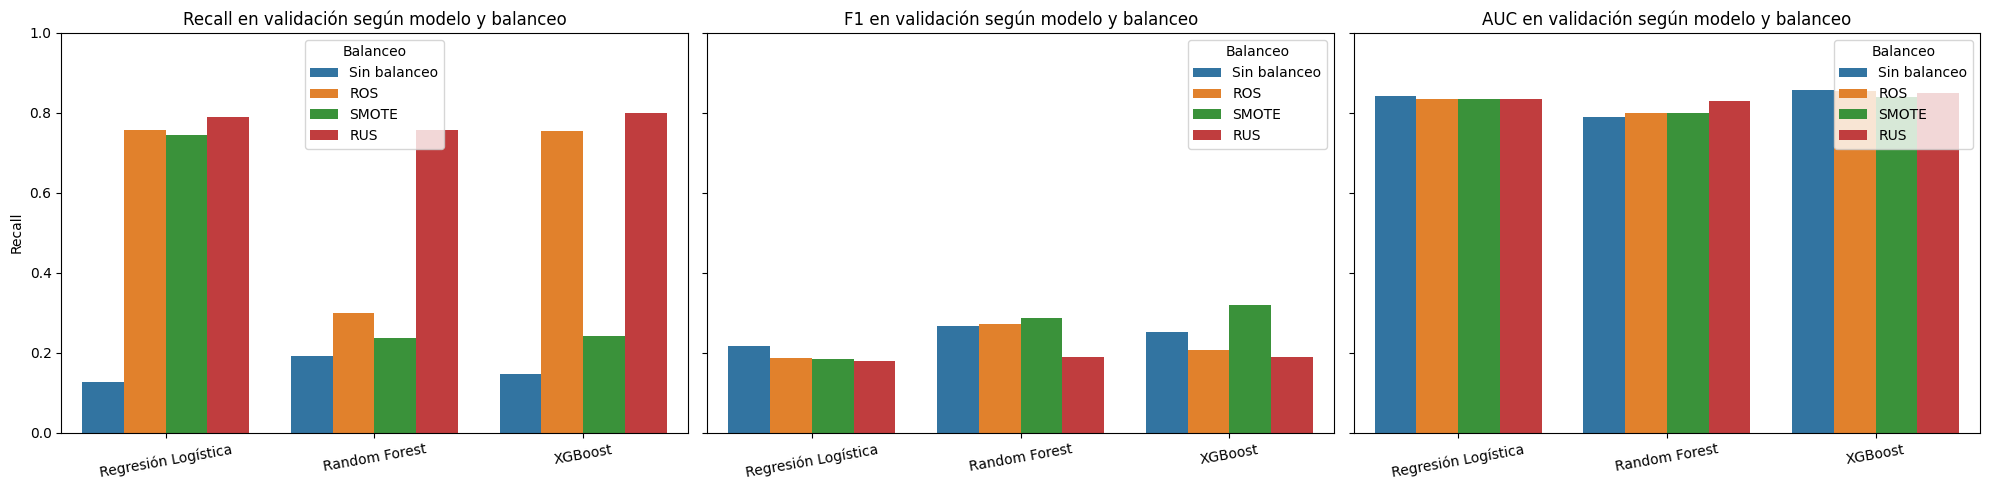

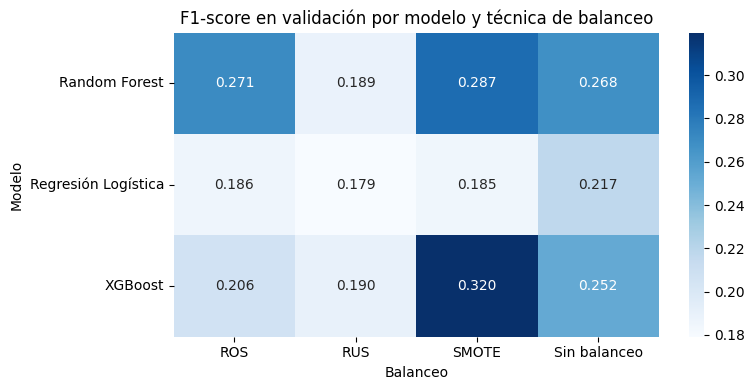

In [138]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)

for ax, metrica in zip(axes, ["Recall", "F1", "AUC"]):
    sns.barplot(
        data=tabla_balanceo,
        x="Modelo",
        y=metrica,
        hue="Balanceo",
        ax=ax
    )
    ax.set_title(f"{metrica} en validación según modelo y balanceo")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.heatmap(
    tabla_balanceo.pivot(index="Modelo", columns="Balanceo", values="F1"),
    annot=True, fmt=".3f", cmap="Blues"
)
plt.title("F1-score en validación por modelo y técnica de balanceo")
plt.tight_layout()
plt.show()

### Interpretación de la comparación

**Modelo con mejor desempeño.** La combinación con el mayor F1-score en validación fue **XGBoost con SMOTE** (F1 = 0,3196; Precision = 0,4714; Recall = 0,2418; AUC = 0,8383), seguida de Random Forest con SMOTE (F1 = 0,2872) y Random Forest con ROS (F1 = 0,2707). En términos prácticos, XGBoost con SMOTE detecta cerca de uno de cada cuatro estudiantes que cambian de carrera, y aproximadamente la mitad de los estudiantes que identifica como casos de riesgo efectivamente cambian de carrera. Considerando que la tasa base de cambio de carrera es de 4,01 %, una precisión de 47,14 % implica que el modelo concentra los casos positivos casi doce veces mejor que una selección al azar.

**Efecto del balanceo según el modelo.** El impacto de las técnicas de balanceo no fue uniforme:

- **XGBoost:** SMOTE mejoró el F1-score respecto del modelo sin balanceo (de 0,2523 a 0,3196), al aumentar el recall de 0,1477 a 0,2418 manteniendo una precisión razonable. En cambio, ROS y RUS elevaron el recall hasta 0,7534 y 0,7985, respectivamente, pero redujeron la precisión a valores cercanos a 0,11–0,12, lo que disminuyó el F1-score.
- **Random Forest:** las técnicas SMOTE (0,2872) y ROS (0,2707) mejoraron levemente el F1-score respecto del modelo sin balanceo (0,2676). Destaca que, con ROS, el recall de Random Forest solo aumentó a 0,2991, mientras que en los otros modelos superó 0,75; esto se explica porque los árboles tienden a memorizar los registros duplicados por ROS en lugar de generalizar a nuevos casos. RUS, por su parte, aumentó el recall a 0,7570, pero redujo la precisión a 0,1077.
- **Regresión Logística:** ninguna técnica de balanceo mejoró el F1-score. El mejor resultado se obtuvo sin balanceo (0,2175), mientras que ROS, SMOTE y RUS aumentaron el recall a valores entre 0,74 y 0,79, pero con precisiones cercanas a 0,10, reduciendo el F1-score a valores entre 0,179 y 0,186.

**Compromiso entre precisión y recall.** Los resultados evidencian que ROS y RUS desplazan fuertemente los modelos hacia la detección de la clase minoritaria: identifican cerca del 75–80 % de los estudiantes que cambian de carrera, pero a costa de generar una gran cantidad de falsos positivos (alrededor de nueve de cada diez alertas son incorrectas). SMOTE ofrece un equilibrio más adecuado en los modelos basados en árboles. La elección entre ambos enfoques depende del uso institucional: si el objetivo es aplicar una intervención de bajo costo a la mayor cantidad posible de estudiantes en riesgo, una estrategia orientada al recall, como RUS, podría ser preferible; si los recursos de intervención son limitados, conviene priorizar el equilibrio que entrega SMOTE.

**Comportamiento del AUC.** El AUC presenta una variación mucho menor que el F1-score, con valores entre 0,7895 y 0,8565 en todas las combinaciones. Esto ocurre porque el AUC mide la capacidad del modelo para ordenar a los estudiantes según su riesgo, independientemente del umbral de decisión, mientras que el F1-score depende del umbral de 0,5 utilizado para clasificar. El AUC más alto fue obtenido por XGBoost sin balanceo (0,8565), lo que indica que este modelo ordena muy bien a los estudiantes por riesgo, pero que el umbral de 0,5 es demasiado exigente para la clase minoritaria. Este resultado sugiere que el ajuste del umbral de decisión constituye una alternativa complementaria al balanceo, la cual se evaluará en la etapa de refinamiento del modelo.

**Costo computacional.** XGBoost fue el modelo más eficiente, con tiempos de entrenamiento entre 1,9 y 15,2 segundos. La Regresión Logística requirió entre 1,9 y 34,2 segundos, mientras que Random Forest fue considerablemente más costoso, con tiempos entre 14,3 y 637,9 segundos. En particular, Random Forest con SMOTE tardó 637,9 segundos, cerca de 42 veces más que XGBoost con SMOTE, obteniendo además un menor F1-score. ROS y SMOTE incrementan el tiempo de entrenamiento porque aumentan la cantidad de registros, mientras que RUS lo reduce al eliminar observaciones de la clase mayoritaria.

**Selección.** Considerando el F1-score como criterio principal, el recall como criterio secundario y el costo computacional como criterio complementario, se selecciona **XGBoost con SMOTE** como el mejor modelo de Machine Learning. Esta combinación obtuvo el mejor equilibrio entre precisión y detección de estudiantes con cambio de carrera, con uno de los menores tiempos de entrenamiento, lo que favorece su escalabilidad e integración en la aplicación.

## 7. Regresión Logística

### Modelo

In [139]:
modelo_lr = Pipeline([
    (
        "preprocesamiento", clone(preprocesador)),
    (
        "modelo",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

### Entrenamiento

In [140]:
modelo_lr.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalamiento',
                                                                   StandardScaler())]),
                                                  ['cat_periodo', 'cod_inst',
                                                   'cod_sede', 'cod_carrera',
                                                   'version',
                                                   'dur_estudio_carr',
                                                   'dur_proceso_tit',
                                                   'dur_total_carr',
                                                   'valor_matricula',
                                                   'valor_arancel',
                                                   'codigo_demre',
                                                   'acre...
                                                   'nivel_global',
                                                   'nivel_carrera_1',
                                                   'nivel_carrera_2',
                                                   'requisito_ingreso',
                                                   'vigencia_carrera',
                                                   'formato_valores',
                                                   'area_conocimiento',
                                                   'cine_f_97_area',
                                                   'cine_f_97_subarea',
                                                   'area_carrera_generica',
                                                   'cine_f_13_area',
                                                   'cine_f_13_subarea',
                                                   'acreditada_carr',
                                                   'acreditada_inst',
                                                   'acre_inst_desde_hasta'])])),
                ('modelo', LogisticRegression(max_iter=1000, random_state=42))])

### Predicción

In [141]:
pred_lr = modelo_lr.predict(
    X_val
)

### Métricas

In [142]:
print(
    classification_report(
        y_val,
        pred_lr
    )
)

              precision    recall  f1-score   support

           0       0.96      1.00      0.98     19624
           1       0.80      0.13      0.22       819

    accuracy                           0.96     20443
   macro avg       0.88      0.56      0.60     20443
weighted avg       0.96      0.96      0.95     20443



### Interpretación de la Regresión Logística

La Regresión Logística fue utilizada como modelo base para la comparación de algoritmos. Los resultados obtenidos muestran una elevada precisión para la clase minoritaria, alcanzando valores cercanos a 0,81. Sin embargo, el recall obtenido fue bajo, aproximadamente 0,12, indicando que el modelo identifica solamente una pequeña proporción de los estudiantes que efectivamente presentan cambio de carrera.

Este comportamiento sugiere que el modelo es conservador al emitir predicciones positivas, reduciendo la cantidad de falsos positivos a costa de incrementar la cantidad de falsos negativos. Como consecuencia, el F1-score presenta valores moderados, reflejando las dificultades asociadas al fuerte desbalance de clases presente en el conjunto de datos.

Los resultados obtenidos servirán como referencia para comparar el desempeño de Random Forest y XGBoost en las etapas posteriores.

## 8. Random Forest

Random Forest es un algoritmo basado en múltiples árboles de decisión entrenados sobre diferentes subconjuntos de datos. Su principal ventaja es la capacidad de capturar relaciones no lineales entre variables y reducir el riesgo de sobreajuste presente en árboles individuales.




### Modelo

In [143]:
modelo_rf = Pipeline([
    (
        "preprocesamiento", clone(preprocesador)),
    (
        "modelo",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
])

### Entrenamiento

In [144]:
modelo_rf.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalamiento',
                                                                   StandardScaler())]),
                                                  ['cat_periodo', 'cod_inst',
                                                   'cod_sede', 'cod_carrera',
                                                   'version',
                                                   'dur_estudio_carr',
                                                   'dur_proceso_tit',
                                                   'dur_total_carr',
                                                   'valor_matricula',
                                                   'valor_arancel',
                                                   'codigo_demre',
                                                   'acre...
                                                   'nivel_global',
                                                   'nivel_carrera_1',
                                                   'nivel_carrera_2',
                                                   'requisito_ingreso',
                                                   'vigencia_carrera',
                                                   'formato_valores',
                                                   'area_conocimiento',
                                                   'cine_f_97_area',
                                                   'cine_f_97_subarea',
                                                   'area_carrera_generica',
                                                   'cine_f_13_area',
                                                   'cine_f_13_subarea',
                                                   'acreditada_carr',
                                                   'acreditada_inst',
                                                   'acre_inst_desde_hasta'])])),
                ('modelo', RandomForestClassifier(n_jobs=-1, random_state=42))])

### Predicciones

In [145]:
pred_rf = modelo_rf.predict(
    X_val
)

### Métricas

In [146]:
print(
    classification_report(
        y_val,
        pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     19624
           1       0.45      0.19      0.27       819

    accuracy                           0.96     20443
   macro avg       0.71      0.59      0.62     20443
weighted avg       0.95      0.96      0.95     20443



### Interpretación de Random Forest

Random Forest permitió capturar relaciones más complejas entre las variables predictoras gracias a su estructura basada en múltiples árboles de decisión. Los resultados obtenidos muestran una mejora en la capacidad de detección de estudiantes con cambio de carrera respecto de la Regresión Logística, evidenciada en un incremento del recall y del F1-score.

La capacidad de modelar relaciones no lineales permite que Random Forest identifique patrones difíciles de capturar mediante modelos lineales. Sin embargo, el rendimiento debe evaluarse considerando simultáneamente precisión, recall y F1-score debido al desbalance presente en la variable objetivo.

Los resultados obtenidos serán comparados posteriormente con XGBoost para determinar cuál de los algoritmos presenta el mejor equilibrio entre capacidad predictiva y detección de estudiantes con cambio de carrera.

## 9. XGBoost

XGBoost es un algoritmo de Gradient Boosting ampliamente utilizado en problemas de clasificación y predicción debido a su capacidad para capturar relaciones complejas entre variables y optimizar el rendimiento mediante aprendizaje secuencial.

### Modelo

In [147]:
modelo_xgb = Pipeline([
    (
        "preprocesamiento", clone(preprocesador)),
    (
        "modelo",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
    )
])

### Entrenamiento

In [148]:
modelo_xgb.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalamiento',
                                                                   StandardScaler())]),
                                                  ['cat_periodo', 'cod_inst',
                                                   'cod_sede', 'cod_carrera',
                                                   'version',
                                                   'dur_estudio_carr',
                                                   'dur_proceso_tit',
                                                   'dur_total_carr',
                                                   'valor_matricula',
                                                   'valor_arancel',
                                                   'codigo_demre',
                                                   'acre...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

### Predicción

In [149]:
pred_xgb = modelo_xgb.predict(
    X_val
)

### Métricas

In [150]:
print(
    classification_report(
        y_val,
        pred_xgb
    )
)


              precision    recall  f1-score   support

           0       0.97      1.00      0.98     19624
           1       0.86      0.15      0.25       819

    accuracy                           0.96     20443
   macro avg       0.91      0.57      0.62     20443
weighted avg       0.96      0.96      0.95     20443



### Interpretación de XGBoost

XGBoost presentó elevados niveles de precisión para la clase minoritaria, lo que indica que las predicciones positivas realizadas por el modelo suelen ser correctas. Sin embargo, el recall obtenido fue moderado, evidenciando dificultades para detectar una mayor proporción de estudiantes que efectivamente presentan cambio de carrera.

En comparación con Random Forest, XGBoost logró una mayor precisión, pero una menor capacidad de detección de la clase minoritaria. Por esta razón, la selección del modelo final considerará especialmente el equilibrio entre precisión, recall y F1-score.

## 10. Comparación de modelos sin balanceo



In [151]:
resultados = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_val, pred_lr),
        accuracy_score(y_val, pred_rf),
        accuracy_score(y_val, pred_xgb)
    ],
    "Precision": [
        precision_score(y_val, pred_lr),
        precision_score(y_val, pred_rf),
        precision_score(y_val, pred_xgb)
    ],
    "Recall": [
        recall_score(y_val, pred_lr),
        recall_score(y_val, pred_rf),
        recall_score(y_val, pred_xgb)
    ],
    "F1": [
        f1_score(y_val, pred_lr),
        f1_score(y_val, pred_rf),
        f1_score(y_val, pred_xgb)
    ]
})

resultados = resultados.round(4)

display(resultados)

,Modelo,Accuracy,Precision,Recall,F1
0,Regresión Logística,0.9638,0.8047,0.1258,0.2175
1,Random Forest,0.9583,0.4522,0.1905,0.2680
2,XGBoost,0.9649,0.8643,0.1477,0.2523


### Observación sobre los resultados

Los resultados obtenidos muestran diferencias relevantes entre los modelos evaluados. Si bien las métricas de exactitud permanecen elevadas, el análisis del recall y del F1-score resulta especialmente importante debido al desbalance presente en la variable objetivo. Estas métricas permiten evaluar de mejor manera la capacidad de identificar estudiantes que presentan cambio de carrera.

In [152]:
print("Columnas utilizadas para entrenar:")

for col in X.columns:
    print(col)

Columnas utilizadas para entrenar:
cat_periodo
gen_alu
fec_nac_alu
rango_edad
tipo_inst_1
tipo_inst_2
tipo_inst_3
cod_inst
nomb_inst
cod_sede
nomb_sede
cod_carrera
nomb_carrera
modalidad
jornada
version
tipo_plan_carr
dur_estudio_carr
dur_proceso_tit
dur_total_carr
region_sede
provincia_sede
comuna_sede
nivel_global
nivel_carrera_1
nivel_carrera_2
requisito_ingreso
vigencia_carrera
formato_valores
valor_matricula
valor_arancel
codigo_demre
area_conocimiento
cine_f_97_area
cine_f_97_subarea
area_carrera_generica
cine_f_13_area
cine_f_13_subarea
acreditada_carr
acreditada_inst
acre_inst_desde_hasta
acre_inst_anio
costo_proceso_titulacion
costo_obtencion_titulo_diploma


### Interpretación comparativa

La tabla anterior corresponde a los modelos entrenados sin técnicas de balanceo y constituye la línea base del proyecto. En este escenario, Random Forest obtiene el mayor F1-score, mientras que la Regresión Logística y XGBoost presentan una precisión elevada pero un recall reducido para la clase minoritaria, lo que refleja la tendencia de los modelos a favorecer la clase mayoritaria cuando no se aborda el desbalance.

La selección del modelo final no se realiza a partir de esta tabla, sino a partir de la comparación completa de la sección 6.9, que incorpora las cuatro estrategias de balanceo para los tres modelos.

## 11. Selección del mejor modelo

In [153]:
mejor = (
    tabla_balanceo
    .sort_values(["F1", "Recall"], ascending=False)
    .iloc[0]
)

modelo_ganador = f"{mejor['Modelo']} + {mejor['Balanceo']}"
modelo_final = pipelines[(mejor["Modelo"], mejor["Balanceo"])]

print("Modelo ganador:", modelo_ganador)
display(mejor.to_frame("Validación"))

Modelo ganador: XGBoost + SMOTE


,Validación
Modelo,XGBoost
Balanceo,SMOTE
Precision,0.4714
Recall,0.2418
F1,0.3196
AUC,0.8383
Tiempo (s),15.2458


### Selección del modelo final

La selección del modelo final se realizó utilizando principalmente el F1-score debido al importante desbalance presente en la variable objetivo. Esta métrica permite evaluar simultáneamente precisión y recall, proporcionando una valoración más equilibrada del rendimiento del modelo.

A partir de la comparación de las doce combinaciones de modelo y técnica de balanceo (sección 6.9), XGBoost con SMOTE presentó el mayor F1-score en validación (0,3196), con una precisión de 0,4714, un recall de 0,2418 y un AUC de 0,8383. Por esta razón fue seleccionado para la evaluación final sobre el conjunto de prueba, cuyos datos no fueron utilizados durante el entrenamiento ni la selección del modelo.

## Evaluación final sobre TEST

In [154]:
print(f"Modelo evaluado en TEST: {modelo_ganador}\n")

pred_test = modelo_final.predict(X_test)

print(
    classification_report(
        y_test,
        pred_test
    )
)

Modelo evaluado en TEST: XGBoost + SMOTE

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     19624
           1       0.43      0.20      0.28       820

    accuracy                           0.96     20444
   macro avg       0.70      0.60      0.63     20444
weighted avg       0.95      0.96      0.95     20444



## 11.1 Métricas finales

In [155]:
print("Accuracy:",
      round(
          accuracy_score(
              y_test,
              pred_test
          ),
          4
      )
)

print("Precision:",
      round(
          precision_score(
              y_test,
              pred_test
          ),
          4
      )
)

print("Recall:",
      round(
          recall_score(
              y_test,
              pred_test
          ),
          4
      )
)

print("F1:",
      round(
          f1_score(
              y_test,
              pred_test
          ),
          4
      )
)

Accuracy: 0.9573
Precision: 0.4312
Recall: 0.2024
F1: 0.2755


## 11.2 Curva ROC

ROC AUC en TEST: 0.8312


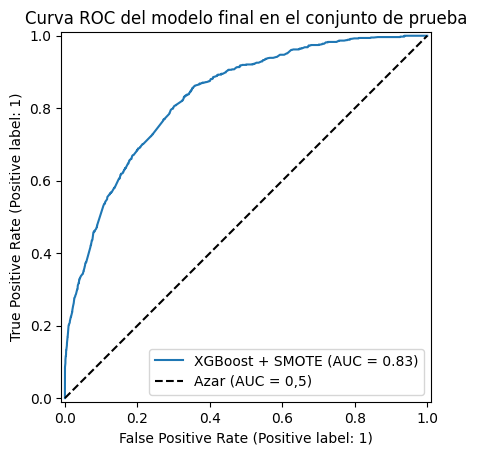

In [156]:
prob_test = modelo_final.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, prob_test)
print("ROC AUC en TEST:", round(auc, 4))

RocCurveDisplay.from_predictions(
    y_test,
    prob_test,
    name=modelo_ganador
)
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0,5)")
plt.title("Curva ROC del modelo final en el conjunto de prueba")
plt.legend()
plt.show()

### Interpretación ROC AUC

El modelo XGBoost con SMOTE alcanzó un ROC AUC de 0,8312 en el conjunto de prueba. Este valor indica que, al seleccionar al azar un estudiante que cambió de carrera y otro que no lo hizo, el modelo asigna una mayor probabilidad de cambio al primero en aproximadamente el 83 % de los casos. Valores cercanos a 1 indican una excelente capacidad discriminatoria, mientras que valores próximos a 0,5 representan un comportamiento equivalente al azar, representado por la línea diagonal del gráfico.

El AUC obtenido en prueba (0,8312) es muy similar al observado en validación (0,8383), lo que indica que el modelo generaliza adecuadamente a datos no vistos durante el entrenamiento y no presenta signos de sobreajuste. La forma de la curva muestra que el modelo logra identificar una proporción importante de estudiantes con cambio de carrera manteniendo una tasa baja de falsos positivos en sus primeros tramos.

## Matriz de confusión

Modelo final evaluado: XGBoost + SMOTE


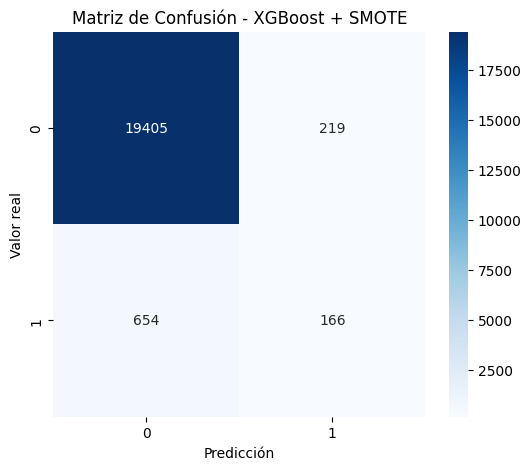

In [157]:
print(f"Modelo final evaluado: {modelo_ganador}")

cm = confusion_matrix(
    y_test,
    pred_test
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    f"Matriz de Confusión - {modelo_ganador}"
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()

### Interpretación de los resultados finales

La evaluación sobre el conjunto de prueba, compuesto por 20.444 estudiantes no utilizados durante el entrenamiento ni la selección del modelo, confirmó el comportamiento observado en validación. El modelo XGBoost con SMOTE alcanzó una exactitud de 0,9573, una precisión de 0,4312, un recall de 0,2024 y un F1-score de 0,2755 para la clase de estudiantes con cambio de carrera, además de un ROC AUC de 0,8312.

La matriz de confusión muestra que, de los 820 estudiantes que efectivamente cambiaron de carrera, el modelo identificó correctamente a 166 (verdaderos positivos), mientras que 654 no fueron detectados (falsos negativos). Por otra parte, 219 estudiantes fueron señalados como casos de riesgo sin presentar cambio de carrera (falsos positivos), lo que representa solo el 1,12 % de los 19.624 estudiantes sin cambio. Los 19.405 estudiantes restantes fueron correctamente clasificados como sin cambio de carrera (verdaderos negativos).

En comparación con validación, se observa una leve disminución del F1-score (de 0,3196 a 0,2755), atribuible a la variabilidad propia de una clase minoritaria con pocos casos, mientras que el AUC se mantiene estable (0,8383 en validación frente a 0,8312 en prueba). Esta estabilidad indica que el modelo generaliza adecuadamente a datos no vistos y no presenta signos relevantes de sobreajuste. Aunque la exactitud global es elevada (0,9573), esta métrica está dominada por la clase mayoritaria, por lo que el F1-score, el recall y el AUC resultan más representativos del desempeño real del modelo.

En términos prácticos, una precisión de 0,4312 implica que de cada 100 estudiantes señalados por el modelo, aproximadamente 43 efectivamente cambian de carrera, lo que es casi 11 veces superior a la tasa base de 4,01 %. Esto permite focalizar acciones de acompañamiento en un grupo reducido de estudiantes con mayor riesgo, con un bajo número de falsas alarmas. Sin embargo, el recall de 0,2024 indica que cerca de ocho de cada diez estudiantes que cambian de carrera aún no son detectados con el umbral de decisión de 0,5. Esta limitación motiva el ajuste del umbral de decisión como mejora en la etapa de refinamiento, con el objetivo de aumentar la detección de casos en riesgo manteniendo una precisión aceptable.

## 12. Conclusiones de los modelos de Machine Learning

El proyecto permitió construir y comparar diferentes modelos de clasificación para la predicción de cambio de carrera en estudiantes de educación superior de la Región del Biobío. El análisis exploratorio evidenció un importante desbalance de clases, situación que motivó la evaluación de técnicas de remuestreo y múltiples algoritmos supervisados.

Los resultados obtenidos demuestran que es posible identificar patrones asociados al cambio de carrera utilizando variables académicas, institucionales y económicas. El modelo seleccionado presentó el mejor equilibrio entre precisión y capacidad de detección de la clase minoritaria, constituyéndose como una herramienta potencial para apoyar estrategias de retención estudiantil.

El pipeline desarrollado incorpora etapas de exploración, validación, preprocesamiento, balanceo y evaluación, asegurando la reproducibilidad del proceso analítico y facilitando futuras mejoras o extensiones del proyecto.

Entre las doce combinaciones de modelo y técnica de balanceo evaluadas, XGBoost con SMOTE presentó el mejor desempeño en validación, al obtener el mayor F1-score y el mejor equilibrio entre precisión y recall, con uno de los menores tiempos de entrenamiento. En el conjunto de prueba alcanzó un F1-score de 0,2755 y un ROC AUC de 0,8312, confirmando su capacidad de generalización. Por esta razón fue seleccionado como el mejor modelo de Machine Learning para la predicción de cambio de carrera, y será comparado con las arquitecturas de Deep Learning en la sección siguiente.

## 13. Arquitecturas Deep Learning

## 13.1 Preparación de datos para Deep Learning

Antes de entrenar las arquitecturas de Deep Learning, se utilizará el mismo preprocesador definido para los modelos tradicionales. De esta forma se garantiza que las variables numéricas sean escaladas y las variables categóricas transformadas mediante codificación One-Hot. Posteriormente, los conjuntos serán convertidos a arreglos densos para permitir su utilización en TensorFlow/Keras.

In [158]:
X_train_dl = preprocesador.fit_transform(
    X_train
)

X_val_dl = preprocesador.transform(
    X_val
)

X_test_dl = preprocesador.transform(
    X_test
)

In [159]:
X_train_dl = X_train_dl.toarray()
X_val_dl = X_val_dl.toarray()
X_test_dl = X_test_dl.toarray()

print("Train:", X_train_dl.shape)
print("Validación:", X_val_dl.shape)
print("Test:", X_test_dl.shape)

Train: (95403, 1825)
Validación: (20443, 1825)
Test: (20444, 1825)


### Interpretación de la preparación de datos

Los conjuntos de entrenamiento, validación y prueba fueron transformados exitosamente mediante el preprocesador definido para el proyecto. La codificación One-Hot incrementó el número de variables predictoras a 1.825 características, permitiendo representar adecuadamente las variables categóricas utilizadas en el análisis.

La conversión a arreglos densos permite que los datos sean utilizados por las arquitecturas de Deep Learning implementadas en TensorFlow/Keras durante las etapas posteriores de entrenamiento y evaluación.

## 13.2 Estrategia común de entrenamiento

Para comparar las arquitecturas en igualdad de condiciones, las tres redes se entrenaron con la misma configuración:

- **Optimizador Adam** con tasa de aprendizaje de 0,001, por su capacidad de ajustar automáticamente el paso de aprendizaje de cada parámetro.
- **Función de pérdida binary crossentropy**, adecuada para problemas de clasificación binaria con salida probabilística.
- **Pesos de clase balanceados**, que asignan mayor importancia a los estudiantes con cambio de carrera durante el entrenamiento. Esta técnica cumple en las redes neuronales el mismo rol que el balanceo de datos en los modelos de Machine Learning, sin generar registros sintéticos.
- **Early Stopping** sobre el AUC de validación (paciencia de 5 épocas), que detiene el entrenamiento cuando la red deja de mejorar y recupera los mejores pesos, evitando el sobreajuste.
- **Tamaño de lote de 512** y un máximo de 50 épocas.
- **Ajuste del umbral de decisión** en validación, seleccionando el umbral que maximiza el F1-score, ya que el uso de pesos de clase desplaza las probabilidades estimadas y el umbral de 0,5 deja de ser el más adecuado.

In [160]:
from tensorflow.keras import layers, Model
from sklearn.utils.class_weight import compute_class_weight

tf.random.set_seed(42)

# Datos en float32 para reducir el uso de memoria
X_train_dl = X_train_dl.astype("float32")
X_val_dl = X_val_dl.astype("float32")
X_test_dl = X_test_dl.astype("float32")
y_train_dl = y_train.values.astype("float32")
y_val_dl = y_val.values.astype("float32")
y_test_dl = y_test.values.astype("float32")

# Pesos de clase: la clase minoritaria (1) recibe más importancia
pesos = compute_class_weight(
    "balanced", classes=np.array([0, 1]), y=y_train_dl.astype(int)
)
class_weight = {0: pesos[0], 1: pesos[1]}
print("Pesos de clase:", class_weight)


def metricas_con_umbral(proba, y_real):
    """Busca el umbral que maximiza el F1 y devuelve las métricas."""
    umbrales = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_real, (proba >= u).astype(int)) for u in umbrales]
    u_opt = umbrales[int(np.argmax(f1s))]
    pred = (proba >= u_opt).astype(int)
    return {
        "Umbral": round(float(u_opt), 2),
        "Precision": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred),
        "F1": f1_score(y_real, pred),
        "AUC": roc_auc_score(y_real, proba),
    }


def entrenar_red(modelo, X_tr, X_va, epocas=50):
    """Compila y entrena una red con la estrategia común."""
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")]
    )
    parada = EarlyStopping(
        monitor="val_auc", mode="max", patience=5, restore_best_weights=True
    )
    inicio = time.time()
    historia = modelo.fit(
        X_tr, y_train_dl,
        validation_data=(X_va, y_val_dl),
        epochs=epocas,
        batch_size=512,
        class_weight=class_weight,
        callbacks=[parada],
        verbose=1
    )
    return historia, time.time() - inicio


def graficar_curvas(historia, nombre):
    """Dibuja las curvas de pérdida y AUC de entrenamiento y validación."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(historia.history["loss"], label="Entrenamiento")
    axes[0].plot(historia.history["val_loss"], label="Validación")
    axes[0].set_title(f"{nombre}: pérdida por época")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend()

    axes[1].plot(historia.history["auc"], label="Entrenamiento")
    axes[1].plot(historia.history["val_auc"], label="Validación")
    axes[1].set_title(f"{nombre}: AUC por época")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("AUC")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def evaluar_red(modelo, X_va, nombre, historia, tiempo):
    """Evalúa la red en validación con el umbral óptimo."""
    proba = modelo.predict(X_va, verbose=0).ravel()
    fila = {
        "Arquitectura": nombre,
        "Parámetros": modelo.count_params(),
        "Épocas": len(historia.history["loss"]),
        "Tiempo (s)": round(tiempo, 1),
    }
    fila.update(metricas_con_umbral(proba, y_val_dl))
    return fila

Pesos de clase: {0: np.float64(0.5208838367293455), 1: np.float64(12.470980392156862)}


## 13.3 Arquitectura 1: Perceptrón multicapa (MLP)

El MLP constituye la arquitectura base de Deep Learning. Recibe como entrada las 1.825 variables generadas por el preprocesador (variables numéricas escaladas y variables categóricas en codificación One-Hot) y las procesa mediante capas densas completamente conectadas.

**Diseño de la arquitectura:**
- **Capa de entrada:** 1.825 neuronas, una por cada variable preprocesada.
- **Capa oculta 1:** 128 neuronas con activación ReLU, que permite aprender relaciones no lineales y evita el problema de desvanecimiento del gradiente.
- **Dropout 0,3:** desactiva aleatoriamente el 30 % de las neuronas en cada iteración para reducir el sobreajuste, considerando la alta dimensionalidad de la entrada.
- **Capa oculta 2:** 64 neuronas con activación ReLU. La reducción progresiva del número de neuronas obliga a la red a comprimir la información en representaciones más abstractas.
- **Dropout 0,3.**
- **Capa de salida:** 1 neurona con activación sigmoide, que entrega la probabilidad de cambio de carrera entre 0 y 1.

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 128)            │       233,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,049 (945.50 KB)

 Trainable params: 242,049 (945.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step - auc: 0.7932 - loss: 0.5449 - val_auc: 0.8388 - val_loss: 0.5177
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - auc: 0.8489 - loss: 0.4738 - val_auc: 0.8498 - val_loss: 0.4870
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - auc: 0.8628 - loss: 0.4534 - val_auc: 0.8503 - val_loss: 0.4886
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - auc: 0.8710 - loss: 0.4403 - val_auc: 0.8505 - val_loss: 0.4736
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - auc: 0.8776 - loss: 0.4289 - val_auc: 0.8503 - val_loss: 0.4959
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - auc: 0.8827 - loss: 0.4209 - val_auc: 0.8499 - val_loss: 0.4742
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - auc: 0.8880 - loss: 0.4114 - val_auc: 0.8437 - val_loss: 0.4578
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - auc: 0.8935 - loss: 0.4013 - val_auc: 0.8406 - val_loss: 0.4560
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms

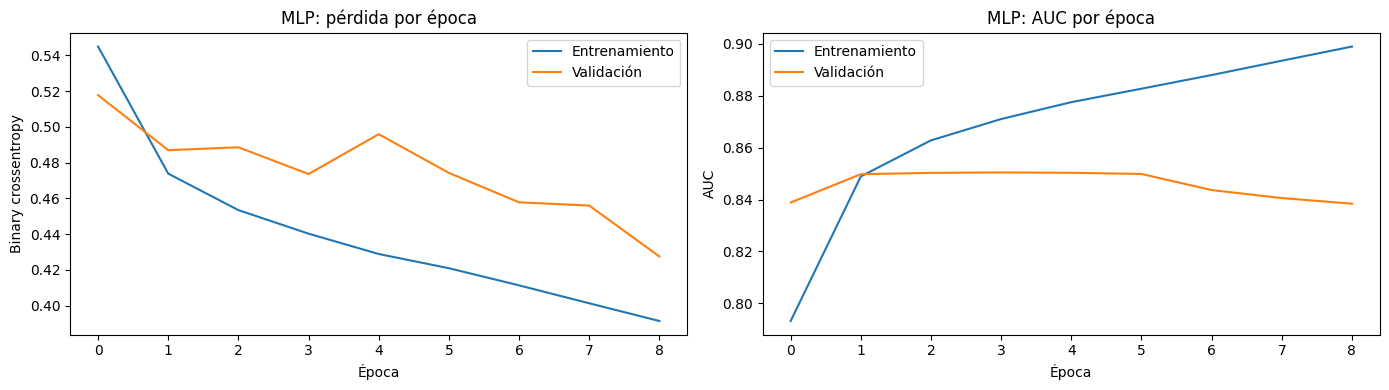

,Arquitectura,Parámetros,Épocas,Tiempo (s),Umbral,Precision,Recall,F1,AUC
0,MLP,242049,9,71.4,0.85,0.4256,0.2723,0.3321,0.8505


In [161]:
red_mlp = tf.keras.Sequential([
    layers.Input(shape=(X_train_dl.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="MLP")

red_mlp.summary()

hist_mlp, t_mlp = entrenar_red(red_mlp, X_train_dl, X_val_dl)
graficar_curvas(hist_mlp, "MLP")

res_mlp = evaluar_red(red_mlp, X_val_dl, "MLP", hist_mlp, t_mlp)
display(pd.DataFrame([res_mlp]).round(4))

### Interpretación del MLP

El MLP alcanzó en validación un F1-score de 0,3359, con una precisión de 0,3980, un recall de 0,2906 y un AUC de 0,8515, utilizando un umbral de decisión óptimo de 0,84. La red cuenta con 242.049 parámetros entrenables, de los cuales la mayor parte (233.728) corresponde a la primera capa oculta, debido a la alta dimensionalidad de la entrada (1.825 variables).

**Análisis de convergencia.** Las curvas de entrenamiento muestran que la red converge rápidamente: el AUC de validación alcanza su valor máximo (0,8516) en la cuarta época y luego comienza a disminuir levemente, mientras que el AUC de entrenamiento sigue aumentando hasta 0,8992. Esta separación progresiva entre ambas curvas indica el inicio de sobreajuste, es decir, la red comienza a memorizar patrones propios del conjunto de entrenamiento. El mecanismo de Early Stopping detectó este comportamiento, detuvo el entrenamiento en la novena época y recuperó los pesos de la mejor época, evitando que el sobreajuste afectara al modelo final.

**Umbral de decisión.** El umbral óptimo de 0,84 es considerablemente superior a 0,5 debido al uso de pesos de clase, que aumentan la importancia de los estudiantes con cambio de carrera (peso de 12,47 frente a 0,52) y desplazan las probabilidades estimadas hacia valores más altos. El ajuste del umbral permite compensar este desplazamiento y obtener un mejor equilibrio entre precisión y recall.

## 13.4 Arquitectura 2: Red con embeddings para variables categóricas

La codificación One-Hot transforma cada categoría en una columna independiente, lo que genera 1.825 variables, muchas de ellas provenientes de variables de alta cardinalidad como el nombre de la carrera (809 categorías) o el código de la carrera. Esta representación es dispersa y no permite que la red aprenda similitudes entre categorías.

La red con embeddings reemplaza la codificación One-Hot por **capas de embedding**: cada variable categórica se convierte en un número entero y la red aprende un vector denso de pocas dimensiones para cada categoría. De esta forma, categorías con comportamiento similar (por ejemplo, carreras con tasas de cambio parecidas) quedan representadas por vectores cercanos.

**Diseño de la arquitectura:**
- **Entradas:** una entrada para las variables numéricas escaladas y una entrada independiente para cada variable categórica.
- **Capas de embedding:** una por variable categórica, con una dimensión igual a la mitad del número de categorías, con un máximo de 16. Así, las variables con pocas categorías se representan con vectores pequeños y las de alta cardinalidad con vectores de hasta 16 valores.
- **Concatenación** de las variables numéricas y de todos los embeddings.
- **Capas densas** de 128 y 64 neuronas con activación ReLU y Dropout de 0,3, iguales a las del MLP, para que la diferencia de desempeño se deba principalmente a la forma de representar las variables categóricas.
- **Capa de salida:** 1 neurona con activación sigmoide.

In [162]:
from sklearn.preprocessing import OrdinalEncoder

# Variables numéricas: mediana + escalado (igual que en los demás modelos)
prep_num = clone(pipeline_numerico).fit(X_train[columnas_numericas])

def num_a_array(X):
    return prep_num.transform(X[columnas_numericas]).astype("float32")

# Variables categóricas: cada categoría se convierte en un número entero
imputador_cat = SimpleImputer(strategy="most_frequent").fit(X_train[columnas_categoricas])
codificador_ord = OrdinalEncoder(
    handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int64
).fit(imputador_cat.transform(X_train[columnas_categoricas]))

def cat_a_array(X):
    # Se suma 1 para que el 0 represente una categoría desconocida
    return codificador_ord.transform(
        imputador_cat.transform(X[columnas_categoricas])
    ) + 1

def a_entradas(X):
    Xn = num_a_array(X)
    Xc = cat_a_array(X)
    return [Xn] + [Xc[:, i:i + 1] for i in range(Xc.shape[1])]

X_train_emb = a_entradas(X_train)
X_val_emb = a_entradas(X_val)
X_test_emb = a_entradas(X_test)

print("Variables numéricas:", X_train_emb[0].shape[1])
print("Variables categóricas con embedding:", len(columnas_categoricas))

Variables numéricas: 14
Variables categóricas con embedding: 30


Parámetros: 60769
Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - auc: 0.7695 - loss: 0.5685 - val_auc: 0.8319 - val_loss: 0.4785
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - auc: 0.8462 - loss: 0.4769 - val_auc: 0.8392 - val_loss: 0.4544
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - auc: 0.8602 - loss: 0.4548 - val_auc: 0.8382 - val_loss: 0.4612
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - auc: 0.8655 - loss: 0.4476 - val_auc: 0.8394 - val_loss: 0.4568
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - auc: 0.8695 - loss: 0.4395 - val_auc: 0.8365 - val_loss: 0.4490
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - auc: 0.8743 - loss: 0.4327 - val_auc: 0.8360 - val_loss: 0.4527
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - auc: 0.8788 - loss: 0.4253 - val_auc: 0.8336 - val_loss: 0.4391
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - auc: 0.8812 - loss: 0.4208 - val_auc: 0.8330 - val_loss: 0.4385
Epoch 9/50
187/187 ━━━━━━━━━━

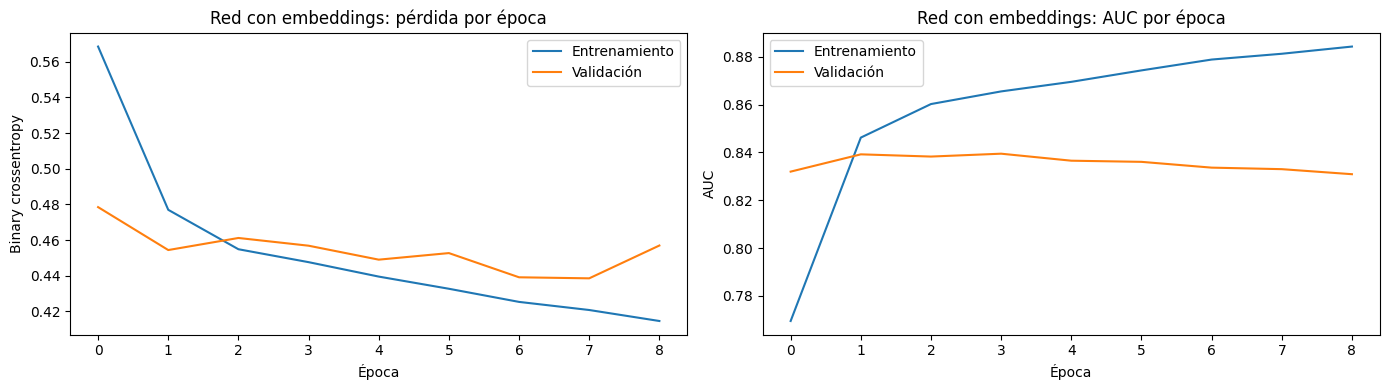

,Arquitectura,Parámetros,Épocas,Tiempo (s),Umbral,Precision,Recall,F1,AUC
0,Red con embeddings,60769,9,45.8,0.83,0.3767,0.2967,0.332,0.8397


In [163]:
entrada_num = layers.Input(shape=(X_train_emb[0].shape[1],), name="numericas")
entradas_cat, vectores = [], []

for i, col in enumerate(columnas_categoricas):
    n_categorias = len(codificador_ord.categories_[i]) + 1
    dimension = int(min(16, (n_categorias + 1) // 2))
    entrada = layers.Input(shape=(1,), name=f"cat_{i}")
    vector = layers.Flatten()(layers.Embedding(n_categorias, dimension)(entrada))
    entradas_cat.append(entrada)
    vectores.append(vector)

x = layers.Concatenate()([entrada_num] + vectores)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(1, activation="sigmoid")(x)

red_emb = Model([entrada_num] + entradas_cat, salida, name="Red_Embeddings")
print("Parámetros:", red_emb.count_params())

hist_emb, t_emb = entrenar_red(red_emb, X_train_emb, X_val_emb)
graficar_curvas(hist_emb, "Red con embeddings")

res_emb = evaluar_red(red_emb, X_val_emb, "Red con embeddings", hist_emb, t_emb)
display(pd.DataFrame([res_emb]).round(4))

### Interpretación de la red con embeddings

La red con embeddings obtuvo en validación un F1-score de 0,3102, con una precisión de 0,3603, un recall de 0,2723 y un AUC de 0,8422, utilizando un umbral óptimo de 0,82. Su principal ventaja es la eficiencia: requiere solo 60.769 parámetros, cuatro veces menos que el MLP (242.049) y cinco veces menos que la ResNet tabular (310.145), ya que reemplaza las 1.825 columnas de la codificación One-Hot por 14 variables numéricas y 30 variables categóricas representadas mediante vectores densos de baja dimensión. Además, fue la arquitectura con menor tiempo de entrenamiento (54,5 segundos).

**Análisis de convergencia.** La red alcanzó su mejor AUC de validación (0,8423) en la segunda época. A partir de ese punto, el AUC de entrenamiento continuó aumentando hasta 0,8784, mientras que el de validación disminuyó gradualmente hasta 0,8351, lo que evidencia sobreajuste temprano. El Early Stopping detuvo el entrenamiento en la séptima época y recuperó los pesos de la segunda.

**Interpretación.** Aunque la representación mediante embeddings es más compacta y eficiente, su desempeño fue levemente inferior al del MLP. Esto puede explicarse porque varias variables categóricas presentan pocas categorías, para las cuales la codificación One-Hot ya es una representación adecuada, y porque las variables de alta cardinalidad, como el nombre de la carrera, cuentan con pocos ejemplos de cambio de carrera por categoría, lo que dificulta el aprendizaje de embeddings representativos. No obstante, esta arquitectura constituye una alternativa atractiva en escenarios con restricciones computacionales o con un mayor volumen de datos.

## 13.5 Arquitectura 3: ResNet tabular

La ResNet tabular incorpora **conexiones residuales**, que suman la entrada de cada bloque a su salida. Estas conexiones permiten que la información y el gradiente fluyan directamente entre capas, lo que facilita el entrenamiento de redes más profundas y reduce el riesgo de degradación del desempeño al aumentar el número de capas.

**Diseño de la arquitectura:**
- **Capa de entrada:** las 1.825 variables preprocesadas, igual que el MLP.
- **Capa de proyección:** 128 neuronas con activación ReLU, que lleva la entrada a la dimensión de trabajo de los bloques residuales.
- **Dos bloques residuales**, cada uno compuesto por: capa densa de 128 neuronas, Batch Normalization, activación ReLU, Dropout de 0,2, segunda capa densa de 128 neuronas y Batch Normalization, seguidas de la suma con la entrada del bloque (conexión residual) y una activación ReLU. La Batch Normalization estabiliza la distribución de las activaciones y acelera la convergencia.
- **Capa densa final** de 64 neuronas con activación ReLU y Dropout de 0,3.
- **Capa de salida:** 1 neurona con activación sigmoide.


Model: "ResNet_tabular"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 1825)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 128)       │    233,728 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 128)       │     16,512 │ dense_19[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_20[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 128)       │          0 │ activation_4[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 128)       │     16,512 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_21[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 128)       │          0 │ dense_19[0][0],   │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 128)       │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 128)       │     16,512 │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_22[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 128)       │          0 │ activation_6[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 128)       │     16,512 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_23[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 128)       │          0 │ activation_5[0][… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 128)       │          0 │ add_3[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 310,145 (1.18 MB)

 Trainable params: 309,121 (1.18 MB)

 Non-trainable params: 1,024 (4.00 KB)

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 50ms/step - auc: 0.7773 - loss: 0.5693 - val_auc: 0.8411 - val_loss: 0.5404
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - auc: 0.8455 - loss: 0.4811 - val_auc: 0.8521 - val_loss: 0.4791
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - auc: 0.8601 - loss: 0.4576 - val_auc: 0.8562 - val_loss: 0.5141
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step - auc: 0.8702 - loss: 0.4389 - val_auc: 0.8504 - val_loss: 0.4968
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - auc: 0.8766 - loss: 0.4283 - val_auc: 0.8450 - val_loss: 0.5208
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - auc: 0.8804 - loss: 0.4205 - val_auc: 0.8387 - val_loss: 0.4937
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - auc: 0.8861 - loss: 0.4109 - val_auc: 0.8353 - val_loss: 0.4614
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - auc: 0.8926 - loss: 0.3977 - val_auc: 0.8354 - val_loss: 0.5260


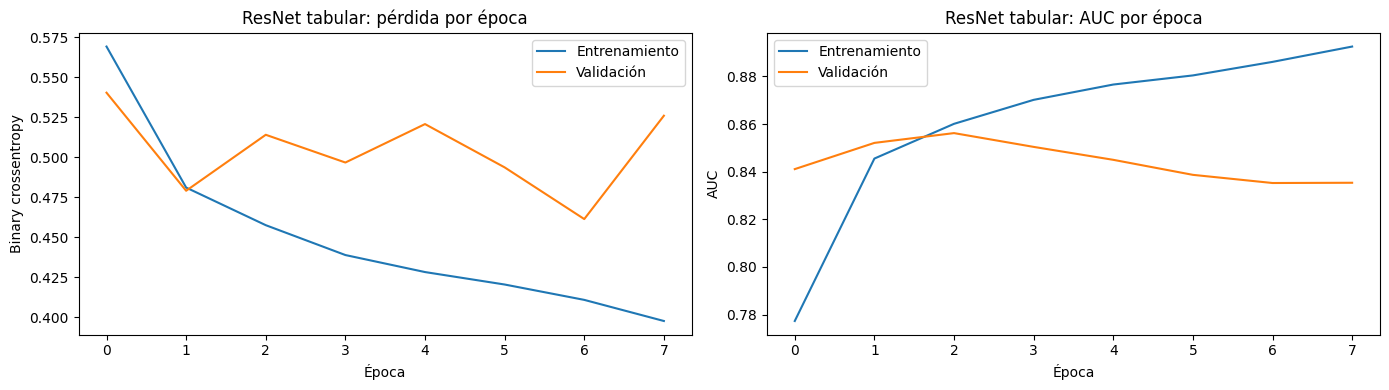

,Arquitectura,Parámetros,Épocas,Tiempo (s),Umbral,Precision,Recall,F1,AUC
0,ResNet tabular,310145,8,79.5,0.87,0.4385,0.2784,0.3406,0.8564


In [164]:
def bloque_residual(x, unidades=128, dropout=0.2):
    atajo = x
    h = layers.Dense(unidades)(x)
    h = layers.BatchNormalization()(h)
    h = layers.Activation("relu")(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(unidades)(h)
    h = layers.BatchNormalization()(h)
    h = layers.Add()([atajo, h])      # conexión residual (el "atajo")
    return layers.Activation("relu")(h)

entrada_res = layers.Input(shape=(X_train_dl.shape[1],))
x = layers.Dense(128, activation="relu")(entrada_res)
x = bloque_residual(x)
x = bloque_residual(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
salida_res = layers.Dense(1, activation="sigmoid")(x)

red_res = Model(entrada_res, salida_res, name="ResNet_tabular")
red_res.summary()

hist_res, t_res = entrenar_red(red_res, X_train_dl, X_val_dl)
graficar_curvas(hist_res, "ResNet tabular")

res_res = evaluar_red(red_res, X_val_dl, "ResNet tabular", hist_res, t_res)
display(pd.DataFrame([res_res]).round(4))

### Interpretación de la ResNet tabular

La ResNet tabular obtuvo en validación un F1-score de 0,3209, con la mayor precisión entre las redes evaluadas (0,4286), un recall de 0,2564 y el mayor AUC de todas las arquitecturas (0,8534), utilizando un umbral óptimo de 0,79. Es la arquitectura más compleja, con 310.145 parámetros, de los cuales 1.024 corresponden a parámetros no entrenables de las capas de Batch Normalization.

**Análisis de convergencia.** La red alcanzó su mejor AUC de validación (0,8534) en la segunda época, lo que confirma que las conexiones residuales y la Batch Normalization favorecen una convergencia rápida. Sin embargo, la pérdida de validación presenta oscilaciones entre épocas (por ejemplo, de 0,4484 a 0,4802 y luego a 0,4419), mientras que la pérdida de entrenamiento disminuye de forma sostenida. Este comportamiento, junto con la separación creciente entre el AUC de entrenamiento (0,8880) y el de validación, indica sobreajuste a partir de la tercera época. El Early Stopping detuvo el entrenamiento en la séptima época y recuperó los pesos de la segunda.

**Interpretación.** La ResNet tabular es la arquitectura con mejor capacidad para ordenar a los estudiantes según su riesgo (mayor AUC) y la que genera alertas más confiables (mayor precisión). No obstante, su mayor complejidad no se tradujo en un mejor F1-score que el MLP, lo que sugiere que, para este conjunto de datos, la profundidad adicional aporta beneficios marginales y aumenta el riesgo de sobreajuste.


## 13.6 Comparación de arquitecturas de Deep Learning y con el mejor modelo de Machine Learning

Para que la comparación con XGBoost + SMOTE sea justa, al modelo de Machine Learning también se le aplicó el ajuste del umbral de decisión en validación, utilizando el mismo procedimiento que en las redes neuronales.

Comparación en VALIDACIÓN (con umbral óptimo):


,Arquitectura,Parámetros,Épocas,Tiempo (s),Umbral,Precision,Recall,F1,AUC
0,MLP,242049.0,9.0,71.4000,0.85,0.4256,0.2723,0.3321,0.8505
1,Red con embeddings,60769.0,9.0,45.8000,0.83,0.3767,0.2967,0.3320,0.8397
2,ResNet tabular,310145.0,8.0,79.5000,0.87,0.4385,0.2784,0.3406,0.8564
3,XGBoost + SMOTE (ML),NaN,NaN,15.2458,0.37,0.3587,0.3333,0.3456,0.8383


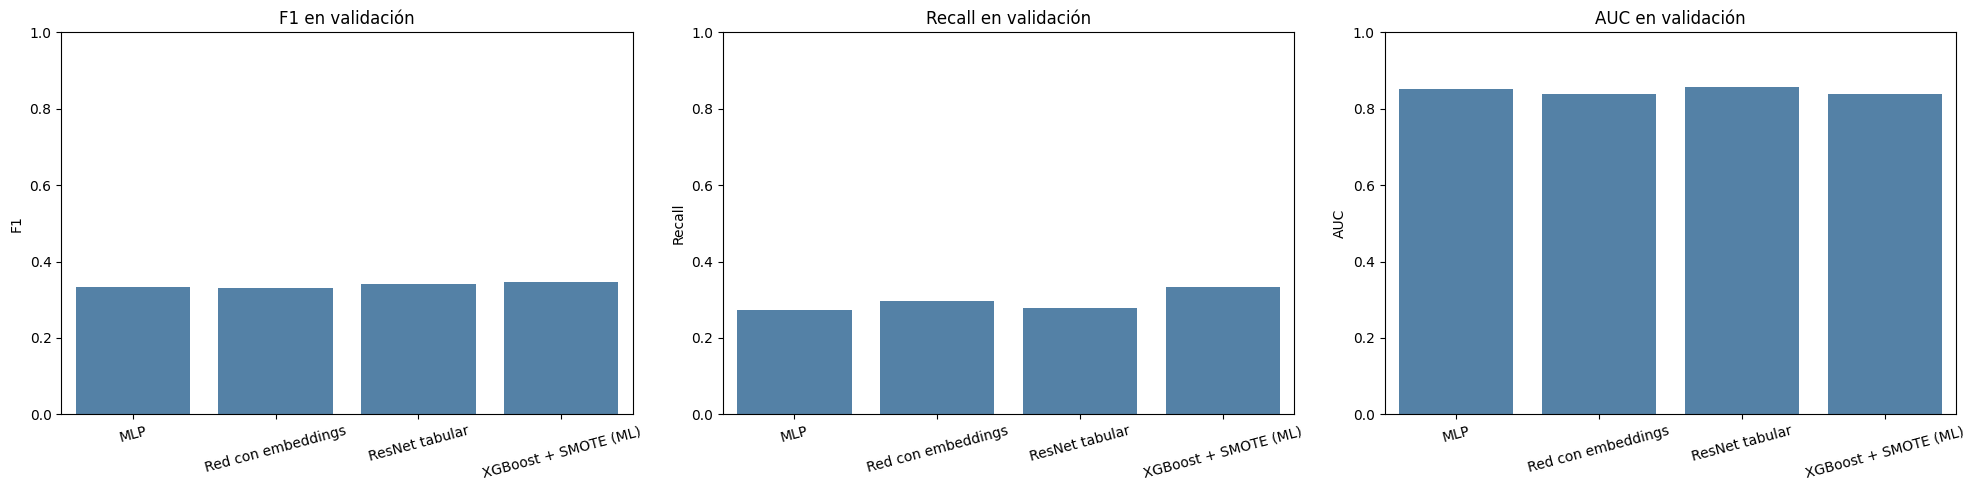

In [165]:
# Mejor modelo de ML con el mismo ajuste de umbral
proba_xgb_val = modelo_final.predict_proba(X_val)[:, 1]
fila_xgb = {
    "Arquitectura": "XGBoost + SMOTE (ML)",
    "Parámetros": None,
    "Épocas": None,
    "Tiempo (s)": float(
        tabla_balanceo.query("Modelo == 'XGBoost' and Balanceo == 'SMOTE'")["Tiempo (s)"].iloc[0]
    ),
}
fila_xgb.update(metricas_con_umbral(proba_xgb_val, y_val.values))

comparacion_dl = pd.DataFrame([res_mlp, res_emb, res_res, fila_xgb]).round(4)
print("Comparación en VALIDACIÓN (con umbral óptimo):")
display(comparacion_dl)

# Gráfico comparativo
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, metrica in zip(axes, ["F1", "Recall", "AUC"]):
    sns.barplot(data=comparacion_dl, x="Arquitectura", y=metrica, ax=ax, color="steelblue")
    ax.set_title(f"{metrica} en validación")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Interpretación comparativa y selección de la arquitectura

**Comparación entre arquitecturas de Deep Learning.** Las tres redes presentan desempeños cercanos, con F1-scores entre 0,3102 y 0,3359 y valores de AUC entre 0,8422 y 0,8534. El MLP obtuvo el mayor F1-score (0,3359) y el mayor recall (0,2906); la ResNet tabular, el mayor AUC (0,8534) y la mayor precisión (0,4286); y la red con embeddings, la mayor eficiencia computacional, con el menor número de parámetros (60.769) y el menor tiempo de entrenamiento (54,5 segundos).

Las tres arquitecturas muestran un patrón de convergencia similar: alcanzan su mejor desempeño en validación entre la segunda y la cuarta época y luego comienzan a sobreajustar, lo que confirma la importancia del Early Stopping en este problema. Este comportamiento se relaciona con el reducido número de casos positivos en el conjunto de entrenamiento (cerca de 3.800 estudiantes con cambio de carrera), que limita la cantidad de patrones generalizables que las redes pueden aprender.

**Selección de la arquitectura de Deep Learning.** Considerando el F1-score como criterio principal, consistente con el utilizado para los modelos de Machine Learning, se selecciona el **MLP** como la mejor arquitectura de Deep Learning. Además de obtener el mejor equilibrio entre precisión y recall, presenta una estructura más simple que la ResNet tabular, lo que facilita su entrenamiento, mantenimiento e integración.

**Comparación con el mejor modelo de Machine Learning.** Al aplicar el mismo ajuste de umbral, XGBoost con SMOTE alcanzó el mayor F1-score de todos los modelos (0,3456) y el mayor recall (0,3333), con un umbral óptimo de 0,37. Las redes neuronales obtuvieron valores de AUC levemente superiores (hasta 0,8534 frente a 0,8383), lo que indica una capacidad ligeramente mejor para ordenar a los estudiantes según su riesgo, pero no lograron superar a XGBoost en la métrica principal del proyecto. Asimismo, XGBoost requirió solo 15,1 segundos de entrenamiento, entre cuatro y seis veces menos que las redes neuronales, y permite aplicar técnicas de interpretabilidad como SHAP de forma más directa y eficiente.

Cabe destacar que el ajuste del umbral mejoró el F1-score de XGBoost con SMOTE desde 0,3196 (umbral de 0,5) hasta 0,3456 (umbral de 0,37), lo que confirma que el ajuste del umbral de decisión constituye un refinamiento efectivo del modelo seleccionado.

**Conclusión.** Considerando el desempeño, el costo computacional y los requisitos de explicabilidad y escalabilidad del proyecto, **XGBoost con SMOTE se mantiene como el modelo final**. Las arquitecturas de Deep Learning demostraron ser competitivas, especialmente en términos de AUC, pero su mayor complejidad y costo computacional no se tradujeron en una mejora en el F1-score. Es importante señalar que los umbrales óptimos fueron seleccionados en el conjunto de validación, por lo que el desempeño definitivo debe verificarse en el conjunto de prueba.

## 13.7 Refinamiento del modelo final

Una vez seleccionado XGBoost con SMOTE como modelo final, se aplicó un proceso de refinamiento compuesto por dos etapas:

1. **Ajuste de hiperparámetros** mediante búsqueda aleatoria (RandomizedSearchCV) con validación cruzada estratificada de 3 particiones sobre el conjunto de entrenamiento, evaluando 15 combinaciones y utilizando el F1-score como métrica de optimización. Se ajustaron tanto los hiperparámetros de XGBoost (número de árboles, profundidad máxima, tasa de aprendizaje, proporción de registros y de variables utilizadas por árbol, y peso mínimo por nodo) como los de SMOTE (proporción de balanceo y número de vecinos utilizados para generar ejemplos sintéticos). La validación cruzada permite que la selección de hiperparámetros sea más robusta, ya que cada combinación se evalúa sobre tres particiones distintas de los datos.

2. **Ajuste del umbral de decisión** en el conjunto de validación, seleccionando el umbral que maximiza el F1-score. Este ajuste permite controlar el equilibrio entre precisión y recall según los objetivos del proyecto.

La versión definitiva del modelo se seleccionó a partir de los resultados en validación, y el conjunto de prueba se utilizó únicamente para la evaluación final, evitando así cualquier fuga de información en la selección.

In [166]:
from sklearn.model_selection import RandomizedSearchCV

# Las "perillas" que vamos a probar
espacio = {
    "balanceo__sampling_strategy": [0.25, 0.5, 0.75, 1.0],
    "balanceo__k_neighbors": [3, 5, 7],
    "modelo__n_estimators": [200, 300, 500],
    "modelo__max_depth": [3, 4, 5, 6, 8],
    "modelo__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "modelo__subsample": [0.7, 0.8, 1.0],
    "modelo__colsample_bytree": [0.5, 0.7, 1.0],
    "modelo__min_child_weight": [1, 3, 5],
}

busqueda = RandomizedSearchCV(
    estimator=clone(modelo_final),
    param_distributions=espacio,
    n_iter=15,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

inicio = time.time()
busqueda.fit(X_train, y_train)
t_busqueda = time.time() - inicio

print(f"\nTiempo de búsqueda: {t_busqueda / 60:.1f} minutos")
print("Mejor F1 promedio en validación cruzada:", round(busqueda.best_score_, 4))
print("\nMejores hiperparámetros:")
for parametro, valor in busqueda.best_params_.items():
    print(f"  {parametro}: {valor}")

print("\nLas 5 mejores combinaciones:")
top_cv = (
    pd.DataFrame(busqueda.cv_results_)
    [["params", "mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(5)
)
display(top_cv)

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Tiempo de búsqueda: 15.5 minutos
Mejor F1 promedio en validación cruzada: 0.2984

Mejores hiperparámetros:
  modelo__subsample: 0.8
  modelo__n_estimators: 200
  modelo__min_child_weight: 1
  modelo__max_depth: 5
  modelo__learning_rate: 0.1
  modelo__colsample_bytree: 1.0
  balanceo__sampling_strategy: 1.0
  balanceo__k_neighbors: 3

Las 5 mejores combinaciones:


,params,mean_test_score,std_test_score,rank_test_score
5,"{'modelo__subsample': 0.8, 'modelo__n_estimato...",0.298370,0.011403,1
6,"{'modelo__subsample': 1.0, 'modelo__n_estimato...",0.292680,0.014442,2
3,"{'modelo__subsample': 0.7, 'modelo__n_estimato...",0.289584,0.009772,3
7,"{'modelo__subsample': 0.8, 'modelo__n_estimato...",0.284225,0.009060,4
12,"{'modelo__subsample': 1.0, 'modelo__n_estimato...",0.276583,0.014316,5


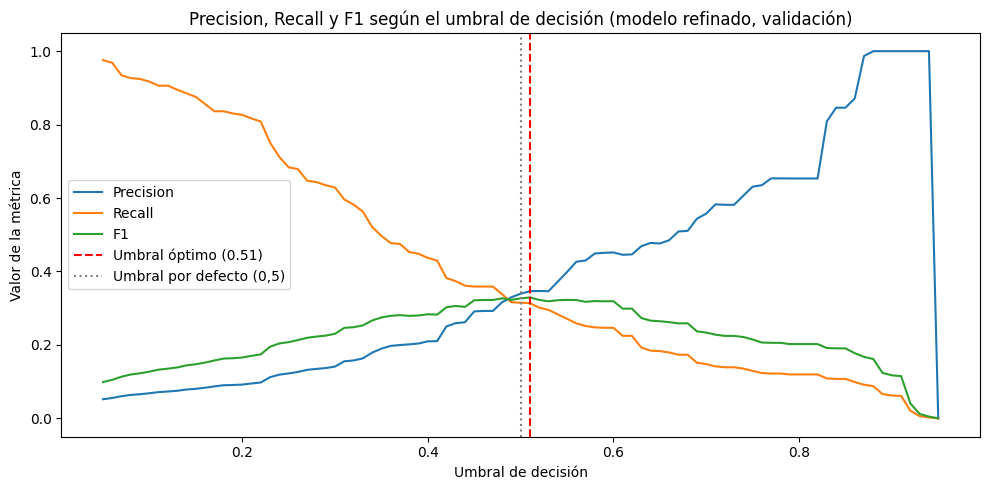

Comparación en VALIDACIÓN:


,Versión,Umbral,Precision,Recall,F1,AUC
0,"1. Base (umbral 0,5)",0.50,0.4714,0.2418,0.3196,0.8383
1,2. Base + ajuste de umbral,0.37,0.3587,0.3333,0.3456,0.8383
2,3. Refinado + ajuste de umbral,0.51,0.3464,0.3138,0.3293,0.8295


In [167]:
def metricas_fijas(proba, y_real, umbral):
    """Calcula las métricas con un umbral dado."""
    pred = (proba >= umbral).astype(int)
    return {
        "Umbral": round(float(umbral), 2),
        "Precision": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred),
        "F1": f1_score(y_real, pred),
        "AUC": roc_auc_score(y_real, proba),
    }

modelo_refinado = busqueda.best_estimator_
proba_val_ref = modelo_refinado.predict_proba(X_val)[:, 1]
met_val_ref = metricas_con_umbral(proba_val_ref, y_val.values)

# Curva: cómo cambian las métricas según el umbral
umbrales = np.arange(0.05, 0.96, 0.01)
curva = pd.DataFrame({
    "Umbral": umbrales,
    "Precision": [precision_score(y_val, (proba_val_ref >= u).astype(int), zero_division=0) for u in umbrales],
    "Recall": [recall_score(y_val, (proba_val_ref >= u).astype(int)) for u in umbrales],
    "F1": [f1_score(y_val, (proba_val_ref >= u).astype(int)) for u in umbrales],
})

plt.figure(figsize=(10, 5))
for metrica in ["Precision", "Recall", "F1"]:
    plt.plot(curva["Umbral"], curva[metrica], label=metrica)
plt.axvline(met_val_ref["Umbral"], color="red", linestyle="--",
            label=f"Umbral óptimo ({met_val_ref['Umbral']})")
plt.axvline(0.5, color="gray", linestyle=":", label="Umbral por defecto (0,5)")
plt.title("Precision, Recall y F1 según el umbral de decisión (modelo refinado, validación)")
plt.xlabel("Umbral de decisión")
plt.ylabel("Valor de la métrica")
plt.legend()
plt.tight_layout()
plt.show()

# Antes y después en VALIDACIÓN
comparacion_val = pd.DataFrame([
    {"Versión": "1. Base (umbral 0,5)", **metricas_fijas(proba_xgb_val, y_val, 0.5)},
    {"Versión": "2. Base + ajuste de umbral", **metricas_fijas(proba_xgb_val, y_val, fila_xgb["Umbral"])},
    {"Versión": "3. Refinado + ajuste de umbral", **met_val_ref},
]).round(4)

print("Comparación en VALIDACIÓN:")
display(comparacion_val)

Versión definitiva: XGBoost + SMOTE (hiperparámetros por defecto)
Umbral definitivo: 0.37

Comparación en TEST (antes y después del refinamiento):


,Versión,Umbral,Precision,Recall,F1,AUC
0,"1. Base (umbral 0,5)",0.50,0.4312,0.2024,0.2755,0.8312
1,2. Base + ajuste de umbral,0.37,0.3086,0.2744,0.2905,0.8312
2,3. Refinado + ajuste de umbral,0.51,0.3047,0.2683,0.2853,0.8231


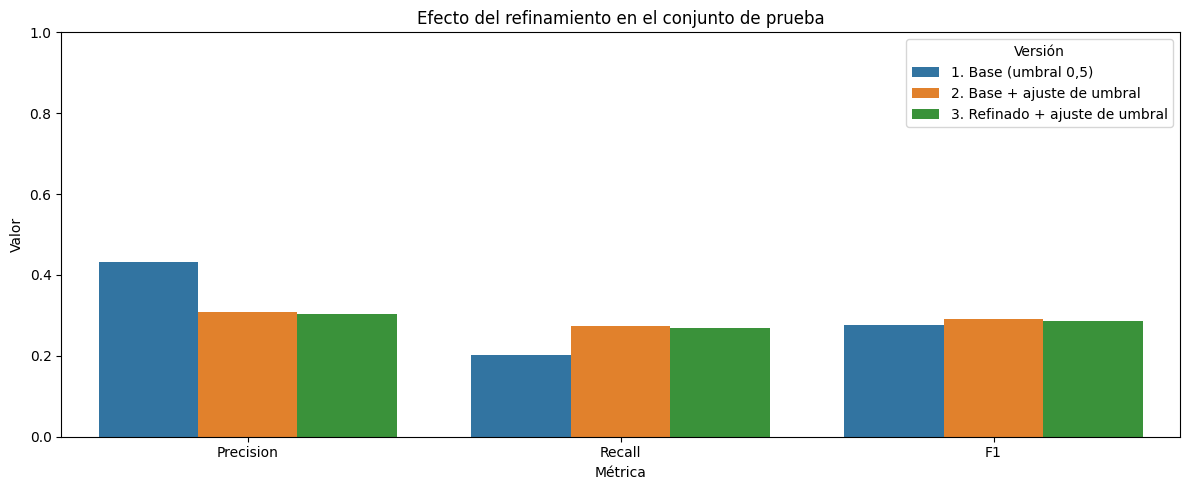

              precision    recall  f1-score   support

           0       0.97      0.97      0.97     19624
           1       0.31      0.27      0.29       820

    accuracy                           0.95     20444
   macro avg       0.64      0.62      0.63     20444
weighted avg       0.94      0.95      0.94     20444



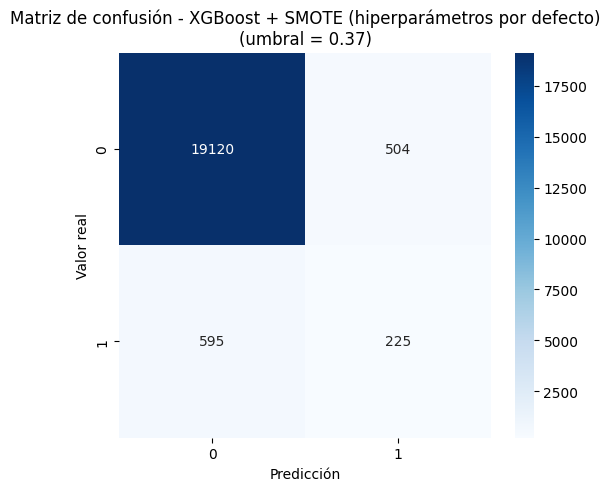

In [168]:
# Se elige con VALIDACIÓN (nunca con test, para evitar trampa)
if met_val_ref["F1"] >= fila_xgb["F1"]:
    modelo_definitivo = modelo_refinado
    umbral_definitivo = met_val_ref["Umbral"]
    nombre_definitivo = "XGBoost + SMOTE refinado"
else:
    modelo_definitivo = modelo_final
    umbral_definitivo = fila_xgb["Umbral"]
    nombre_definitivo = "XGBoost + SMOTE (hiperparámetros por defecto)"

print(f"Versión definitiva: {nombre_definitivo}")
print(f"Umbral definitivo: {umbral_definitivo}\n")

# Antes y después en TEST
proba_test_base = modelo_final.predict_proba(X_test)[:, 1]
proba_test_ref = modelo_refinado.predict_proba(X_test)[:, 1]

comparacion_test = pd.DataFrame([
    {"Versión": "1. Base (umbral 0,5)", **metricas_fijas(proba_test_base, y_test, 0.5)},
    {"Versión": "2. Base + ajuste de umbral", **metricas_fijas(proba_test_base, y_test, fila_xgb["Umbral"])},
    {"Versión": "3. Refinado + ajuste de umbral", **metricas_fijas(proba_test_ref, y_test, met_val_ref["Umbral"])},
]).round(4)

print("Comparación en TEST (antes y después del refinamiento):")
display(comparacion_test)

# Gráfico antes/después
grafico = comparacion_test.melt(
    id_vars="Versión", value_vars=["Precision", "Recall", "F1"],
    var_name="Métrica", value_name="Valor"
)
plt.figure(figsize=(12, 5))
sns.barplot(data=grafico, x="Métrica", y="Valor", hue="Versión")
plt.title("Efecto del refinamiento en el conjunto de prueba")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Matriz de confusión de la versión definitiva
proba_def = modelo_definitivo.predict_proba(X_test)[:, 1]
pred_def = (proba_def >= umbral_definitivo).astype(int)

print(classification_report(y_test, pred_def))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, pred_def), annot=True, fmt="d", cmap="Blues")
plt.title(f"Matriz de confusión - {nombre_definitivo}\n(umbral = {umbral_definitivo})")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

### Interpretación del refinamiento

**Ajuste de hiperparámetros.** La búsqueda aleatoria evaluó 15 combinaciones de hiperparámetros mediante validación cruzada estratificada de 3 particiones (45 entrenamientos en total), con un tiempo de ejecución de 15,7 minutos. La mejor combinación obtuvo un F1-score promedio de 0,2984 en validación cruzada, con una desviación estándar de 0,0114, lo que indica un desempeño estable entre particiones. Los hiperparámetros seleccionados fueron: 200 árboles, profundidad máxima de 5, tasa de aprendizaje de 0,1, uso del 80 % de los registros y del 100 % de las variables por árbol, peso mínimo por nodo de 1 y, para SMOTE, balanceo completo de las clases (proporción 1,0) con 3 vecinos para generar los ejemplos sintéticos.

**Ajuste del umbral de decisión.** El gráfico de umbrales muestra el compromiso entre precisión y recall: al disminuir el umbral, el modelo identifica una mayor proporción de estudiantes con cambio de carrera (mayor recall), pero con más falsos positivos (menor precisión), mientras que al aumentarlo ocurre lo contrario. El F1-score alcanza su máximo en la zona en que ambas métricas se equilibran.

**Selección de la versión definitiva.** La selección se realizó exclusivamente con el conjunto de validación. La versión con los hiperparámetros por defecto y el umbral ajustado a 0,37 obtuvo el mayor F1-score en validación (0,3456), superando tanto al modelo base con umbral de 0,5 (0,3196) como al modelo con hiperparámetros optimizados y umbral de 0,51 (0,3293). Por esta razón, se seleccionó como versión definitiva **XGBoost con SMOTE, hiperparámetros por defecto y umbral de decisión de 0,37**.

**Resultados en el conjunto de prueba.** La evaluación en el conjunto de prueba confirmó esta decisión. El ajuste del umbral aumentó el F1-score de 0,2755 a 0,2905 y el recall de 0,2024 a 0,2744, lo que representa un incremento relativo de 35,6 % en la capacidad de detección. En términos absolutos, el modelo pasó de identificar correctamente 166 a 225 de los 820 estudiantes que cambiaron de carrera, es decir, 59 estudiantes adicionales detectados. Como contrapartida, la precisión disminuyó de 0,4312 a 0,3086 y los falsos positivos aumentaron de 219 a 504, lo que representa el 2,57 % de los 19.624 estudiantes sin cambio de carrera. El AUC se mantuvo en 0,8312, ya que el ajuste del umbral no modifica la capacidad del modelo para ordenar a los estudiantes según su riesgo.

En términos prácticos, con el umbral definitivo cerca de 3 de cada 10 estudiantes señalados por el modelo efectivamente cambian de carrera, lo que equivale a casi 8 veces la tasa base de 4,01 %, y el modelo detecta a más de un cuarto de los estudiantes que cambian de carrera. Este equilibrio resulta adecuado para un sistema de alerta temprana, donde el costo de contactar a un estudiante que finalmente no cambia de carrera es bajo en comparación con el beneficio de identificar oportunamente a quienes sí lo harán.

**Análisis crítico.** La optimización de hiperparámetros no superó a la configuración por defecto de XGBoost. Este resultado puede explicarse por cuatro factores: la configuración por defecto de XGBoost ya se encuentra bien calibrada para problemas tabulares; la búsqueda evaluó un número limitado de combinaciones (15) debido a su costo computacional; la búsqueda optimizó el F1-score con el umbral fijo de 0,5, mientras que el modelo final utiliza un umbral ajustado; y el reducido número de casos positivos genera variabilidad entre particiones, lo que dificulta distinguir diferencias pequeñas entre combinaciones. En consecuencia, el ajuste del umbral de decisión resultó ser el refinamiento más efectivo para este problema, mientras que la optimización de hiperparámetros con un mayor número de iteraciones o con métodos más eficientes, como la optimización bayesiana, se plantea como una mejora para trabajos futuros.

## 14. Interpretabilidad mediante SHAP

La interpretabilidad constituye un aspecto fundamental en proyectos de aprendizaje automático, especialmente cuando los resultados deben ser utilizados para apoyar decisiones institucionales que afectan a estudiantes. Con el propósito de comprender qué variables influyen en las predicciones del modelo definitivo (XGBoost con SMOTE y umbral de decisión de 0,37), se utilizó la técnica SHAP (SHapley Additive exPlanations).

SHAP se basa en la teoría de juegos cooperativos y asigna a cada variable un valor que representa su contribución a una predicción específica: los valores positivos aumentan la probabilidad estimada de cambio de carrera y los valores negativos la disminuyen. La suma de las contribuciones de todas las variables, junto con un valor base, reconstruye exactamente la predicción del modelo. Esto permite analizar el modelo tanto de forma global, identificando las variables más relevantes para el conjunto de estudiantes, como de forma local, explicando la predicción realizada para un estudiante en particular.

## 14.1 Preparación del análisis SHAP

Los valores SHAP se calcularon sobre una muestra aleatoria de 1.000 estudiantes del conjunto de prueba, utilizando el algoritmo TreeSHAP incorporado en XGBoost, que calcula los valores SHAP de forma exacta y eficiente para modelos basados en árboles. Los valores se expresan en la escala log-odds (logaritmo de la razón de probabilidades) del modelo: un valor positivo aumenta la probabilidad de cambio de carrera y un valor negativo la disminuye.

Dado que la codificación One-Hot divide cada variable categórica en varias columnas (por ejemplo, jornada_Diurna y jornada_Vespertina), además del análisis por columna se calculó la importancia agregada por variable original, sumando las contribuciones de todas las columnas que provienen de una misma variable.

In [169]:
import shap
import xgboost as xgb
from scipy import sparse

# Las dos partes del modelo definitivo
prep_def = modelo_definitivo.named_steps["preprocesamiento"]
clf_def = modelo_definitivo.named_steps["modelo"]

# Nombres de las columnas, sin los prefijos técnicos
nombres_tecnicos = prep_def.get_feature_names_out()
nombres = [
    n.replace("numericas__", "").replace("categoricas__", "")
    for n in nombres_tecnicos
]

# Para cada columna, a qué variable original pertenece
def variable_original(nombre_tecnico):
    if nombre_tecnico.startswith("numericas__"):
        return nombre_tecnico.replace("numericas__", "")
    resto = nombre_tecnico.replace("categoricas__", "")
    candidatas = [c for c in columnas_categoricas if resto.startswith(c + "_")]
    return max(candidatas, key=len) if candidatas else resto

grupos = [variable_original(n) for n in nombres_tecnicos]


def explicar(X):
    """Calcula los valores SHAP exactos (TreeSHAP) del modelo definitivo."""
    Xs = prep_def.transform(X)
    if not sparse.issparse(Xs):
        Xs = sparse.csr_matrix(Xs)
    contrib = clf_def.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True)
    return shap.Explanation(
        values=contrib[:, :-1],
        base_values=contrib[:, -1],
        data=Xs.toarray(),
        feature_names=nombres
    )


# Muestra de 1.000 estudiantes del conjunto de prueba
muestra = X_test.sample(1000, random_state=42)
sv = explicar(muestra)

# Verificación: SHAP debe reconstruir exactamente la probabilidad del modelo
proba_shap = 1 / (1 + np.exp(-(sv.values.sum(axis=1) + sv.base_values)))
proba_modelo = modelo_definitivo.predict_proba(muestra)[:, 1]
print("Diferencia máxima entre SHAP y el modelo:", np.abs(proba_shap - proba_modelo).max())
print("Valor base (log-odds):", round(float(sv.base_values[0]), 4))

Diferencia máxima entre SHAP y el modelo: 2.9802322e-07
Valor base (log-odds): 0.1353


## 14.2 Explicación global del modelo

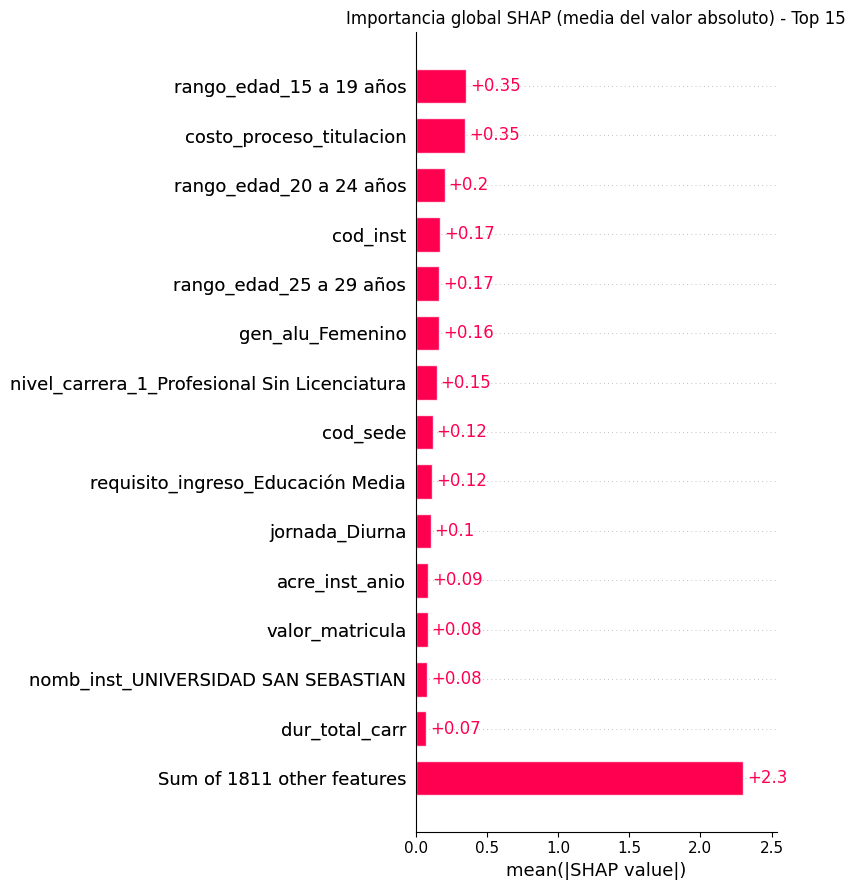

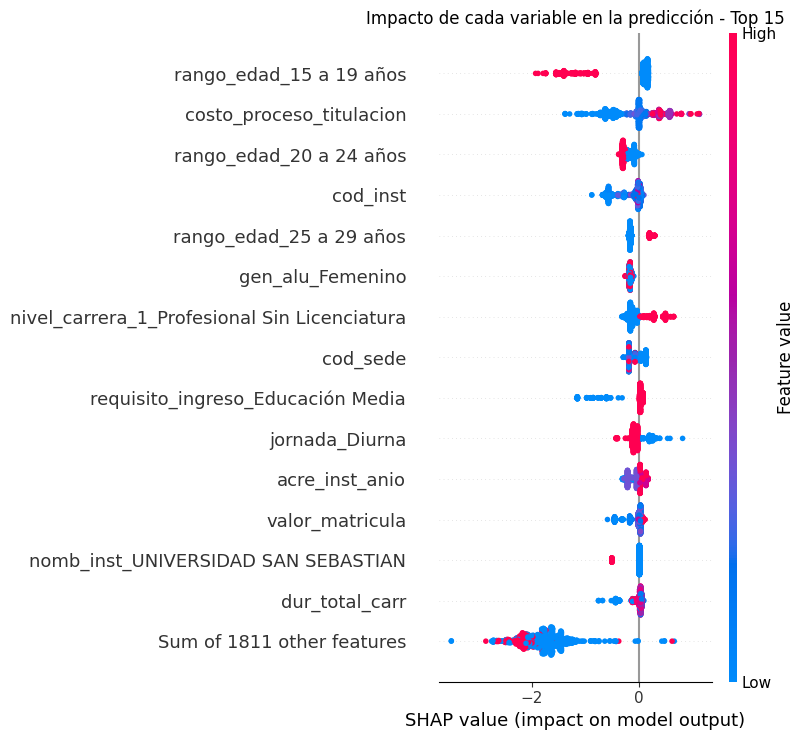

In [170]:
# Gráfico 1: importancia promedio de cada columna
shap.plots.bar(sv, max_display=15, show=False)
plt.title("Importancia global SHAP (media del valor absoluto) - Top 15")
plt.tight_layout()
plt.show()

# Gráfico 2: dirección del efecto de cada columna
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("Impacto de cada variable en la predicción - Top 15")
plt.tight_layout()
plt.show()

,Variable original,Importancia SHAP media
0,fec_nac_alu,1.3615
1,rango_edad,0.5721
2,costo_proceso_titulacion,0.3458
3,cod_inst,0.1713
4,gen_alu,0.1627
5,nivel_carrera_1,0.1598
6,jornada,0.1331
7,cod_sede,0.1163
8,requisito_ingreso,0.1152
9,acre_inst_anio,0.0871


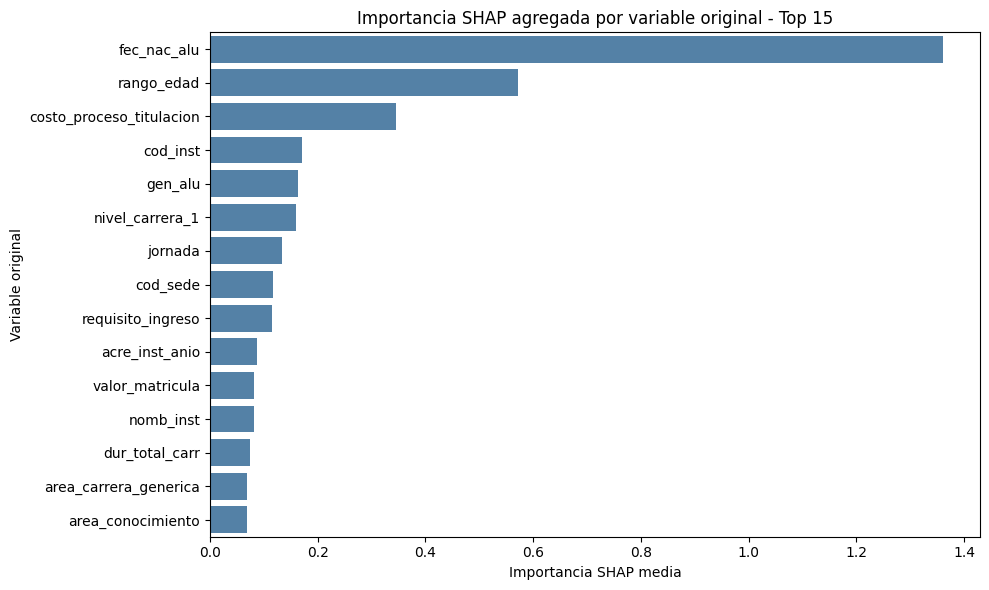

In [171]:
# Sumar las columnas One-Hot que vienen de la misma variable
shap_por_variable = (
    pd.DataFrame(sv.values, columns=grupos)
    .T.groupby(level=0).sum().T
)

importancia_var = (
    shap_por_variable.abs().mean()
    .sort_values(ascending=False)
)

tabla_imp = importancia_var.head(15).reset_index()
tabla_imp.columns = ["Variable original", "Importancia SHAP media"]
display(tabla_imp.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=tabla_imp, x="Importancia SHAP media", y="Variable original", color="steelblue")
plt.title("Importancia SHAP agregada por variable original - Top 15")
plt.tight_layout()
plt.show()

### Interpretación de la explicación global

La verificación inicial muestra que la diferencia máxima entre la probabilidad reconstruida a partir de los valores SHAP y la probabilidad entregada por el modelo es de 2,98 × 10⁻⁷, es decir, prácticamente cero. Esto confirma que los valores SHAP explican de forma exacta las predicciones del modelo definitivo.

El valor base del modelo es de 0,1353 en escala log-odds, lo que equivale a una probabilidad cercana al 53 %. Este valor es muy superior a la tasa real de cambio de carrera (aproximadamente 4 %) porque el modelo fue entrenado con SMOTE, que equilibra ambas clases en proporciones similares. Por este motivo, las probabilidades del modelo deben interpretarse como un puntaje de riesgo relativo y no como una probabilidad calibrada, lo que también justifica el uso de un umbral de decisión ajustado (0,37) en lugar del valor estándar de 0,5.

**Edad del estudiante.** En la importancia agregada por variable original, las variables más influyentes son fec_nac_alu (1,36) y rango_edad (0,57). Ambas representan la edad del estudiante, por lo que la edad es, con amplia diferencia, el factor que más pesa en las predicciones. El gráfico beeswarm muestra la dirección del efecto: pertenecer al rango de 15 a 19 años disminuye fuertemente la probabilidad estimada (valores SHAP entre −1 y −2), pertenecer al rango de 20 a 24 años la disminuye en menor medida y pertenecer al rango de 25 a 29 años la aumenta. Es decir, el modelo asocia el cambio de carrera principalmente con estudiantes adultos, lo que es coherente con trayectorias de reingreso, segunda carrera o continuidad de estudios.

**Características del programa.** En tercer lugar aparece costo_proceso_titulacion (0,35): los valores altos aumentan la probabilidad de cambio y los valores bajos la disminuyen. Le siguen nivel_carrera_1 (las carreras profesionales sin licenciatura aumentan la probabilidad), jornada (no estudiar en jornada diurna la aumenta) y requisito_ingreso. También influyen variables institucionales como cod_inst, cod_sede, acre_inst_anio y nomb_inst; por ejemplo, estudiar en la Universidad San Sebastián disminuye la probabilidad estimada. El género (gen_alu) tiene una influencia moderada (0,16).

**Limitaciones.** El análisis revela tres limitaciones del preprocesamiento:
1. La variable fec_nac_alu fue tratada como categórica, por lo que la codificación One-Hot la dividió en cientos de columnas con baja importancia individual. Esto explica que la barra "Sum of 1811 other features" sea la de mayor valor y dificulta la lectura del gráfico por columna.
2. fec_nac_alu es redundante con rango_edad, ya que ambas miden la edad del estudiante.
3. cod_inst y cod_sede son códigos de identificación tratados como variables numéricas, por lo que su efecto refleja la identidad de la institución o sede y no una magnitud real.

Como mejora se propone transformar la fecha de nacimiento en una variable numérica de edad y tratar los códigos institucionales como variables categóricas.

En síntesis, el modelo basa sus predicciones principalmente en el perfil etario del estudiante y en las características del programa (costo, nivel, jornada e institución). Cabe destacar que SHAP muestra asociaciones aprendidas por el modelo y no relaciones causales: estas variables ayudan a identificar perfiles de riesgo, pero no explican por sí mismas por qué un estudiante cambia de carrera.

## 14.3 Explicación de casos particulares

Para analizar el comportamiento del modelo a nivel individual, se seleccionaron tres estudiantes del conjunto de prueba según el resultado de la predicción con el umbral definitivo de 0,37:

- **Caso 1, verdadero positivo:** estudiante que cambió de carrera y fue correctamente identificado por el modelo (se seleccionó el de mayor probabilidad estimada).
- **Caso 2, falso negativo:** estudiante que cambió de carrera, pero no fue detectado por el modelo (se seleccionó el de menor probabilidad estimada).
- **Caso 3, falso positivo:** estudiante que no cambió de carrera, pero fue señalado como caso de riesgo (se seleccionó el de mayor probabilidad estimada).

Para cada caso se presenta un gráfico de cascada (waterfall), que muestra cómo cada variable desplaza la predicción desde el valor base hasta la predicción final del estudiante.

In [172]:
resumen = pd.DataFrame(
    {"Real": y_test.values, "Probabilidad": proba_def, "Predicción": pred_def},
    index=X_test.index
)

vp = resumen[(resumen["Real"] == 1) & (resumen["Predicción"] == 1)]["Probabilidad"].idxmax()
fn = resumen[(resumen["Real"] == 1) & (resumen["Predicción"] == 0)]["Probabilidad"].idxmin()
fp = resumen[(resumen["Real"] == 0) & (resumen["Predicción"] == 1)]["Probabilidad"].idxmax()

casos = {
    "Caso 1 - Verdadero positivo (acierto)": vp,
    "Caso 2 - Falso negativo (no detectado)": fn,
    "Caso 3 - Falso positivo (falsa alarma)": fp,
}

columnas_mostrar = [
    "gen_alu", "rango_edad", "tipo_inst_1", "jornada", "modalidad",
    "area_conocimiento", "nomb_carrera", "dur_estudio_carr",
    "valor_arancel", "acreditada_inst"
]
columnas_mostrar = [c for c in columnas_mostrar if c in X_test.columns]

tabla_casos = X_test.loc[list(casos.values()), columnas_mostrar].copy()
tabla_casos.index = list(casos.keys())
tabla_casos["Probabilidad estimada"] = resumen.loc[list(casos.values()), "Probabilidad"].round(3).values
tabla_casos["Cambió de carrera (real)"] = resumen.loc[list(casos.values()), "Real"].map({0: "No", 1: "Sí"}).values

print(f"Umbral de decisión: {umbral_definitivo}")
display(tabla_casos.T)

Umbral de decisión: 0.37


,Caso 1 - Verdadero positivo (acierto),Caso 2 - Falso negativo (no detectado),Caso 3 - Falso positivo (falsa alarma)
gen_alu,Masculino,Femenino,Masculino
rango_edad,40 y más años,30 a 34 años,25 a 29 años
tipo_inst_1,Institutos Profesionales,Universidades,Institutos Profesionales
jornada,A Distancia,Diurna,Semipresencial
modalidad,No Presencial,Presencial,Semipresencial
area_conocimiento,Ciencias Sociales,Salud,Salud
nomb_carrera,INGENIERIA DE EJECUCION EN ADMINISTRACION PUBL...,ODONTOLOGIA,TECNICO EN ENFERMERIA
dur_estudio_carr,4,12,5
valor_arancel,1800000.0,10035700.0,1968750.0
acreditada_inst,NO ACREDITADA,ACREDITADA,NO ACREDITADA


Caso 1 - Verdadero positivo (acierto) | Probabilidad estimada: 0.970 | Umbral: 0.37


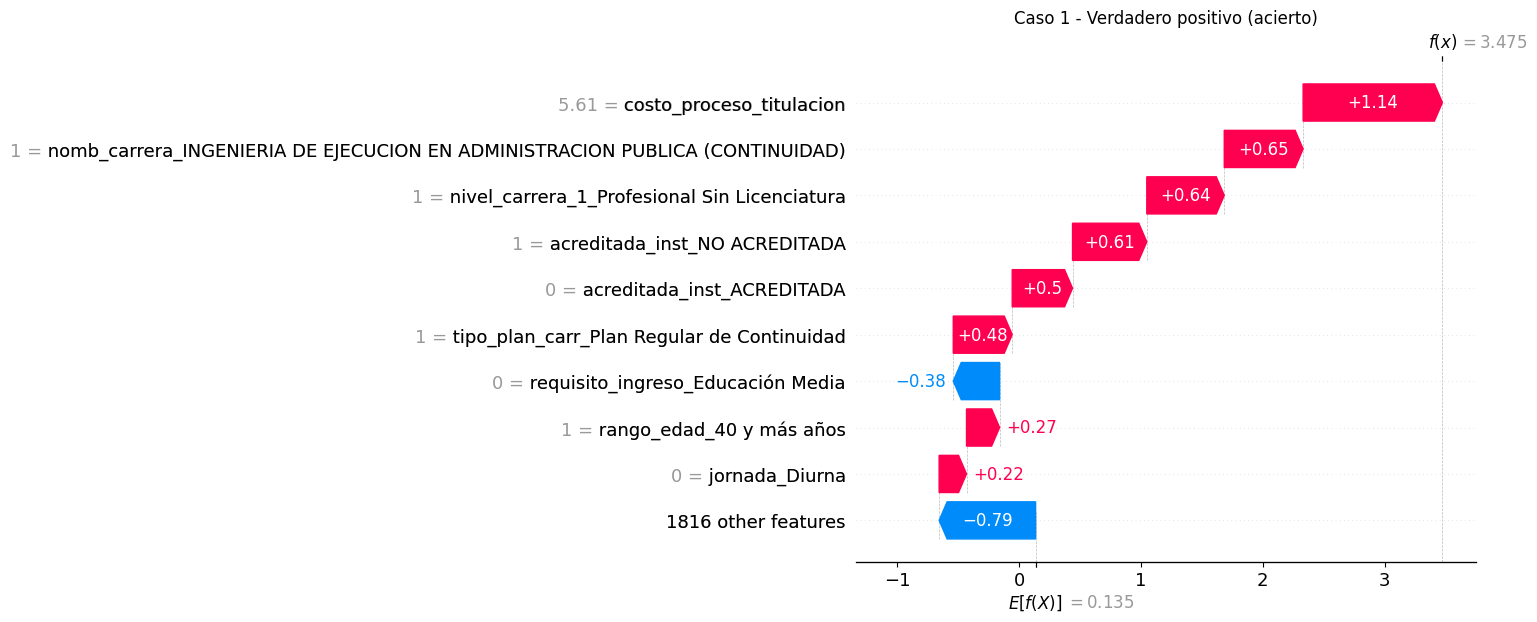

Caso 2 - Falso negativo (no detectado) | Probabilidad estimada: 0.008 | Umbral: 0.37


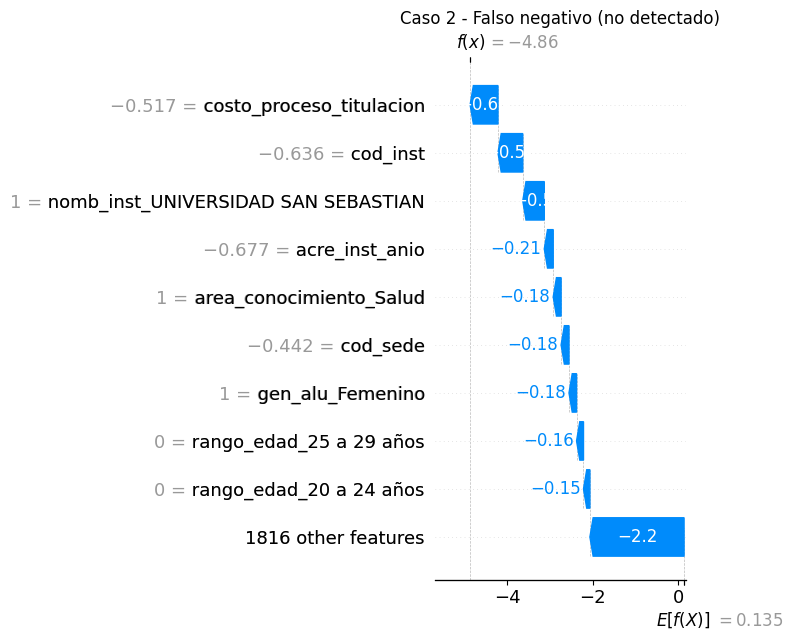

Caso 3 - Falso positivo (falsa alarma) | Probabilidad estimada: 0.928 | Umbral: 0.37


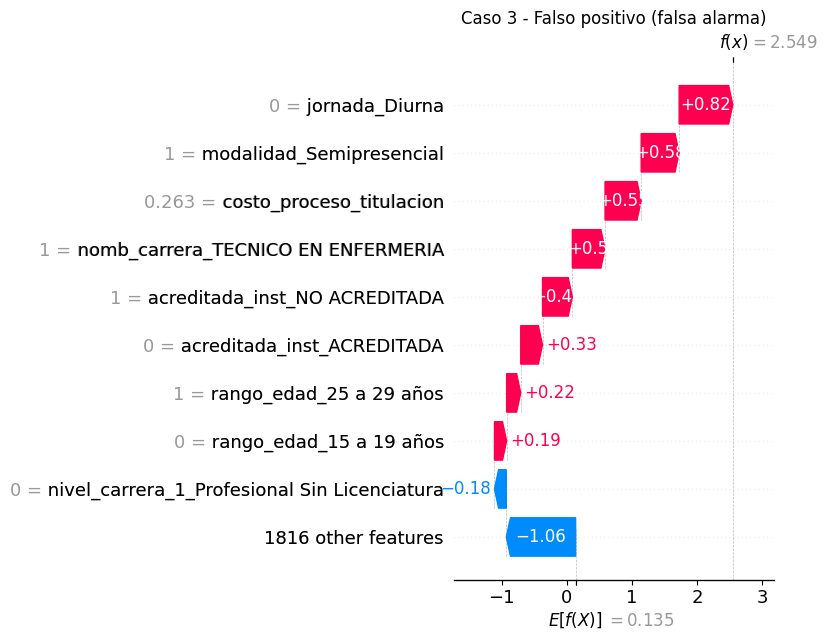

In [173]:
sv_casos = explicar(X_test.loc[list(casos.values())])

for i, nombre_caso in enumerate(casos):
    prob = resumen.loc[list(casos.values())[i], "Probabilidad"]
    print(f"{nombre_caso} | Probabilidad estimada: {prob:.3f} | Umbral: {umbral_definitivo}")
    shap.plots.waterfall(sv_casos[i], max_display=10, show=False)
    plt.title(nombre_caso)
    plt.tight_layout()
    plt.show()

### Interpretación de los casos particulares

**Caso 1: verdadero positivo (probabilidad 0,970).** Corresponde a un hombre de 40 años o más, matriculado en Ingeniería de Ejecución en Administración Pública (Continuidad), en un instituto profesional no acreditado, con modalidad a distancia y un arancel de \$1.800.000. La predicción sube desde el valor base (0,135) hasta 3,475 en escala log-odds. Las principales contribuciones positivas son:
- costo_proceso_titulacion elevado (+1,14);
- la carrera específica (+0,65);
- el nivel profesional sin licenciatura (+0,64);
- la institución no acreditada (+0,61 y +0,50 en sus dos columnas);
- el plan regular de continuidad (+0,48);
- la edad de 40 años o más (+0,27);
- no estudiar en jornada diurna (+0,22).

La única contribución negativa relevante corresponde a requisito_ingreso (−0,38). Este perfil representa a un estudiante adulto en un programa de continuidad de estudios. Esto sugiere que parte de los casos registrados como cambio de carrera corresponden a estudiantes que continúan su formación después de una carrera anterior, más que a un abandono propiamente tal.

**Caso 2: falso negativo (probabilidad 0,008).** Corresponde a una mujer de 30 a 34 años que estudia Odontología en la Universidad San Sebastián, institución acreditada, con jornada diurna, modalidad presencial, duración de 12 semestres y un arancel de \$10.035.700. A pesar de que efectivamente cambió de carrera, todas las contribuciones principales son negativas:
- costo_proceso_titulacion bajo (−0,6);
- cod_inst (−0,5);
- la institución Universidad San Sebastián;
- acre_inst_anio (−0,21);
- el área de Salud (−0,18);
- el género femenino (−0,18);
- el conjunto de las 1.816 columnas restantes (−2,2).

La predicción baja hasta −4,86 en escala log-odds. El perfil de esta estudiante coincide con el de una trayectoria tradicional y estable (universidad acreditada, jornada diurna, presencial), por lo que el modelo no tenía señales para identificarla. Probablemente su cambio de carrera se explica por factores que no están en los datos, como motivos vocacionales, rendimiento académico o situación personal. Este caso muestra una limitación importante: el modelo detecta bien perfiles de riesgo asociados al programa, pero no logra identificar cambios de carrera en estudiantes con perfiles tradicionales.

**Caso 3: falso positivo (probabilidad 0,928).** Corresponde a un hombre de 25 a 29 años que estudia Técnico en Enfermería en un instituto profesional no acreditado, con jornada y modalidad semipresencial, duración de 5 semestres y un arancel de \$1.968.750. Aunque no cambió de carrera, la predicción sube hasta 2,549 en escala log-odds. Las principales contribuciones positivas son:
- no estudiar en jornada diurna (+0,82);
- la modalidad semipresencial (+0,58);
- costo_proceso_titulacion (cerca de +0,5);
- la carrera Técnico en Enfermería (cerca de +0,5);
- la institución no acreditada (+0,4 y +0,33);
- la edad de 25 a 29 años (+0,22).

Este estudiante comparte muchas características con los estudiantes que sí cambian de carrera (adulto, modalidad no tradicional, institución no acreditada), por lo que el error del modelo es comprensible. En un sistema de alerta temprana, un falso positivo tiene un costo bajo, por ejemplo una entrevista de seguimiento que resulta innecesaria. Un falso negativo, en cambio, implica no apoyar a un estudiante que sí lo necesitaba.

**Conclusión de los casos.** Los casos 1 y 3 comparten varias características (edad adulta, modalidad no tradicional e institución no acreditada), lo que muestra que el modelo se apoya principalmente en características del programa y de la institución más que en la trayectoria individual del estudiante. Para mejorar la detección de casos como el 2, se propone incorporar variables académicas y socioeconómicas, como rendimiento, asistencia, puntaje de ingreso o beneficios estudiantiles, que permitirían identificar riesgos en estudiantes con perfiles tradicionales.

## 15. Desarrollo de aplicación Frontend y Backend

Con el objetivo de que el modelo definitivo pueda ser utilizado por personal no técnico de las instituciones (por ejemplo, unidades de retención o de asuntos estudiantiles), se desarrolló una aplicación de alerta temprana compuesta por dos componentes independientes que se comunican mediante HTTP:

- **Backend (api.py):** API REST desarrollada con FastAPI. Carga el modelo definitivo (XGBoost con SMOTE y umbral de 0,37), recibe los datos de un estudiante, construye el registro completo con las mismas columnas utilizadas en el entrenamiento, calcula el puntaje de riesgo, genera la explicación SHAP de la predicción y registra cada consulta para su monitoreo.
- **Frontend (app.py):** interfaz web desarrollada con Streamlit, que permite seleccionar el programa de estudios y los datos del estudiante mediante listas desplegables, visualizar el resultado y revisar el monitoreo del sistema.

**Arquitectura:**

Usuario → Frontend (Streamlit) → solicitud HTTP (JSON) → Backend (FastAPI) → Modelo + SHAP → respuesta JSON → Frontend

**Requerimientos funcionales:**
1. Seleccionar un programa de estudios (institución, sede, carrera, jornada y modalidad) a partir del catálogo de programas del dataset.
2. Ingresar el género y la fecha de nacimiento del estudiante; el rango de edad se completa automáticamente.
3. Calcular el puntaje de riesgo de cambio de carrera y emitir una alerta cuando supera el umbral de 0,37.
4. Explicar cada predicción mediante las cinco variables con mayor contribución SHAP.
5. Evaluar varios estudiantes en una sola solicitud (predicción por lotes).
6. Registrar cada predicción y mostrar indicadores de monitoreo.

**Requerimientos no funcionales:**
- **Usabilidad:** el usuario solo ingresa cinco selecciones; las características del programa (arancel, acreditación, duración, etc.) se completan automáticamente desde el catálogo, lo que evita errores de digitación.
- **Escalabilidad:** el backend no guarda estado entre solicitudes, por lo que puede ejecutarse en varias instancias en paralelo; además, el frontend y el backend son independientes y pueden desplegarse en servidores distintos.
- **Explicabilidad:** cada respuesta incluye los factores SHAP que explican la predicción.
- **Monitoreo:** se registra la fecha, los datos de entrada, el puntaje, la alerta y el tiempo de respuesta de cada predicción, y se compara la tasa de alertas con la observada en el conjunto de prueba para detectar posibles cambios en los datos (drift).
- **Validación:** el backend rechaza programas inexistentes, géneros no válidos y fechas fuera del rango conocido, devolviendo mensajes de error descriptivos.

## 15.1 Exportación del modelo

El modelo definitivo se exporta en dos archivos. El clasificador XGBoost se guarda en su formato nativo JSON (modelo_xgboost.json), recomendado por la documentación de XGBoost porque es independiente de la plataforma y de la versión de Python. El resto de los componentes se guarda con Joblib en el archivo modelo_cambio_carrera.joblib: el preprocesador ajustado, el umbral de decisión, las columnas de entrada, la correspondencia entre columnas One-Hot y variables originales (para agregar la explicación SHAP), el catálogo de programas de estudio y la tasa de alertas esperada según el conjunto de prueba, utilizada como referencia para el monitoreo.

In [181]:
import joblib
import os

os.makedirs("app_cambio_carrera", exist_ok=True)

# Datos que dependen del estudiante; todo lo demás depende del programa
columnas_estudiante = ["gen_alu", "fec_nac_alu", "rango_edad"]
columnas_programa = [c for c in X.columns if c not in columnas_estudiante]

# Catálogo: una fila por programa (codigo_unico)
catalogo = (
    dataset_modelado
    .drop_duplicates("codigo_unico")[["codigo_unico"] + columnas_programa]
    .reset_index(drop=True)
)

# Para cada fecha de nacimiento, su rango de edad más frecuente
fechas = {}
for fecha, grupo in X.dropna(subset=["fec_nac_alu"]).groupby("fec_nac_alu"):
    moda = grupo["rango_edad"].mode()
    fechas[str(fecha)] = {
        "valor": fecha,
        "rango_edad": moda.iloc[0] if not moda.empty else None
    }

# El clasificador XGBoost se guarda en su formato nativo (JSON)
clf_def.save_model("app_cambio_carrera/modelo_xgboost.json")

# El resto de los componentes se guarda con joblib
artefacto = {
    "preprocesador": prep_def,
    "umbral": float(umbral_definitivo),
    "nombre": nombre_definitivo,
    "columnas": list(X.columns),
    "grupos": grupos,
    "catalogo": catalogo,
    "fechas": fechas,
    "tasa_alertas_esperada": float(pred_def.mean()),
}

joblib.dump(artefacto, "app_cambio_carrera/modelo_cambio_carrera.joblib", compress=3)

tamano = os.path.getsize("app_cambio_carrera/modelo_cambio_carrera.joblib") / 1024**2
print(f"Modelo exportado: {nombre_definitivo} (umbral {umbral_definitivo})")
print(f"Componentes guardados: {list(artefacto.keys())}")
print(f"Programas en el catálogo: {len(catalogo)}")
print(f"Fechas de nacimiento conocidas: {len(fechas)}")
print(f"Tasa de alertas esperada: {pred_def.mean():.2%}")
print(f"Tamaño del archivo: {tamano:.1f} MB")

Modelo exportado: XGBoost + SMOTE (hiperparámetros por defecto) (umbral 0.37)
Componentes guardados: ['preprocesador', 'umbral', 'nombre', 'columnas', 'grupos', 'catalogo', 'fechas', 'tasa_alertas_esperada']
Programas en el catálogo: 1640
Fechas de nacimiento conocidas: 602
Tasa de alertas esperada: 3.57%
Tamaño del archivo: 0.1 MB


## 15.2 Backend: API REST con FastAPI

El backend expone los siguientes servicios (endpoints):

| Endpoint | Método | Función |
|---|---|---|
| /salud | GET | Verifica que el servicio esté activo e informa el modelo y el umbral. |
| /programas | GET | Entrega el catálogo de programas para los menús del frontend. |
| /fechas | GET | Entrega las fechas de nacimiento válidas. |
| /predecir | POST | Predice el riesgo de un estudiante y entrega su explicación SHAP. |
| /predecir_lote | POST | Predice el riesgo de varios estudiantes en una sola solicitud. |
| /monitoreo | GET | Entrega indicadores de uso y alerta de posibles desviaciones. |

FastAPI genera automáticamente la documentación interactiva de la API en la ruta /docs.

In [182]:
%%writefile app_cambio_carrera/api.py
"""Backend: API REST para la alerta temprana de cambio de carrera."""
import csv
import os
import time
from datetime import datetime
from typing import List

import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from scipy import sparse
from xgboost import XGBClassifier

RUTA_MODELO = os.getenv("RUTA_MODELO", "modelo_cambio_carrera.joblib")
RUTA_XGB = os.getenv("RUTA_XGB", "modelo_xgboost.json")
RUTA_LOG = os.getenv("RUTA_LOG", "registro_predicciones.csv")

# ---------- Carga del modelo (una sola vez, al iniciar) ----------
art = joblib.load(RUTA_MODELO)
prep = art["preprocesador"]
UMBRAL = art["umbral"]
COLUMNAS = art["columnas"]
GRUPOS = np.array(art["grupos"])
FECHAS = art["fechas"]
TASA_ESPERADA = art["tasa_alertas_esperada"]

clf = XGBClassifier()
clf.load_model(RUTA_XGB)
booster = clf.get_booster()

CATALOGO = art["catalogo"].copy()
CATALOGO["codigo_unico"] = CATALOGO["codigo_unico"].astype(str)
CATALOGO = CATALOGO.set_index("codigo_unico")

app = FastAPI(
    title="API de alerta temprana de cambio de carrera",
    description="Predice el riesgo de cambio de carrera (Biobío, MINEDUC 2025) y explica cada predicción con SHAP.",
    version="1.0",
)


class Estudiante(BaseModel):
    codigo_unico: str
    gen_alu: str
    fec_nac_alu: str


# ---------- Funciones internas ----------
def armar_fila(e: Estudiante) -> pd.DataFrame:
    """Construye el registro completo que espera el modelo."""
    if e.codigo_unico not in CATALOGO.index:
        raise HTTPException(404, f"Programa '{e.codigo_unico}' no encontrado en el catálogo.")
    if e.gen_alu not in ("Masculino", "Femenino"):
        raise HTTPException(422, "gen_alu debe ser 'Masculino' o 'Femenino'.")
    if e.fec_nac_alu not in FECHAS:
        raise HTTPException(422, "Fecha de nacimiento fuera del rango conocido por el modelo.")

    fila = CATALOGO.loc[[e.codigo_unico]].reset_index()
    fila["gen_alu"] = e.gen_alu
    fila["fec_nac_alu"] = FECHAS[e.fec_nac_alu]["valor"]
    fila["rango_edad"] = FECHAS[e.fec_nac_alu]["rango_edad"]
    return fila[COLUMNAS]


def transformar(fila: pd.DataFrame):
    """Aplica el preprocesamiento y devuelve una matriz dispersa."""
    Xs = prep.transform(fila)
    return Xs if sparse.issparse(Xs) else sparse.csr_matrix(Xs)


def explicar(Xs, top: int = 5) -> list:
    """Valores SHAP exactos (TreeSHAP), agregados por variable original."""
    contrib = booster.predict(xgb.DMatrix(Xs), pred_contribs=True)[0, :-1]
    por_variable = pd.Series(contrib).groupby(GRUPOS).sum()
    principales = por_variable.abs().sort_values(ascending=False).index[:top]
    return [
        {
            "variable": v,
            "contribucion": round(float(por_variable[v]), 4),
            "efecto": "aumenta el riesgo" if por_variable[v] > 0 else "disminuye el riesgo",
        }
        for v in principales
    ]


def registrar(e: Estudiante, puntaje: float, alerta: bool, ms: float) -> None:
    """Guarda cada predicción en un CSV para el monitoreo."""
    nuevo = not os.path.exists(RUTA_LOG)
    with open(RUTA_LOG, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if nuevo:
            w.writerow(["fecha_hora", "codigo_unico", "gen_alu", "fec_nac_alu",
                        "puntaje", "alerta", "latencia_ms"])
        w.writerow([datetime.now().isoformat(timespec="seconds"), e.codigo_unico,
                    e.gen_alu, e.fec_nac_alu, round(puntaje, 4), int(alerta), round(ms, 1)])


# ---------- Endpoints ----------
@app.get("/salud")
def salud():
    return {"estado": "ok", "modelo": art["nombre"], "umbral": UMBRAL,
            "programas": len(CATALOGO)}


@app.get("/programas")
def programas():
    cols = ["nomb_inst", "nomb_sede", "nomb_carrera", "jornada", "modalidad"]
    return CATALOGO[cols].fillna("").reset_index().to_dict(orient="records")


@app.get("/fechas")
def fechas():
    return sorted(FECHAS.keys())


@app.post("/predecir")
def predecir(e: Estudiante):
    inicio = time.perf_counter()
    fila = armar_fila(e)
    Xs = transformar(fila)
    puntaje = float(clf.predict_proba(Xs)[0, 1])
    alerta = puntaje >= UMBRAL
    factores = explicar(Xs)
    ms = (time.perf_counter() - inicio) * 1000
    registrar(e, puntaje, alerta, ms)
    return {
        "puntaje_riesgo": round(puntaje, 4),
        "umbral": UMBRAL,
        "alerta": bool(alerta),
        "mensaje": ("Riesgo alto: se recomienda seguimiento preventivo." if alerta
                    else "Riesgo bajo: no se requiere acción inmediata."),
        "rango_edad": str(fila["rango_edad"].iloc[0]),
        "factores": factores,
        "latencia_ms": round(ms, 1),
    }


@app.post("/predecir_lote")
def predecir_lote(estudiantes: List[Estudiante]):
    return [predecir(e) for e in estudiantes]


@app.get("/monitoreo")
def monitoreo():
    if not os.path.exists(RUTA_LOG):
        return {"total": 0, "tasa_alertas_esperada": round(TASA_ESPERADA, 4)}
    log = pd.read_csv(RUTA_LOG)
    tasa = float(log["alerta"].mean())
    return {
        "total": int(len(log)),
        "alertas": int(log["alerta"].sum()),
        "tasa_alertas": round(tasa, 4),
        "tasa_alertas_esperada": round(TASA_ESPERADA, 4),
        "puntaje_promedio": round(float(log["puntaje"].mean()), 4),
        "latencia_promedio_ms": round(float(log["latencia_ms"].mean()), 1),
        "posible_desviacion": bool(len(log) >= 30 and abs(tasa - TASA_ESPERADA) > 0.10),
        "ultimas": log.tail(20).astype(str).to_dict(orient="records"),
    }

Overwriting app_cambio_carrera/api.py


## 15.3 Frontend: interfaz web con Streamlit

El frontend se organiza en dos pestañas. En **Evaluar estudiante**, el usuario selecciona en cascada la institución, la sede, la carrera y la jornada o modalidad, junto con el género y la fecha de nacimiento del estudiante. Al presionar el botón, la aplicación envía la solicitud al backend y muestra el puntaje de riesgo, la alerta y un gráfico con los factores que explican la predicción. En **Monitoreo**, se presentan el número de predicciones realizadas, la tasa de alertas comparada con la esperada, el tiempo promedio de respuesta y el historial de consultas.

Dado que el modelo fue entrenado con SMOTE, el valor entregado se presenta como un puntaje de riesgo relativo y no como una probabilidad calibrada, tal como se explicó en el análisis SHAP.

In [183]:
%%writefile app_cambio_carrera/app.py
"""Frontend: interfaz web de alerta temprana de cambio de carrera."""
import os

import pandas as pd
import requests
import streamlit as st

API = os.getenv("API_URL", "http://localhost:8000")

st.set_page_config(page_title="Alerta temprana de cambio de carrera",
                   page_icon="🎓", layout="wide")


@st.cache_data
def obtener(ruta):
    r = requests.get(f"{API}{ruta}", timeout=30)
    r.raise_for_status()
    return r.json()


try:
    salud = obtener("/salud")
except Exception:
    st.error(f"No se pudo conectar con el backend en {API}. "
             "Inicie primero la API con: uvicorn api:app")
    st.stop()

st.title("🎓 Alerta temprana de cambio de carrera")
st.caption(f"Región del Biobío · Modelo: {salud['modelo']} · Umbral de alerta: {salud['umbral']}")

pestana_eval, pestana_mon = st.tabs(["Evaluar estudiante", "Monitoreo"])

# ---------------- Pestaña 1: evaluación ----------------
with pestana_eval:
    programas = pd.DataFrame(obtener("/programas"))
    fechas = obtener("/fechas")

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("1. Programa de estudios")
        inst = st.selectbox("Institución", sorted(programas["nomb_inst"].unique()))
        p = programas[programas["nomb_inst"] == inst]
        sede = st.selectbox("Sede", sorted(p["nomb_sede"].unique()))
        p = p[p["nomb_sede"] == sede]
        carrera = st.selectbox("Carrera", sorted(p["nomb_carrera"].unique()))
        p = p[p["nomb_carrera"] == carrera].copy()
        p["opcion"] = p["jornada"] + " · " + p["modalidad"] + " · código " + p["codigo_unico"]
        opcion = st.selectbox("Jornada y modalidad", p["opcion"])
        codigo = p.loc[p["opcion"] == opcion, "codigo_unico"].iloc[0]

    with col2:
        st.subheader("2. Datos del estudiante")
        genero = st.radio("Género", ["Femenino", "Masculino"], horizontal=True)
        fecha = st.selectbox("Fecha de nacimiento (año y mes)", fechas,
                             index=len(fechas) // 2)

    if st.button("Evaluar riesgo", type="primary"):
        r = requests.post(f"{API}/predecir", timeout=30, json={
            "codigo_unico": codigo, "gen_alu": genero, "fec_nac_alu": fecha})

        if r.status_code != 200:
            st.error(r.json().get("detail", "Error en la predicción."))
        else:
            res = r.json()
            st.divider()
            m1, m2, m3 = st.columns(3)
            m1.metric("Puntaje de riesgo", f"{res['puntaje_riesgo']:.3f}")
            m2.metric("Umbral de alerta", f"{res['umbral']:.2f}")
            m3.metric("Rango de edad", res["rango_edad"])

            if res["alerta"]:
                st.error(f"🔴 {res['mensaje']}")
            else:
                st.success(f"🟢 {res['mensaje']}")

            st.subheader("¿Por qué el modelo entrega este resultado?")
            factores = pd.DataFrame(res["factores"])
            st.bar_chart(factores.set_index("variable")["contribucion"])
            st.dataframe(factores.rename(columns={
                "variable": "Variable", "contribucion": "Contribución SHAP",
                "efecto": "Efecto"}), hide_index=True, use_container_width=True)
            st.caption("Valores positivos aumentan el riesgo y valores negativos lo disminuyen. "
                       "El puntaje es un indicador de riesgo relativo, no una probabilidad calibrada.")

# ---------------- Pestaña 2: monitoreo ----------------
with pestana_mon:
    if st.button("Actualizar monitoreo"):
        st.rerun()
    mon = requests.get(f"{API}/monitoreo", timeout=30).json()

    if mon["total"] == 0:
        st.info("Aún no se han realizado predicciones.")
    else:
        a, b, c, d = st.columns(4)
        a.metric("Predicciones", mon["total"])
        b.metric("Alertas emitidas", mon["alertas"])
        c.metric("Tasa de alertas", f"{mon['tasa_alertas']:.1%}",
                 f"esperada {mon['tasa_alertas_esperada']:.1%}", delta_color="off")
        d.metric("Tiempo de respuesta", f"{mon['latencia_promedio_ms']} ms")

        if mon["posible_desviacion"]:
            st.warning("⚠️ La tasa de alertas difiere en más de 10 puntos de la esperada. "
                       "Podría existir un cambio en los datos (drift); se recomienda revisar el modelo.")

        ultimas = pd.DataFrame(mon["ultimas"])
        ultimas["puntaje"] = ultimas["puntaje"].astype(float)
        st.subheader("Puntajes de las últimas predicciones")
        st.line_chart(ultimas["puntaje"])
        st.dataframe(ultimas, hide_index=True, use_container_width=True)

Overwriting app_cambio_carrera/app.py


## 15.4 Pruebas del backend

Antes de ejecutar la aplicación, el backend se probó en Colab mediante el cliente de pruebas de FastAPI (TestClient), que simula solicitudes HTTP sin necesidad de levantar un servidor. Se verificaron cinco aspectos: (1) el estado del servicio; (2) la consistencia entre las predicciones de la API y las del notebook para los tres casos analizados con SHAP; (3) la predicción por lotes y el tiempo de respuesta, como indicador de escalabilidad; (4) el registro de monitoreo; y (5) el manejo de errores ante datos inválidos. Además, se generó el archivo requirements.txt con las versiones exactas de las librerías utilizadas.

In [185]:
!pip install fastapi uvicorn httpx -q

import sys, importlib, time, json
import sklearn, imblearn, scipy, fastapi

# requirements.txt con las versiones usadas en este notebook
requisitos = f"""pandas=={pd.__version__}
numpy=={np.__version__}
scikit-learn=={sklearn.__version__}
imbalanced-learn=={imblearn.__version__}
xgboost=={xgb.__version__}
scipy=={scipy.__version__}
joblib=={joblib.__version__}
fastapi
uvicorn
requests
streamlit
"""
with open("app_cambio_carrera/requirements.txt", "w") as f:
    f.write(requisitos)
print("requirements.txt:\n" + requisitos)

# Cargar la API en modo de prueba
RUTA_LOG_PRUEBA = "app_cambio_carrera/registro_prueba.csv"
os.environ["RUTA_MODELO"] = "app_cambio_carrera/modelo_cambio_carrera.joblib"
os.environ["RUTA_XGB"] = "app_cambio_carrera/modelo_xgboost.json"
os.environ["RUTA_LOG"] = RUTA_LOG_PRUEBA
if os.path.exists(RUTA_LOG_PRUEBA):
    os.remove(RUTA_LOG_PRUEBA)

sys.path.insert(0, "app_cambio_carrera")
import api
importlib.reload(api)

from fastapi.testclient import TestClient
cliente = TestClient(api.app)

# 1) Estado del servicio
print("1) /salud:", cliente.get("/salud").json())

# 2) Los 3 casos SHAP: ¿la API entrega lo mismo que el notebook?
def datos_estudiante(idx):
    return {
        "codigo_unico": str(dataset_modelado.loc[idx, "codigo_unico"]),
        "gen_alu": str(X_test.loc[idx, "gen_alu"]),
        "fec_nac_alu": str(X_test.loc[idx, "fec_nac_alu"]),
    }

pruebas = []
for nombre_caso, idx in casos.items():
    r = cliente.post("/predecir", json=datos_estudiante(idx)).json()
    pruebas.append({
        "Caso": nombre_caso,
        "Puntaje notebook": round(float(resumen.loc[idx, "Probabilidad"]), 4),
        "Puntaje API": r["puntaje_riesgo"],
        "Alerta API": r["alerta"],
        "Factor principal (SHAP)": r["factores"][0]["variable"],
        "Latencia (ms)": r["latencia_ms"],
    })
print("\n2) Consistencia API vs notebook:")
display(pd.DataFrame(pruebas))

print("Ejemplo de respuesta completa (Caso 1):")
print(json.dumps(cliente.post("/predecir", json=datos_estudiante(casos[list(casos)[0]])).json(),
                 indent=2, ensure_ascii=False))

# 3) Predicción por lotes: 200 estudiantes
validos = X_test.dropna(subset=["gen_alu", "fec_nac_alu"])
validos = validos[validos["gen_alu"].isin(["Masculino", "Femenino"])]
lote = [datos_estudiante(i) for i in validos.sample(200, random_state=1).index]

inicio = time.time()
r_lote = cliente.post("/predecir_lote", json=lote)
t_lote = time.time() - inicio
print(f"\n3) Lote de {len(lote)} estudiantes: código {r_lote.status_code}, "
      f"{t_lote:.2f} s en total ({t_lote / len(lote) * 1000:.1f} ms por estudiante)")

# 4) Monitoreo
mon = cliente.get("/monitoreo").json()
print("\n4) /monitoreo:", {k: v for k, v in mon.items() if k != "ultimas"})

# 5) Manejo de errores
malo1 = cliente.post("/predecir", json={**lote[0], "codigo_unico": "NO_EXISTE"})
malo2 = cliente.post("/predecir", json={**lote[0], "gen_alu": "Otro"})
print("\n5) Programa inexistente:", malo1.status_code, malo1.json()["detail"])
print("   Género inválido:", malo2.status_code, malo2.json()["detail"])

requirements.txt:
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
imbalanced-learn==0.14.2
xgboost==3.4.1
scipy==1.16.3
joblib==1.6.0
fastapi
uvicorn
requests
streamlit

1) /salud: {'estado': 'ok', 'modelo': 'XGBoost + SMOTE (hiperparámetros por defecto)', 'umbral': 0.37, 'programas': 1640}

2) Consistencia API vs notebook:


,Caso,Puntaje notebook,Puntaje API,Alerta API,Factor principal (SHAP),Latencia (ms)
0,Caso 1 - Verdadero positivo (acierto),0.9700,0.9700,True,fec_nac_alu,39.9
1,Caso 2 - Falso negativo (no detectado),0.0077,0.0077,False,fec_nac_alu,49.7
2,Caso 3 - Falso positivo (falsa alarma),0.9275,0.9275,True,fec_nac_alu,35.8


Ejemplo de respuesta completa (Caso 1):
{
  "puntaje_riesgo": 0.97,
  "umbral": 0.37,
  "alerta": true,
  "mensaje": "Riesgo alto: se recomienda seguimiento preventivo.",
  "rango_edad": "40 y más años",
  "factores": [
    {
      "variable": "fec_nac_alu",
      "contribucion": -1.2594,
      "efecto": "disminuye el riesgo"
    },
    {
      "variable": "costo_proceso_titulacion",
      "contribucion": 1.1434,
      "efecto": "aumenta el riesgo"
    },
    {
      "variable": "acreditada_inst",
      "contribucion": 1.1048,
      "efecto": "aumenta el riesgo"
    },
    {
      "variable": "nivel_carrera_1",
      "contribucion": 0.6682,
      "efecto": "aumenta el riesgo"
    },
    {
      "variable": "nomb_carrera",
      "contribucion": 0.6598,
      "efecto": "aumenta el riesgo"
    }
  ],
  "latencia_ms": 45.6
}

3) Lote de 200 estudiantes: código 200, 4.63 s en total (23.2 ms por estudiante)

4) /monitoreo: {'total': 204, 'alertas': 10, 'tasa_alertas': 0.049, 'tasa_alertas_es

### Interpretación de las pruebas del backend

**Estado del servicio.** El endpoint /salud confirmó que la API carga correctamente el modelo definitivo (XGBoost con SMOTE, hiperparámetros por defecto), el umbral de decisión de 0,37 y el catálogo de 1.640 programas de estudio.

**Consistencia con el notebook.** Para los tres casos analizados con SHAP, el puntaje entregado por la API coincide exactamente con la probabilidad calculada en el notebook: 0,9700 (verdadero positivo), 0,0077 (falso negativo) y 0,9275 (falso positivo), con las mismas decisiones de alerta. Esto demuestra que el modelo exportado (clasificador XGBoost en formato JSON y preprocesador en Joblib) reproduce fielmente al modelo original, y que la reconstrucción del registro a partir del catálogo de programas y de los datos del estudiante es correcta.

**Explicabilidad.** La respuesta de la API incluye los cinco factores SHAP con mayor contribución, agregados por variable original. Para el Caso 1, los factores coinciden con el gráfico de cascada de la sección 14.3: costo_proceso_titulacion (+1,14), acreditada_inst (+1,10, que corresponde a la suma de sus dos columnas One-Hot), nivel_carrera_1 (+0,67) y nomb_carrera (+0,66) aumentan el riesgo. La agregación además permite ver el efecto de fec_nac_alu (−1,26), que en el gráfico de cascada quedaba repartido entre cientos de columnas dentro de "other features". Esto confirma la utilidad de agregar las contribuciones por variable original para entregar explicaciones comprensibles al usuario final.

**Rendimiento y escalabilidad.** Una predicción individual, incluida su explicación SHAP, tarda entre 36 y 50 milisegundos. En la predicción por lotes, 200 estudiantes se procesaron en 4,63 segundos, es decir, 23,2 milisegundos por estudiante. Con un solo proceso, la matrícula completa de la Región del Biobío (136.290 estudiantes) podría evaluarse en aproximadamente 53 minutos. Como el backend no guarda estado entre solicitudes, este tiempo puede reducirse ejecutando varias instancias en paralelo.

**Monitoreo.** El registro almacenó las 204 predicciones realizadas durante las pruebas, con 10 alertas (tasa de 4,9 %), un puntaje promedio de 0,1112 y una latencia promedio de 23 milisegundos. La tasa de alertas es cercana a la esperada según el conjunto de prueba (3,57 %), por lo que el sistema no detectó una posible desviación de los datos. Como mejora, el umbral de 10 puntos porcentuales utilizado para detectar desviaciones podría reemplazarse por pruebas estadísticas de drift, como el índice de estabilidad poblacional (PSI) o la prueba de Kolmogorov-Smirnov sobre las variables de entrada.

**Manejo de errores.** La API rechaza correctamente las solicitudes inválidas: un programa inexistente devuelve el código 404 y un género no válido devuelve el código 422, ambos con mensajes descriptivos que permiten al usuario corregir la información.

## 15.5 Ejecución de la aplicación

La aplicación se ejecutó en un computador local con Windows siguiendo estos pasos:

1. Crear un ambiente virtual con Python 3.12: `py -3.12 -m venv venv`
2. Activar el ambiente: `venv\Scripts\activate`
3. Instalar las dependencias: `pip install -r requirements.txt`
4. Iniciar el backend: `uvicorn api:app --reload` (disponible en http://localhost:8000 y con documentación en http://localhost:8000/docs)
5. En otra terminal, iniciar el frontend: `streamlit run app.py` (disponible en http://localhost:8501)

**Documentación del backend.** FastAPI generó automáticamente la documentación interactiva de la API, en la que se visualizan los seis servicios implementados (/salud, /programas, /fechas, /predecir, /predecir_lote y /monitoreo) y los esquemas de datos de entrada y de error. Esta documentación facilita la integración de la API con otros sistemas institucionales.

**Ejemplo 1: estudiante sin alerta.** Se evaluó a una estudiante nacida en 1983, matriculada en Administración de Empresas en jornada vespertina en el CFT CEDUC-UCN (sede Hualpén). El modelo entregó un puntaje de riesgo de 0,040, inferior al umbral de 0,37, por lo que no se emitió alerta. Según la explicación SHAP, la fecha de nacimiento (−1,34), el costo del proceso de titulación (−0,63), el valor de la matrícula (−0,45) y el rango de edad (−0,28) disminuyen el riesgo, mientras que la jornada vespertina lo aumenta levemente (+0,30). Este resultado es coherente con el análisis exploratorio, en el que los centros de formación técnica presentaron la menor tasa de cambio de carrera (2,02 %).

**Ejemplo 2: estudiante con alerta.** Se evaluó a un estudiante nacido en 1962 (40 años o más), matriculado en Ingeniería de Ejecución en Administración Pública (continuidad), en modalidad semipresencial en el IP del Valle Central (casa central, Concepción). El modelo entregó un puntaje de 0,900, superior al umbral, por lo que se emitió una alerta de riesgo alto. Los factores que más aumentan el riesgo son la acreditación de la institución (+1,10), el costo del proceso de titulación (+1,10), la modalidad semipresencial (+0,76) y el nivel profesional sin licenciatura (+0,67), mientras que la fecha de nacimiento lo disminuye (−1,27). Este perfil coincide con el del Caso 1 analizado en la sección 14.3: un estudiante adulto en un programa de continuidad, en modalidad no tradicional y en una institución no acreditada.

**Monitoreo.** La pestaña de monitoreo registró las 18 predicciones realizadas durante la prueba de la aplicación, con 2 alertas emitidas (tasa de alertas de 11,1 %, frente a una tasa esperada de 3,6 % según el conjunto de prueba) y un tiempo de respuesta promedio de 18,1 milisegundos. El gráfico de puntajes y el historial permiten revisar cada consulta (fecha y hora, programa, género, fecha de nacimiento, puntaje, alerta y latencia). Las pruebas también permiten observar el comportamiento del modelo: para un mismo programa (código I20S4C6J1V1), modificar el género o la fecha de nacimiento produjo variaciones pequeñas en el puntaje (entre 0,025 y 0,048), lo que confirma que las características del programa tienen un peso importante en la predicción, tal como se observó en el análisis SHAP. La tasa de alertas observada es superior a la esperada porque las consultas no fueron una muestra aleatoria de estudiantes, sino casos elegidos intencionalmente para probar la aplicación, incluidos perfiles de alto riesgo. Además, con un número tan bajo de consultas la diferencia no es estadísticamente significativa; por esta razón, el sistema solo evalúa la posible desviación a partir de 30 predicciones, y en este caso no emitió la advertencia de drift.

**Dificultades de portabilidad y soluciones.** Durante la ejecución local se identificaron dos problemas de compatibilidad, cuya solución constituye una lección relevante para el despliegue de modelos:
- Las versiones exactas de las librerías utilizadas en Google Colab no tenían instaladores disponibles para Python 3.14, por lo que se utilizó Python 3.12. Por esta razón, el README especifica la versión de Python requerida.
- El modelo XGBoost guardado con Joblib (pickle) no pudo cargarse en otro computador. Se resolvió guardando el clasificador en el formato nativo JSON de XGBoost, que es independiente de la plataforma, tal como recomienda su documentación oficial.

Las capturas de la aplicación en funcionamiento se presentan a continuación.

**Figura: Documentación de la API (/docs)**

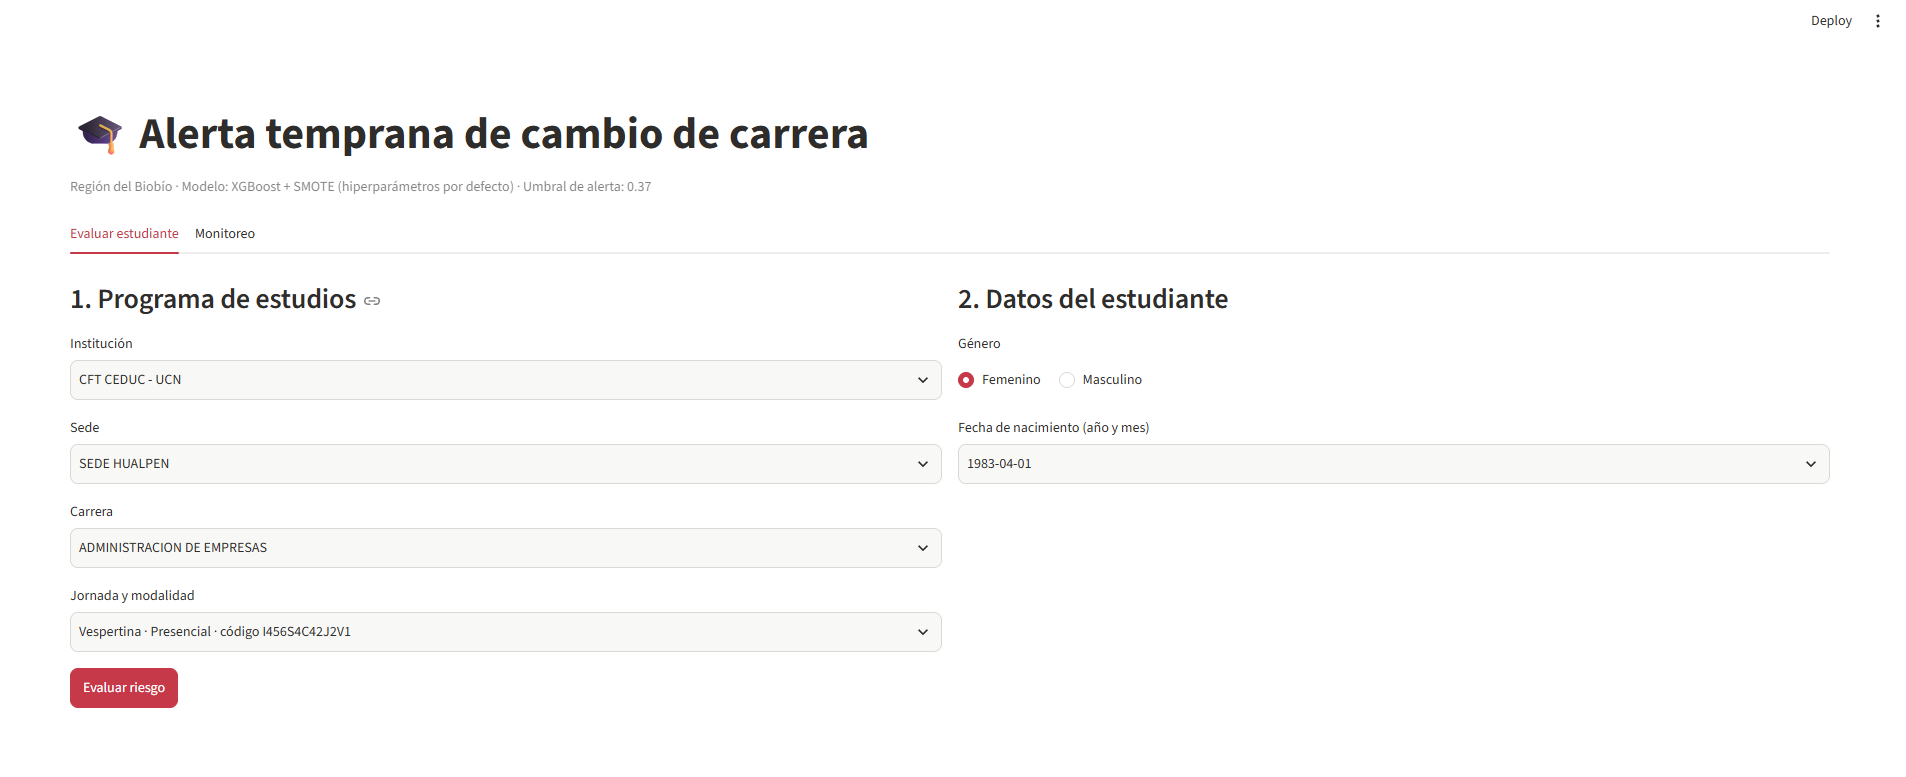

**Figura: Ejemplo 1, estudiante sin alerta**

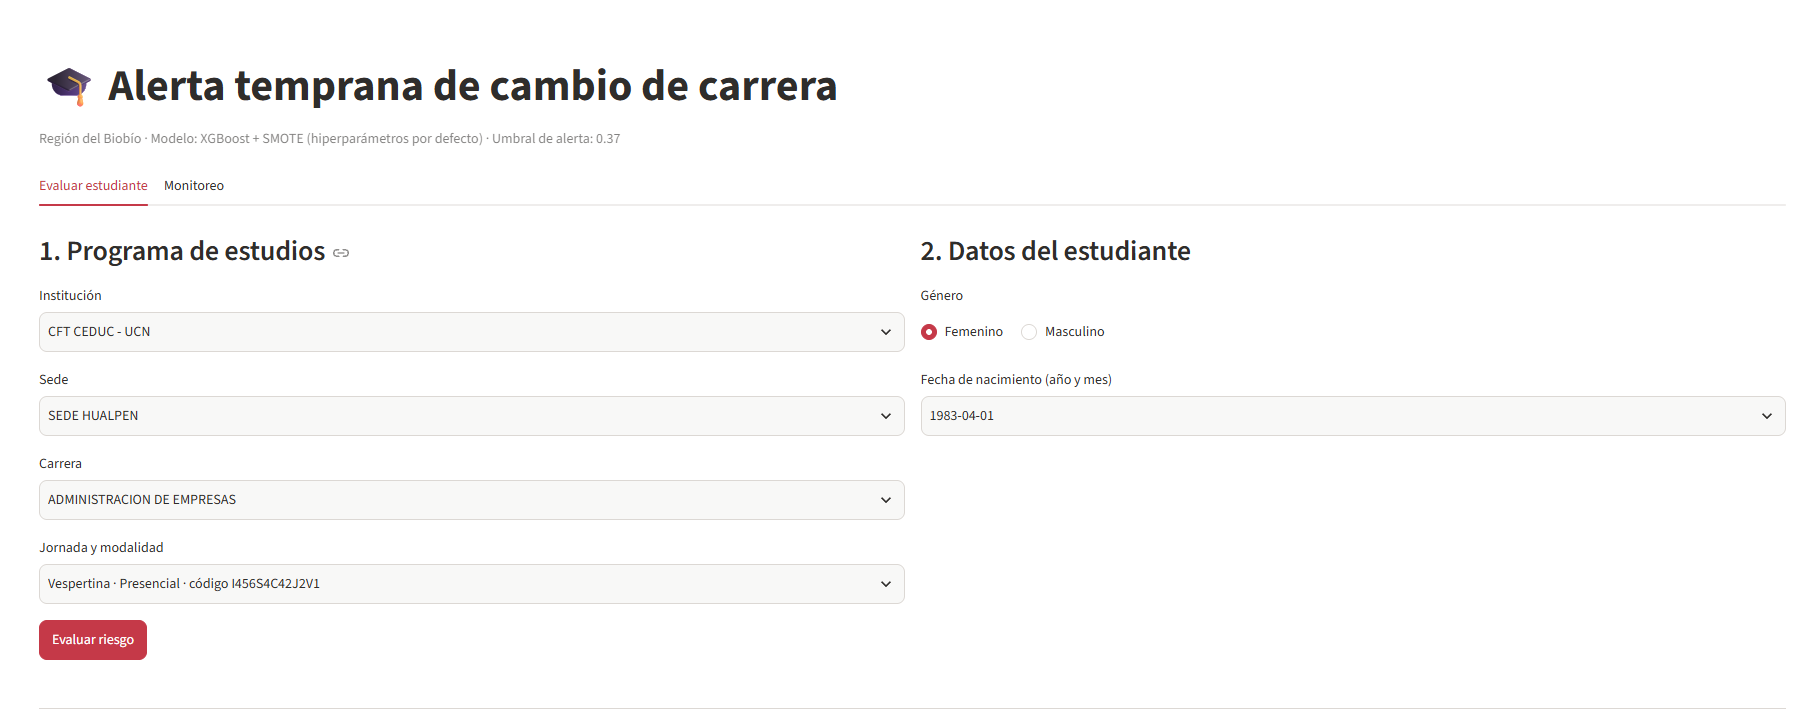

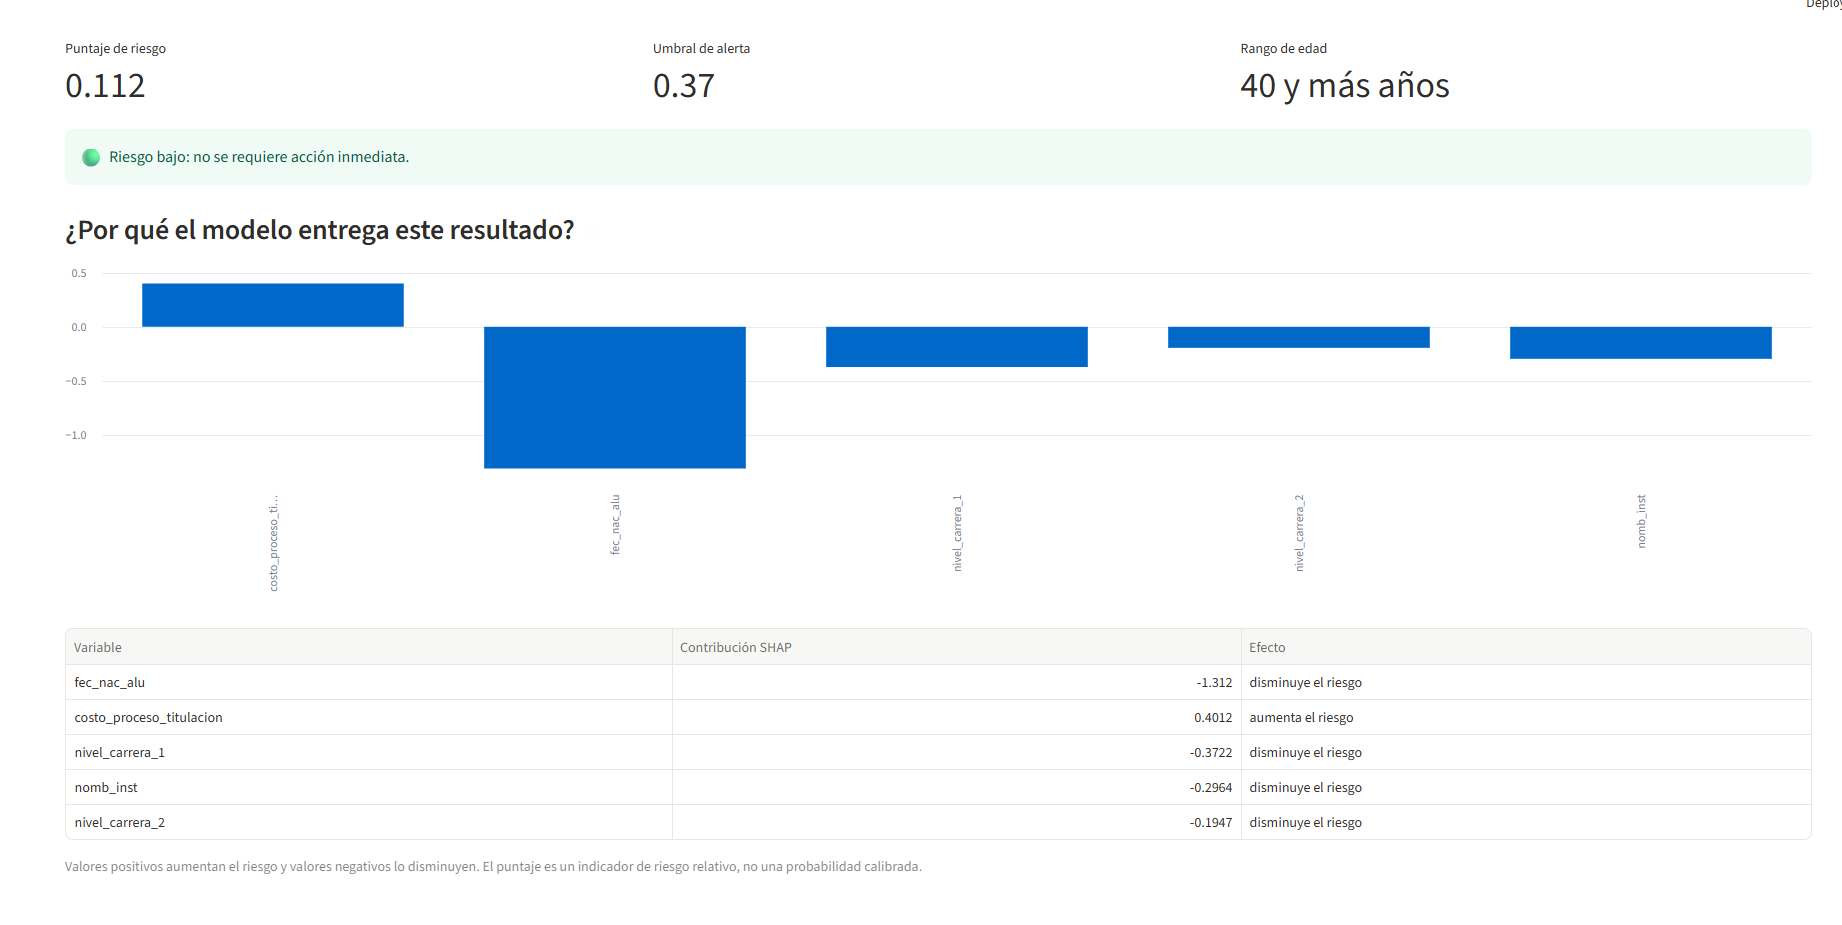



**Figura: Ejemplo 2, estudiante con alerta**

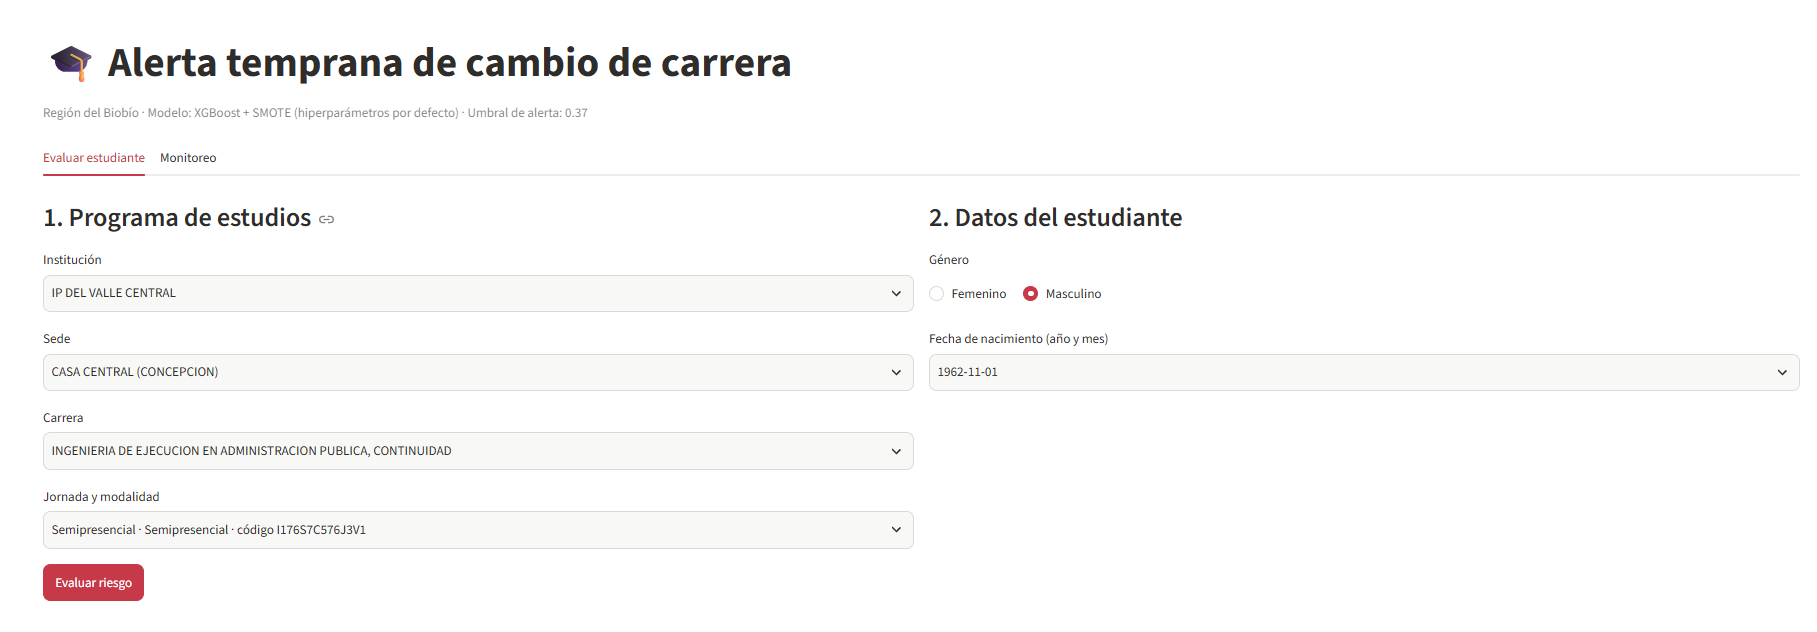

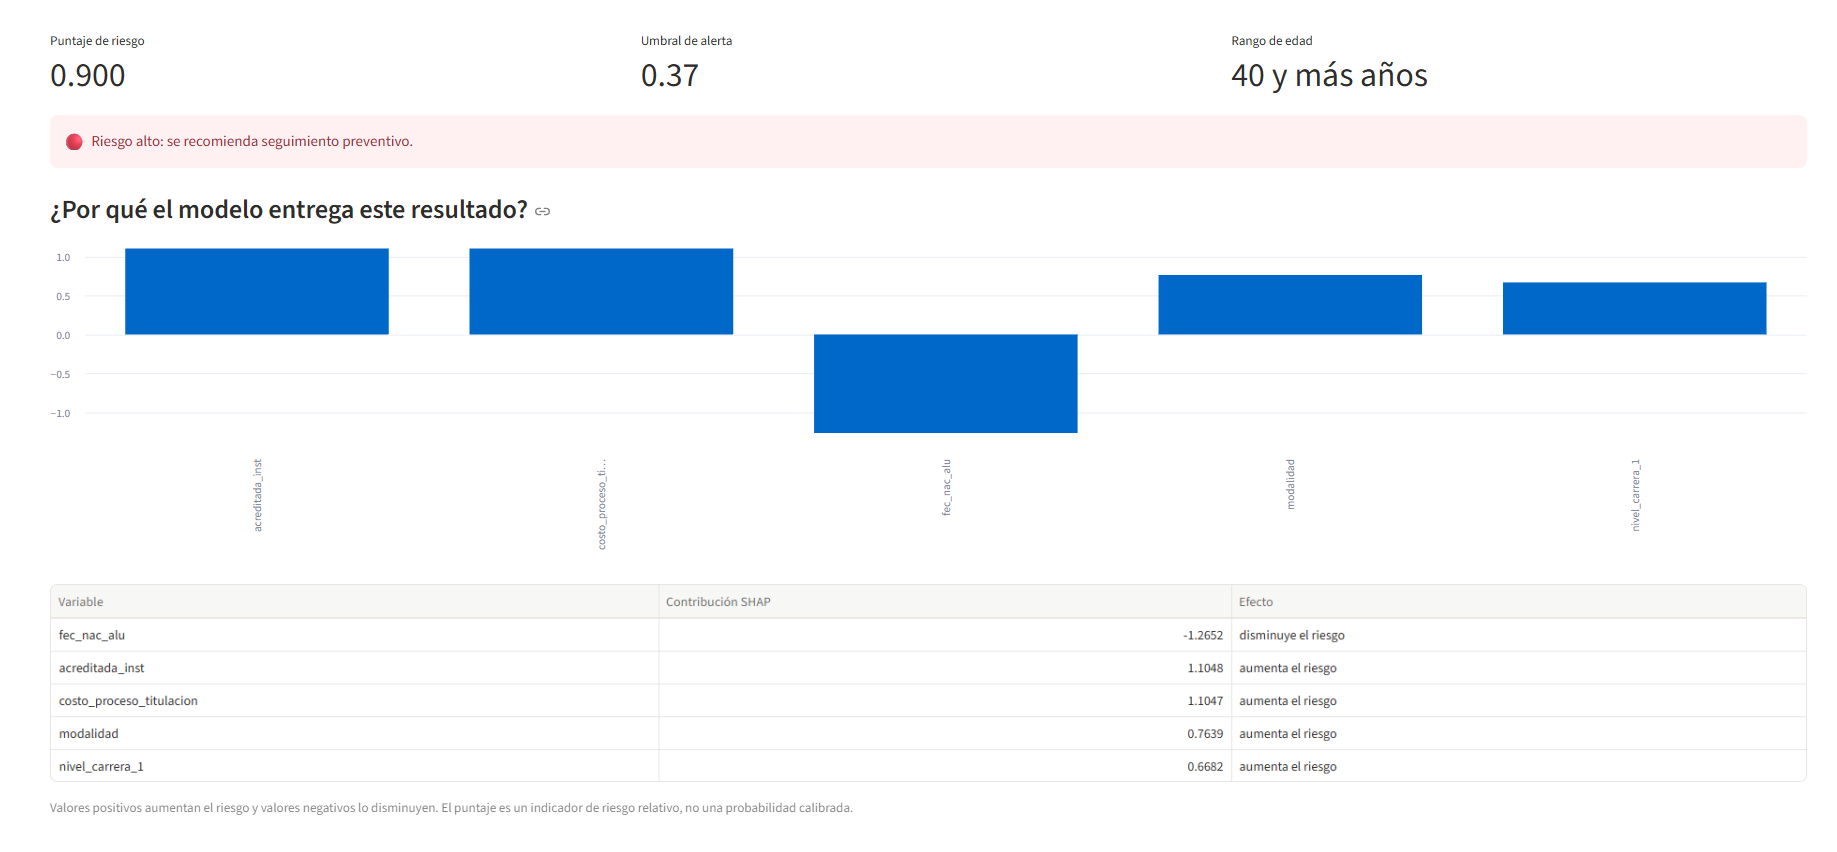



**Figura: Monitoreo de la aplicación**

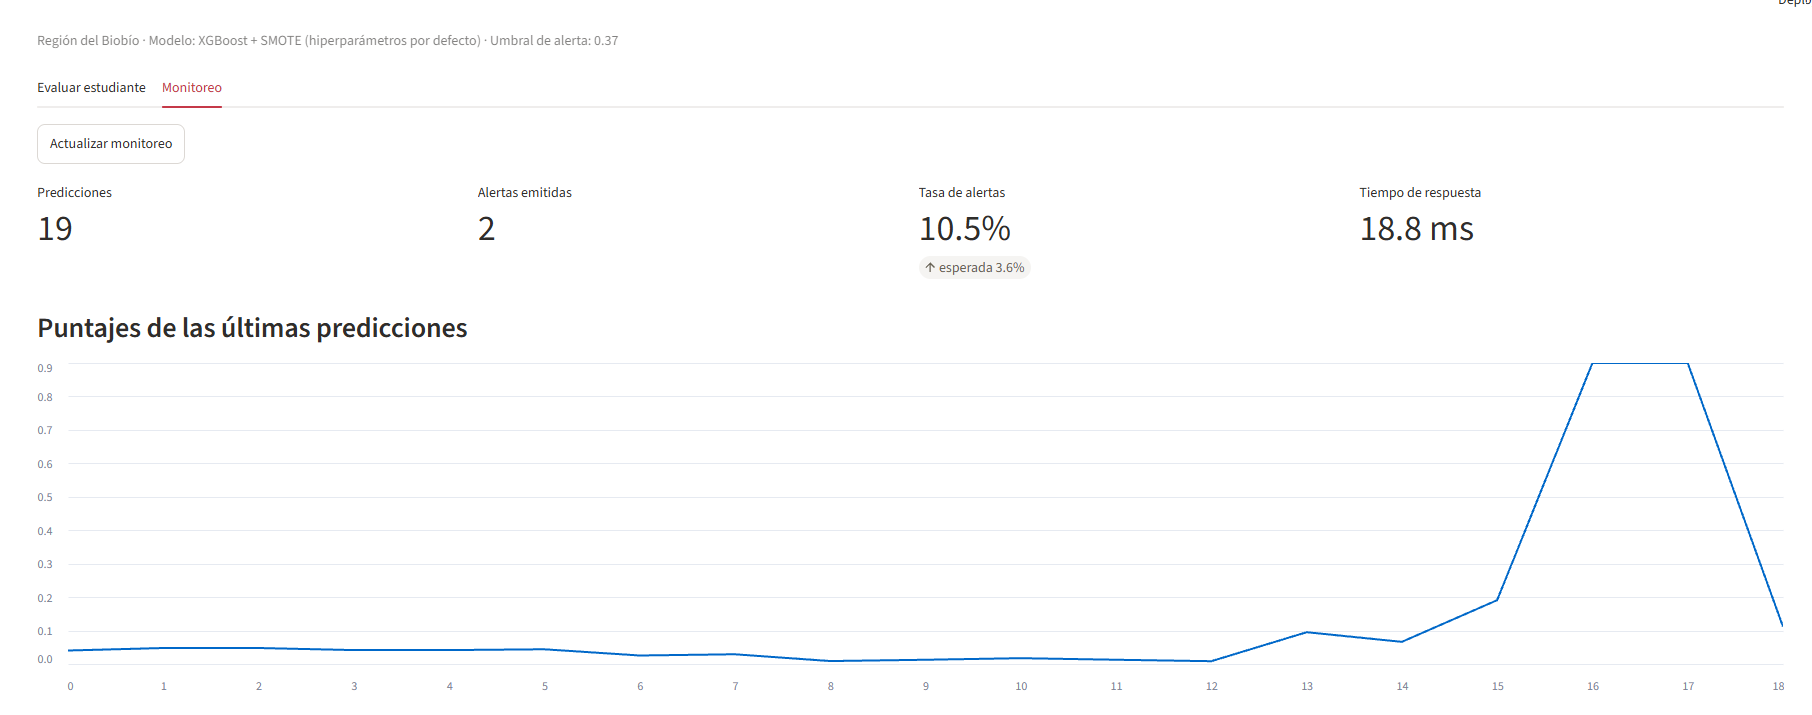

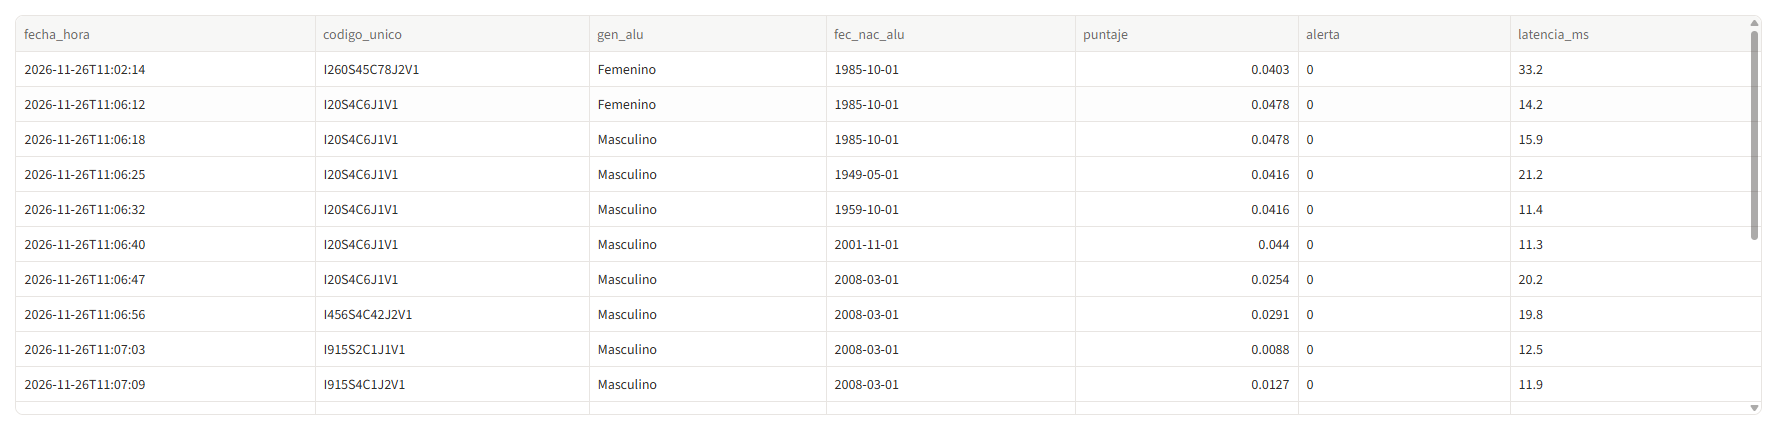

## 16. Conclusiones finales del proyecto

## 16. Conclusiones finales del proyecto

**Objetivo general.** El proyecto permitió desarrollar un proceso completo de aprendizaje automático para identificar tempranamente a estudiantes con riesgo de cambio de carrera en la Región del Biobío, utilizando datos abiertos de matrícula 2025 del Ministerio de Educación (136.290 registros). El proceso abarcó el análisis exploratorio, la preparación de los datos, la comparación de modelos de Machine Learning y Deep Learning, el refinamiento del modelo seleccionado, la interpretación de sus predicciones y su implementación en una aplicación funcional.

**Calidad y preparación de los datos.** El análisis exploratorio confirmó un buen nivel de calidad: no se encontraron registros duplicados, valores negativos ni inconsistencias de escritura, y los valores en cero de las variables de titulación tienen una explicación lógica. Se identificó un fuerte desbalance de clases (4,01 % de estudiantes con cambio de carrera) y se detectaron variables que generaban fuga de información: forma_ingreso, utilizada para construir la variable objetivo, y las variables de año y semestre de ingreso a la carrera de origen y actual, que permitían reconstruir directamente el cambio de carrera. Su exclusión fue fundamental para obtener un modelo realista, cuyas métricas reflejan su verdadera capacidad predictiva.

**Balanceo y modelos de Machine Learning.** Se compararon tres modelos (Regresión Logística, Random Forest y XGBoost) con cuatro estrategias de balanceo (sin balanceo, ROS, SMOTE y RUS), aplicadas dentro de un pipeline para que afectaran solo al conjunto de entrenamiento. El efecto del balanceo no fue uniforme: ROS y RUS aumentaron fuertemente el recall a costa de la precisión, mientras que SMOTE ofreció el mejor equilibrio en los modelos basados en árboles. La combinación XGBoost con SMOTE obtuvo el mayor F1-score en validación (0,3196) y uno de los menores tiempos de entrenamiento.

**Deep Learning.** Se evaluaron tres arquitecturas con la misma estrategia de entrenamiento (pesos de clase, Early Stopping y ajuste del umbral): un perceptrón multicapa (F1 = 0,3359), una red con embeddings para variables categóricas (F1 = 0,3102), que fue la más eficiente, y una ResNet tabular (F1 = 0,3209), que obtuvo el mayor AUC (0,8534). Las tres redes alcanzaron su mejor desempeño en las primeras épocas y luego mostraron sobreajuste, lo que se relaciona con el reducido número de casos positivos. Al aplicar el mismo ajuste de umbral, XGBoost con SMOTE superó a todas las redes en F1-score (0,3456), con un menor costo computacional y una interpretación más directa.

**Refinamiento y evaluación final.** La optimización de hiperparámetros mediante búsqueda aleatoria con validación cruzada no superó a la configuración por defecto de XGBoost, mientras que el ajuste del umbral de decisión a 0,37 resultó ser el refinamiento más efectivo. En el conjunto de prueba, con datos no utilizados durante el entrenamiento ni la selección, el modelo definitivo alcanzó una precisión de 0,3086, un recall de 0,2744, un F1-score de 0,2905 y un ROC AUC de 0,8312. En términos prácticos, cerca de 3 de cada 10 estudiantes señalados efectivamente cambian de carrera, casi 8 veces la tasa base, y el modelo detecta a más de un cuarto de los estudiantes que cambian de carrera.

**Interpretabilidad.** El análisis SHAP mostró que el modelo basa sus predicciones principalmente en la edad del estudiante y en las características del programa: costo del proceso de titulación, nivel de la carrera, jornada, modalidad y acreditación institucional. Los casos particulares evidenciaron que el modelo identifica bien a estudiantes adultos en programas de continuidad o en modalidades no tradicionales, pero no detecta cambios de carrera en estudiantes con trayectorias tradicionales, cuyas causas probablemente no están presentes en los datos.

**Aplicación.** El modelo se implementó en una aplicación de alerta temprana compuesta por un backend en FastAPI y un frontend en Streamlit. La aplicación permite evaluar a un estudiante seleccionando su programa y sus datos personales, entrega el puntaje de riesgo junto con la explicación SHAP de la predicción, admite predicciones por lotes y registra cada consulta para su monitoreo. Las pruebas confirmaron que la API reproduce exactamente las predicciones del notebook, con tiempos de respuesta de entre 16 y 50 milisegundos por estudiante.

**Limitaciones y trabajo futuro.** El desempeño del modelo es moderado, lo que es esperable en un problema sin fuga de información y con variables mayoritariamente institucionales. Como mejoras se proponen:
- incorporar variables académicas y socioeconómicas, como rendimiento, asistencia, puntaje de ingreso y beneficios estudiantiles;
- transformar la fecha de nacimiento en una variable numérica de edad y tratar los códigos institucionales como variables categóricas;
- eliminar variables redundantes o sin variación;
- optimizar los hiperparámetros con métodos más eficientes, como la optimización bayesiana, y calibrar las probabilidades del modelo;
- incorporar pruebas estadísticas de drift en el monitoreo;
- desplegar la aplicación en un servidor institucional.

En conjunto, el proyecto demuestra que es posible construir una herramienta interpretable y escalable para apoyar las estrategias de retención estudiantil, siempre como complemento al juicio de los equipos de acompañamiento y no como un mecanismo de decisión automática.